<a href="https://colab.research.google.com/github/akankshabhuyan-tech/PhishGuard_AIMLMiniProj26/blob/main/AIML_MiniProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

# ============================================
# STEP 1: UPLOAD PHIUSIIL DATASET FROM LAPTOP
# ============================================

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)


Saving PhiUSIIL_Phishing_URL_Dataset.csv to PhiUSIIL_Phishing_URL_Dataset.csv

Uploaded files:
PhiUSIIL_Phishing_URL_Dataset.csv


In [4]:

# ============================================
# STEP 2: LOAD PHIUSIIL DATASET
# ============================================

import pandas as pd

filename = next(iter(uploaded.keys()))

df = pd.read_csv(filename, low_memory=False)

print("Dataset successfully loaded!")
print("=" * 60)

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset successfully loaded!
Dataset shape: (235795, 56)

First 5 rows:


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1



Column names:
['FILENAME', 'URL', 'URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'TLD', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef', 'label']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeI

In [5]:

# ============================================
# STEP 3: BASIC DATASET INSPECTION
# ============================================

print("DATASET DIMENSIONS")
print(df.shape)

print("\nMISSING VALUES")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

print("\nTARGET DISTRIBUTION")
print(df["label"].value_counts(dropna=False))

print("\nTARGET PERCENTAGES")
print(df["label"].value_counts(normalize=True) * 100)


DATASET DIMENSIONS
(235795, 56)

MISSING VALUES
FILENAME                0
URL                     0
URLLength               0
Domain                  0
DomainLength            0
IsDomainIP              0
TLD                     0
URLSimilarityIndex      0
CharContinuationRate    0
TLDLegitimateProb       0
URLCharProb             0
TLDLength               0
NoOfSubDomain           0
HasObfuscation          0
NoOfObfuscatedChar      0
dtype: int64

DUPLICATE ROWS
0

TARGET DISTRIBUTION
label
1    134850
0    100945
Name: count, dtype: int64

TARGET PERCENTAGES
label
1    57.189508
0    42.810492
Name: proportion, dtype: float64


In [6]:

# =========================================================
# STEP 4: DATASET CLEANING AND QUALITY AUDIT
# =========================================================

import pandas as pd
import numpy as np

# Preserve the original dataset
df_raw = df.copy()

# Work on a separate copy
df_clean = df_raw.copy()

print("=" * 65)
print("PHISHGUARD - DATASET PREPROCESSING")
print("=" * 65)

# 1. Clean whitespace in text columns
text_columns = df_clean.select_dtypes(include=["object"]).columns

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

print("\n1. TEXT CLEANING COMPLETED")
print("Text columns cleaned:", list(text_columns))

# 2. Dataset dimensions
print("\n2. DATASET DIMENSIONS")
print("Original shape:", df_raw.shape)
print("Current shape:", df_clean.shape)

# 3. Missing values
print("\n3. MISSING VALUE AUDIT")
missing = df_clean.isnull().sum()
print("Total missing values:", missing.sum())
print(missing[missing > 0].sort_values(ascending=False))

# 4. Target label verification
print("\n4. TARGET LABEL AUDIT")
print(df_clean["label"].value_counts(dropna=False).sort_index())

print("\nTarget percentages:")
print(
    (df_clean["label"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

# 5. Invalid target labels
valid_labels = {0, 1}
invalid_labels = set(df_clean["label"].dropna().unique()) - valid_labels

print("\n5. INVALID LABEL CHECK")
print("Invalid labels:", invalid_labels)

# 6. Exact duplicate rows
print("\n6. EXACT DUPLICATE ROW AUDIT")
print("Exact duplicate rows:", df_clean.duplicated().sum())

# 7. Duplicate URL audit
print("\n7. DUPLICATE URL AUDIT")

print("Missing URLs:", df_clean["URL"].isna().sum())
print("Empty URLs:", (df_clean["URL"] == "").sum())

print("Duplicate URL rows:", df_clean["URL"].duplicated().sum())
print("Unique URLs:", df_clean["URL"].nunique())

# 8. Check URLs associated with conflicting labels
url_label_counts = (
    df_clean.dropna(subset=["URL", "label"])
    .groupby("URL")["label"]
    .nunique()
)

conflicting_urls = url_label_counts[url_label_counts > 1]

print("\n8. CONFLICTING URL LABEL AUDIT")
print("URLs with conflicting labels:", len(conflicting_urls))

if len(conflicting_urls) > 0:
    print("\nExamples:")
    print(
        df_clean[df_clean["URL"].isin(conflicting_urls.index)]
        [["URL", "label"]]
        .head(10)
    )

# 9. Duplicate records by URL
print("\n9. DUPLICATE RECORD SUMMARY")
print("Total records:", len(df_clean))
print("Unique URL values:", df_clean["URL"].nunique())
print("Repeated URL records:", df_clean["URL"].duplicated().sum())

print("\nAUDIT COMPLETED")


PHISHGUARD - DATASET PREPROCESSING

1. TEXT CLEANING COMPLETED
Text columns cleaned: ['FILENAME', 'URL', 'Domain', 'TLD', 'Title']

2. DATASET DIMENSIONS
Original shape: (235795, 56)
Current shape: (235795, 56)

3. MISSING VALUE AUDIT
Total missing values: 0
Series([], dtype: int64)

4. TARGET LABEL AUDIT
label
0    100945
1    134850
Name: count, dtype: int64

Target percentages:
label
0    42.81
1    57.19
Name: proportion, dtype: float64

5. INVALID LABEL CHECK
Invalid labels: set()

6. EXACT DUPLICATE ROW AUDIT
Exact duplicate rows: 0

7. DUPLICATE URL AUDIT
Missing URLs: 0
Empty URLs: 0
Duplicate URL rows: 425
Unique URLs: 235370

8. CONFLICTING URL LABEL AUDIT
URLs with conflicting labels: 0

9. DUPLICATE RECORD SUMMARY
Total records: 235795
Unique URL values: 235370
Repeated URL records: 425

AUDIT COMPLETED


In [7]:
# =========================================================
# STEP 5: DEFINE URL FEATURES AND AUDIT DUPLICATE CONSISTENCY
# =========================================================

url_features = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS"
]

# Check that all required URL features exist
missing_features = [
    col for col in url_features
    if col not in df_clean.columns
]

print("Number of URL features:", len(url_features))
print("Missing URL features:", missing_features)

# Select rows containing repeated URLs
duplicate_url_data = df_clean[
    df_clean.duplicated(subset="URL", keep=False)
].copy()

# Check whether URL features vary for the same URL
feature_variation = (
    duplicate_url_data
    .groupby("URL")[url_features]
    .nunique()
)

# Find URLs with at least one inconsistent URL feature
inconsistent_urls = feature_variation[
    feature_variation.gt(1).any(axis=1)
]

print("\nDUPLICATE URL FEATURE CONSISTENCY AUDIT")
print("Repeated URL groups:", len(feature_variation))
print("URLs with inconsistent URL features:", len(inconsistent_urls))

if len(inconsistent_urls) > 0:
    print("\nExamples of inconsistent URLs:")
    print(
        duplicate_url_data[
            duplicate_url_data["URL"].isin(inconsistent_urls.index)
        ][["URL"] + url_features].head(10)
    )
else:
    print("All repeated URLs have consistent URL feature values.")

print("\nSTEP 5 AUDIT COMPLETED")

Number of URL features: 18
Missing URL features: []

DUPLICATE URL FEATURE CONSISTENCY AUDIT
Repeated URL groups: 425
URLs with inconsistent URL features: 425

Examples of inconsistent URLs:
                                                    URL  URLLength  \
87                   https://att-104164.weeblysite.com/         34   
978   https://etiliseramik.com/wp-includes/vector/lo...         52   
1636  https://snapdragon-magic-flag.glitch.me/navyfe...         59   
2474             http://my-business-108580.square.site/         37   
2543  https://facebook-help-600674518635606.firebase...         54   
2583  http://splaudioprofessional.com/wp-content/net...         49   
2852  https://objectstorage.ap-singapore-1.oracleclo...        120   
3055               https://yahoo-109157.weeblysite.com/         35   
3393                       https://www.ak3.duckdns.org/         28   
3403          https://dev-itaupysegura.pantheonsite.io/         40   

      DomainLength  IsDomainIP  TLDLen

In [8]:
# =========================================================
# STEP 6: INVESTIGATE INCONSISTENT DUPLICATE URL RECORDS
# =========================================================

import pandas as pd

# 1. Count how often each URL feature differs
variation_counts = (
    feature_variation
    .gt(1)
    .sum()
    .sort_values(ascending=False)
)

print("=" * 65)
print("URL FEATURES WITH DIFFERING VALUES")
print("=" * 65)
print(variation_counts[variation_counts > 0])

# 2. Select three repeated URLs for detailed inspection
sample_urls = list(inconsistent_urls.index[:3])

# 3. Display their complete URL-feature records
for i, sample_url in enumerate(sample_urls, start=1):

    print("\n" + "=" * 65)
    print(f"DUPLICATE URL EXAMPLE {i}")
    print("=" * 65)

    print("URL:", sample_url)

    sample_records = df_clean[
        df_clean["URL"] == sample_url
    ][["URL", "label"] + url_features]

    print("Number of records:", len(sample_records))
    display(sample_records.T)

# 4. Check whether the repeated records have different labels
print("\n" + "=" * 65)
print("LABEL CONSISTENCY")
print("=" * 65)

print(
    df_clean[
        df_clean["URL"].isin(inconsistent_urls.index)
    ].groupby("URL")["label"].nunique().value_counts()
)

print("\nINVESTIGATION COMPLETED")

URL FEATURES WITH DIFFERING VALUES
URLLength                     425
LetterRatioInURL              424
SpacialCharRatioInURL         407
NoOfOtherSpecialCharsInURL    289
DegitRatioInURL               250
NoOfLettersInURL              129
NoOfDegitsInURL                 7
ObfuscationRatio                1
dtype: int64

DUPLICATE URL EXAMPLE 1
URL: http://2f3a.reicrut-chat.workers.dev/
Number of records: 2


,57609,219489
URL,http://2f3a.reicrut-chat.workers.dev/,http://2f3a.reicrut-chat.workers.dev/
label,0,0
URLLength,36,37
DomainLength,29,29
IsDomainIP,0,0
TLDLength,3,3
NoOfSubDomain,2,2
HasObfuscation,0,0
NoOfObfuscatedChar,0,0
ObfuscationRatio,0.0,0.0



DUPLICATE URL EXAMPLE 2
URL: http://34.149.138.117/
Number of records: 2


,27166,227564
URL,http://34.149.138.117/,http://34.149.138.117/
label,0,0
URLLength,22,21
DomainLength,14,14
IsDomainIP,1,1
TLDLength,3,3
NoOfSubDomain,2,2
HasObfuscation,0,0
NoOfObfuscatedChar,0,0
ObfuscationRatio,0.0,0.0



DUPLICATE URL EXAMPLE 3
URL: http://595221.selcdn.ru/qwerty-ohdhdjejnnad-najahhy/index4.html
Number of records: 2


,147448,189978
URL,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...,http://595221.selcdn.ru/qwerty-ohdhdjejnnad-na...
label,0,0
URLLength,62,63
DomainLength,16,16
IsDomainIP,0,0
TLDLength,2,2
NoOfSubDomain,1,1
HasObfuscation,0,0
NoOfObfuscatedChar,0,0
ObfuscationRatio,0.0,0.0



LABEL CONSISTENCY
label
1    425
Name: count, dtype: int64

INVESTIGATION COMPLETED


In [9]:

# =========================================================
# STEP 7: REMOVE DUPLICATE URL RECORDS
# =========================================================

print("=" * 65)
print("PHISHGUARD - DUPLICATE URL REMOVAL")
print("=" * 65)

# Preserve the full cleaned dataset for analysis
df_analysis = df_clean.copy()

# Remove repeated URLs, keeping the first occurrence
df_model = df_clean.drop_duplicates(
    subset="URL",
    keep="first"
).copy()

# Reset row indices
df_model.reset_index(drop=True, inplace=True)

# Check dataset dimensions
print("\nDATASET DIMENSIONS")
print("Before deduplication:", df_clean.shape)
print("After deduplication:", df_model.shape)

print("\nDUPLICATE REMOVAL SUMMARY")
print("Records removed:", len(df_clean) - len(df_model))
print("Unique URLs remaining:", df_model["URL"].nunique())
print("Remaining duplicate URLs:", df_model["URL"].duplicated().sum())

# Verify target labels
print("\nTARGET DISTRIBUTION AFTER DEDUPLICATION")
print(df_model["label"].value_counts().sort_index())

print("\nTARGET PERCENTAGES")
print(
    (df_model["label"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

# Verify dataset integrity
print("\nFINAL VALIDATION")
print("Missing values:", df_model.isnull().sum().sum())
print("Invalid labels:", set(df_model["label"].unique()) - {0, 1})
print("Duplicate URLs:", df_model["URL"].duplicated().sum())

print("\nSTEP 7 COMPLETED")


PHISHGUARD - DUPLICATE URL REMOVAL

DATASET DIMENSIONS
Before deduplication: (235795, 56)
After deduplication: (235370, 56)

DUPLICATE REMOVAL SUMMARY
Records removed: 425
Unique URLs remaining: 235370
Remaining duplicate URLs: 0

TARGET DISTRIBUTION AFTER DEDUPLICATION
label
0    100520
1    134850
Name: count, dtype: int64

TARGET PERCENTAGES
label
0    42.71
1    57.29
Name: proportion, dtype: float64

FINAL VALIDATION
Missing values: 0
Invalid labels: set()
Duplicate URLs: 0

STEP 7 COMPLETED


In [10]:

# =========================================================
# STEP 8: SELECT URL FEATURES AND TARGET VARIABLE
# =========================================================

# The 18 URL-derived features used by the live URL scanner
url_features = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS"
]

# Verify that all selected features exist
missing_features = [
    feature for feature in url_features
    if feature not in df_model.columns
]

if missing_features:
    raise ValueError(f"Missing URL features: {missing_features}")

# Input features
X = df_model[url_features].copy()

# Target variable
y = df_model["label"].astype(int).copy()

# Display dimensions
print("=" * 65)
print("PHISHGUARD - FEATURE AND TARGET SELECTION")
print("=" * 65)

print("\nNumber of selected URL features:", len(url_features))
print("Feature matrix X shape:", X.shape)
print("Target vector y shape:", y.shape)

print("\nSelected URL features:")
for i, feature in enumerate(url_features, start=1):
    print(f"{i:2}. {feature}")

print("\nTarget label mapping:")
print("0 = Phishing")
print("1 = Legitimate")

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nFeature data types:")
print(X.dtypes)

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nSTEP 8 COMPLETED")


PHISHGUARD - FEATURE AND TARGET SELECTION

Number of selected URL features: 18
Feature matrix X shape: (235370, 18)
Target vector y shape: (235370,)

Selected URL features:
 1. URLLength
 2. DomainLength
 3. IsDomainIP
 4. TLDLength
 5. NoOfSubDomain
 6. HasObfuscation
 7. NoOfObfuscatedChar
 8. ObfuscationRatio
 9. NoOfLettersInURL
10. LetterRatioInURL
11. NoOfDegitsInURL
12. DegitRatioInURL
13. NoOfEqualsInURL
14. NoOfQMarkInURL
15. NoOfAmpersandInURL
16. NoOfOtherSpecialCharsInURL
17. SpacialCharRatioInURL
18. IsHTTPS

Target label mapping:
0 = Phishing
1 = Legitimate

Target distribution:
label
0    100520
1    134850
Name: count, dtype: int64

Feature data types:
URLLength                       int64
DomainLength                    int64
IsDomainIP                      int64
TLDLength                       int64
NoOfSubDomain                   int64
HasObfuscation                  int64
NoOfObfuscatedChar              int64
ObfuscationRatio              float64
NoOfLettersInURL   

In [11]:
!pip -q install tldextract

In [12]:

# =========================================================
# STEP 9: EXTRACT REGISTERED DOMAINS
# =========================================================

import tldextract

# Use the offline suffix snapshot bundled with tldextract.
# This avoids relying on a live suffix-list download.
extractor = tldextract.TLDExtract(suffix_list_urls=None)

def get_registered_domain(url):
    try:
        result = extractor(url)
        if result.domain and result.suffix:
            return result.domain + "." + result.suffix
        return result.domain or ""
    except Exception:
        return ""

# Extract registered domain for every URL
df_model["registered_domain"] = df_model["URL"].apply(
    get_registered_domain
)

# Check extraction
print("=" * 65)
print("PHISHGUARD - REGISTERED DOMAIN EXTRACTION")
print("=" * 65)

print("\nTotal URLs:", len(df_model))
print("Unique registered domains:",
      df_model["registered_domain"].nunique())

print("Missing registered domains:",
      (df_model["registered_domain"] == "").sum())

print("\nSample domain extraction:")
print(df_model[["URL", "registered_domain"]].head(10))

# Verify no missing domain groups
if (df_model["registered_domain"] == "").any():
    raise ValueError(
        "Some URLs have no registered domain. Investigate before splitting."
    )

print("\nSTEP 9 COMPLETED")


PHISHGUARD - REGISTERED DOMAIN EXTRACTION

Total URLs: 235370
Unique registered domains: 175509
Missing registered domains: 0

Sample domain extraction:
                                  URL       registered_domain
0    https://www.southbankmosaics.com    southbankmosaics.com
1            https://www.uni-mainz.de            uni-mainz.de
2      https://www.voicefmradio.co.uk      voicefmradio.co.uk
3         https://www.sfnmjournal.com         sfnmjournal.com
4  https://www.rewildingargentina.org  rewildingargentina.org
5     https://www.globalreporting.org     globalreporting.org
6          https://www.saffronart.com          saffronart.com
7          https://www.nerdscandy.com          nerdscandy.com
8      https://www.hyderabadonline.in      hyderabadonline.in
9                 https://www.aap.org                 aap.org

STEP 9 COMPLETED


In [15]:

# =========================================================
# STEP 10 (REVISED): STRATIFIED GROUP-AWARE DATA SPLIT
# =========================================================

from sklearn.model_selection import StratifiedGroupKFold

# Registered domains must remain together
groups = df_model["registered_domain"].reset_index(drop=True)

# First split: approximately 12.5% test data
sgkf_test = StratifiedGroupKFold(
    n_splits=8,
    shuffle=True,
    random_state=42
)

dev_idx, test_idx = next(
    sgkf_test.split(X, y, groups=groups)
)

# Development data
X_dev = X.iloc[dev_idx].copy()
y_dev = y.iloc[dev_idx].copy()
groups_dev = groups.iloc[dev_idx].copy()

# Second split: approximately 20% of development data for validation
sgkf_val = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    sgkf_val.split(X_dev, y_dev, groups=groups_dev)
)

# Final datasets
X_train = X_dev.iloc[train_idx].copy()
y_train = y_dev.iloc[train_idx].copy()

X_val = X_dev.iloc[val_idx].copy()
y_val = y_dev.iloc[val_idx].copy()

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()

# Corresponding registered domains
train_domains = set(groups_dev.iloc[train_idx])
val_domains = set(groups_dev.iloc[val_idx])
test_domains = set(groups.iloc[test_idx])

# Display dimensions
print("=" * 65)
print("PHISHGUARD - STRATIFIED DOMAIN-AWARE SPLIT")
print("=" * 65)

for name, features, target, domains in [
    ("TRAINING", X_train, y_train, train_domains),
    ("VALIDATION", X_val, y_val, val_domains),
    ("TEST", X_test, y_test, test_domains)
]:
    print(f"\n{name} SET")
    print("Rows:", len(features))
    print("Unique domains:", len(domains))
    print("Class counts:")
    print(target.value_counts().sort_index())
    print("Class percentages:")
    print(
        (target.value_counts(normalize=True) * 100)
        .sort_index()
        .round(2)
    )

# Domain leakage audit
print("\nDOMAIN LEAKAGE AUDIT")

print("Train-Validation overlap:",
      len(train_domains & val_domains))

print("Train-Test overlap:",
      len(train_domains & test_domains))

print("Validation-Test overlap:",
      len(val_domains & test_domains))

# Overall verification
print("\nTOTAL ROWS:",
      len(X_train) + len(X_val) + len(X_test))

assert len(train_domains & val_domains) == 0
assert len(train_domains & test_domains) == 0
assert len(val_domains & test_domains) == 0

assert len(X_train) + len(X_val) + len(X_test) == len(X)

print("\nSTRATIFIED DOMAIN SPLIT VALIDATION PASSED")
print("STEP 10 COMPLETED")


PHISHGUARD - STRATIFIED DOMAIN-AWARE SPLIT

TRAINING SET
Rows: 164596
Unique domains: 122881
Class counts:
label
0    70192
1    94404
Name: count, dtype: int64
Class percentages:
label
0    42.65
1    57.35
Name: proportion, dtype: float64

VALIDATION SET
Rows: 41401
Unique domains: 30717
Class counts:
label
0    17712
1    23689
Name: count, dtype: int64
Class percentages:
label
0    42.78
1    57.22
Name: proportion, dtype: float64

TEST SET
Rows: 29373
Unique domains: 21911
Class counts:
label
0    12616
1    16757
Name: count, dtype: int64
Class percentages:
label
0    42.95
1    57.05
Name: proportion, dtype: float64

DOMAIN LEAKAGE AUDIT
Train-Validation overlap: 0
Train-Test overlap: 0
Validation-Test overlap: 0

TOTAL ROWS: 235370

STRATIFIED DOMAIN SPLIT VALIDATION PASSED
STEP 10 COMPLETED


In [16]:
!pip -q install xgboost

In [17]:

# =========================================================
# STEP 11A: IMPORT MACHINE-LEARNING LIBRARIES
# =========================================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

print("Machine-learning libraries imported successfully.")

print("\nDataset dimensions:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nFeature count:", len(url_features))
print("Phishing label: 0")
print("Legitimate label: 1")


Machine-learning libraries imported successfully.

Dataset dimensions:
Training: (164596, 18)
Validation: (41401, 18)
Testing: (29373, 18)

Feature count: 18
Phishing label: 0
Legitimate label: 1


In [18]:

# =========================================================
# STEP 11B: BASELINE MODEL TRAINING AND VALIDATION
# =========================================================

import time

# Ensure input data is numeric and finite
assert X_train.isna().sum().sum() == 0
assert X_val.isna().sum().sum() == 0
assert np.isfinite(X_train.to_numpy(dtype=float)).all()
assert np.isfinite(X_val.to_numpy(dtype=float)).all()

# Define the three models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )
}

results = []
trained_models = {}

print("=" * 65)
print("PHISHGUARD - BASELINE MODEL TRAINING")
print("=" * 65)

for name, model in models.items():

    print(f"\nTraining {name}...")

    start_time = time.time()

    # Train using training data only
    model.fit(X_train, y_train)

    training_time = time.time() - start_time

    # Validation predictions
    y_val_pred = model.predict(X_val)

    # Probability of phishing (class 0)
    class_0_index = list(model.classes_).index(0)
    y_val_phishing_prob = model.predict_proba(X_val)[:, class_0_index]

    # Calculate phishing-focused metrics
    accuracy = accuracy_score(y_val, y_val_pred)

    precision = precision_score(
        y_val, y_val_pred, pos_label=0, zero_division=0
    )

    recall = recall_score(
        y_val, y_val_pred, pos_label=0, zero_division=0
    )

    f1 = f1_score(
        y_val, y_val_pred, pos_label=0, zero_division=0
    )

    roc_auc = roc_auc_score(
        (y_val == 0).astype(int),
        y_val_phishing_prob
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Phishing Precision": precision,
        "Phishing Recall": recall,
        "Phishing F1": f1,
        "Phishing ROC-AUC": roc_auc,
        "Training Time (sec)": training_time
    })

    trained_models[name] = model

    print(f"{name} training completed.")
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Validation accuracy: {accuracy:.4f}")
    print(f"Phishing precision: {precision:.4f}")
    print(f"Phishing recall: {recall:.4f}")
    print(f"Phishing F1-score: {f1:.4f}")
    print(f"Phishing ROC-AUC: {roc_auc:.4f}")

# Create comparison table
model_comparison = pd.DataFrame(results)

model_comparison = model_comparison.sort_values(
    by="Phishing F1",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("VALIDATION MODEL COMPARISON")
print("=" * 65)

print(model_comparison.round(4).to_string(index=False))

print("\nSTEP 11 COMPLETED")


PHISHGUARD - BASELINE MODEL TRAINING

Training Logistic Regression...
Logistic Regression training completed.
Training time: 1.01 seconds
Validation accuracy: 0.9963
Phishing precision: 0.9995
Phishing recall: 0.9917
Phishing F1-score: 0.9956
Phishing ROC-AUC: 0.9984

Training Random Forest...
Random Forest training completed.
Training time: 23.80 seconds
Validation accuracy: 0.9975
Phishing precision: 0.9987
Phishing recall: 0.9955
Phishing F1-score: 0.9971
Phishing ROC-AUC: 0.9985

Training XGBoost...
XGBoost training completed.
Training time: 3.65 seconds
Validation accuracy: 0.9977
Phishing precision: 0.9995
Phishing recall: 0.9950
Phishing F1-score: 0.9973
Phishing ROC-AUC: 0.9989

VALIDATION MODEL COMPARISON
              Model  Accuracy  Phishing Precision  Phishing Recall  Phishing F1  Phishing ROC-AUC  Training Time (sec)
            XGBoost    0.9977              0.9995           0.9950       0.9973            0.9989               3.6505
      Random Forest    0.9975         

In [19]:

# =========================================================
# STEP 12: FINAL XGBOOST TEST EVALUATION
# =========================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Select the best validation model
best_model = trained_models["XGBoost"]

# Predict test labels
y_test_pred = best_model.predict(X_test)

# Get probability of phishing (class 0)
phishing_class_index = list(best_model.classes_).index(0)

y_test_phishing_prob = best_model.predict_proba(X_test)[
    :, phishing_class_index
]

# Calculate final metrics
test_accuracy = accuracy_score(y_test, y_test_pred)

test_precision = precision_score(
    y_test, y_test_pred, pos_label=0, zero_division=0
)

test_recall = recall_score(
    y_test, y_test_pred, pos_label=0, zero_division=0
)

test_f1 = f1_score(
    y_test, y_test_pred, pos_label=0, zero_division=0
)

test_roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    y_test_phishing_prob
)

# Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

print("=" * 65)
print("PHISHGUARD - FINAL TEST EVALUATION")
print("=" * 65)

print("\nSELECTED MODEL: XGBOOST")

print("\nFINAL TEST METRICS")
print(f"Accuracy:           {test_accuracy:.4f}")
print(f"Phishing Precision: {test_precision:.4f}")
print(f"Phishing Recall:    {test_recall:.4f}")
print(f"Phishing F1-score:  {test_f1:.4f}")
print(f"Phishing ROC-AUC:   {test_roc_auc:.4f}")

print("\nCONFUSION MATRIX")
print("Rows = Actual | Columns = Predicted")
print("Class 0 = Phishing | Class 1 = Legitimate")
print(cm)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        digits=4,
        zero_division=0
    )
)

# Store final metrics
test_metrics = {
    "Model": "XGBoost",
    "Accuracy": float(test_accuracy),
    "Phishing Precision": float(test_precision),
    "Phishing Recall": float(test_recall),
    "Phishing F1": float(test_f1),
    "Phishing ROC-AUC": float(test_roc_auc),
    "Confusion Matrix": cm.tolist()
}

print("\nSTEP 12 COMPLETED")


PHISHGUARD - FINAL TEST EVALUATION

SELECTED MODEL: XGBOOST

FINAL TEST METRICS
Accuracy:           0.9974
Phishing Precision: 0.9994
Phishing Recall:    0.9946
Phishing F1-score:  0.9970
Phishing ROC-AUC:   0.9988

CONFUSION MATRIX
Rows = Actual | Columns = Predicted
Class 0 = Phishing | Class 1 = Legitimate
[[12548    68]
 [    8 16749]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Phishing     0.9994    0.9946    0.9970     12616
  Legitimate     0.9960    0.9995    0.9977     16757

    accuracy                         0.9974     29373
   macro avg     0.9977    0.9971    0.9974     29373
weighted avg     0.9974    0.9974    0.9974     29373


STEP 12 COMPLETED


Calculating permutation importance...
This may take a little time.

PHISHGUARD - FEATURE IMPORTANCE RESULTS
                   Feature  XGBoost Importance  Permutation Importance  Importance Std
                   IsHTTPS            0.563347                0.271864        0.000526
                 URLLength            0.015804                0.228880        0.000934
              DomainLength            0.002494                0.215996        0.001092
          LetterRatioInURL            0.011983                0.192495        0.000891
             NoOfSubDomain            0.031189                0.049196        0.000509
NoOfOtherSpecialCharsInURL            0.339068                0.031893        0.001068
           NoOfDegitsInURL            0.017864                0.010440        0.000459
           DegitRatioInURL            0.004820                0.003270        0.000415
          NoOfLettersInURL            0.003049                0.000834        0.000117
     SpacialCharRatioI

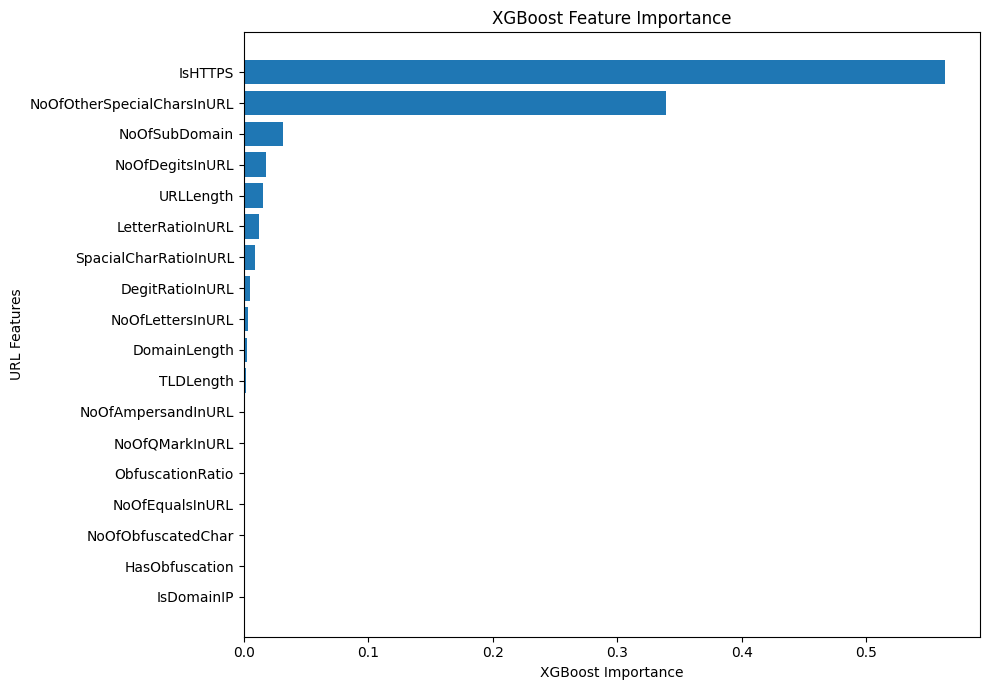

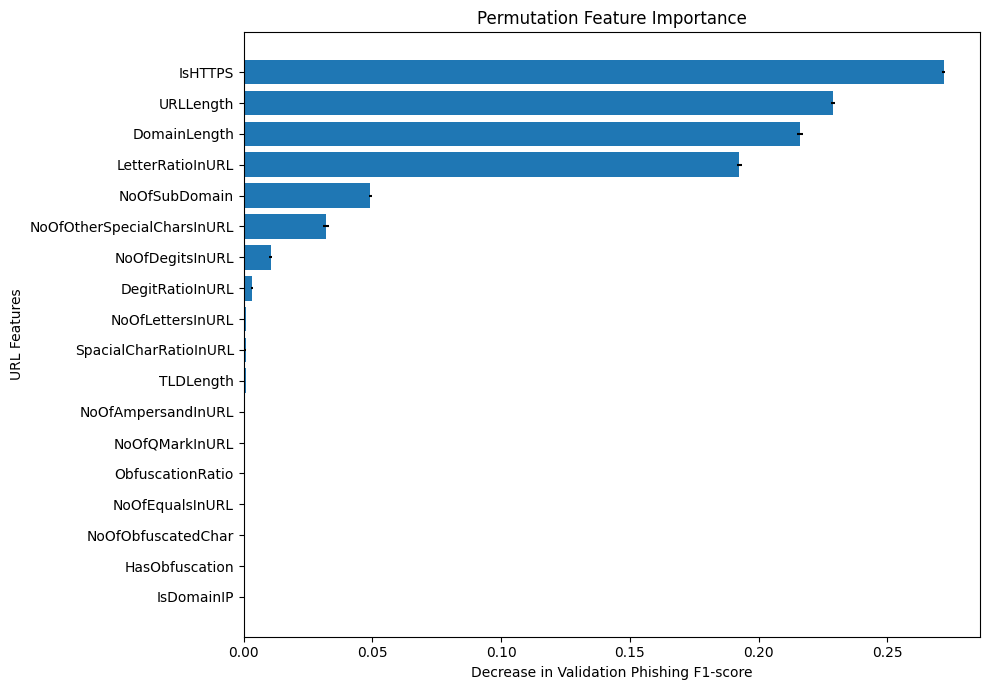


Saved: feature_importance_results.csv

STEP 13A COMPLETED


In [20]:

# =========================================================
# STEP 13A: XGBOOST AND PERMUTATION FEATURE IMPORTANCE
# =========================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, f1_score

# ---------------------------------------------------------
# 1. XGBOOST FEATURE IMPORTANCE
# ---------------------------------------------------------

xgb_importance = best_model.feature_importances_

xgb_importance_df = pd.DataFrame({
    "Feature": url_features,
    "XGBoost Importance": xgb_importance
})

xgb_importance_df = xgb_importance_df.sort_values(
    by="XGBoost Importance",
    ascending=False
).reset_index(drop=True)

# ---------------------------------------------------------
# 2. PERMUTATION IMPORTANCE ON VALIDATION DATA
# ---------------------------------------------------------

# Phishing (label 0) is treated as the positive class
phishing_f1_scorer = make_scorer(
    f1_score,
    pos_label=0,
    zero_division=0
)

print("Calculating permutation importance...")
print("This may take a little time.")

permutation_result = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring=phishing_f1_scorer,
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": url_features,
    "Permutation Importance": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by="Permutation Importance",
    ascending=False
).reset_index(drop=True)

# ---------------------------------------------------------
# 3. COMBINE BOTH RESULTS
# ---------------------------------------------------------

feature_importance_df = xgb_importance_df.merge(
    permutation_df,
    on="Feature"
)

feature_importance_df = feature_importance_df.sort_values(
    by="Permutation Importance",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("PHISHGUARD - FEATURE IMPORTANCE RESULTS")
print("=" * 75)

print(
    feature_importance_df.round(6).to_string(index=False)
)

print("\nTOP 10 FEATURES BY XGBOOST IMPORTANCE")
print(
    xgb_importance_df.head(10).round(6).to_string(index=False)
)

print("\nTOP 10 FEATURES BY PERMUTATION IMPORTANCE")
print(
    permutation_df.head(10).round(6).to_string(index=False)
)

# ---------------------------------------------------------
# 4. VISUALIZE XGBOOST IMPORTANCE
# ---------------------------------------------------------

plt.figure(figsize=(10, 7))

plot_data = xgb_importance_df.sort_values(
    by="XGBoost Importance",
    ascending=True
)

plt.barh(
    plot_data["Feature"],
    plot_data["XGBoost Importance"]
)

plt.xlabel("XGBoost Importance")
plt.ylabel("URL Features")
plt.title("XGBoost Feature Importance")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 5. VISUALIZE PERMUTATION IMPORTANCE
# ---------------------------------------------------------

plt.figure(figsize=(10, 7))

plot_data = permutation_df.sort_values(
    by="Permutation Importance",
    ascending=True
)

plt.barh(
    plot_data["Feature"],
    plot_data["Permutation Importance"],
    xerr=plot_data["Importance Std"]
)

plt.xlabel("Decrease in Validation Phishing F1-score")
plt.ylabel("URL Features")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 6. SAVE RESULTS
# ---------------------------------------------------------

feature_importance_df.to_csv(
    "feature_importance_results.csv",
    index=False
)

print("\nSaved: feature_importance_results.csv")
print("\nSTEP 13A COMPLETED")


SHAP version: 0.54.1
SHAP sample shape: (1000, 18)

SHAP calculation completed.
SHAP values shape: (1000, 18)
Feature count: 18

PHISHGUARD - GLOBAL SHAP FEATURE IMPORTANCE
                   Feature  Mean Absolute SHAP
                   IsHTTPS            3.540195
              DomainLength            2.839605
          LetterRatioInURL            2.057456
                 URLLength            2.003629
NoOfOtherSpecialCharsInURL            1.789615
           NoOfDegitsInURL            0.673330
           DegitRatioInURL            0.476442
          NoOfLettersInURL            0.469966
             NoOfSubDomain            0.366078
     SpacialCharRatioInURL            0.312809
                 TLDLength            0.176502
          ObfuscationRatio            0.000000
                IsDomainIP            0.000000
            HasObfuscation            0.000000
        NoOfObfuscatedChar            0.000000
           NoOfEqualsInURL            0.000000
            NoOfQMarkInURL  

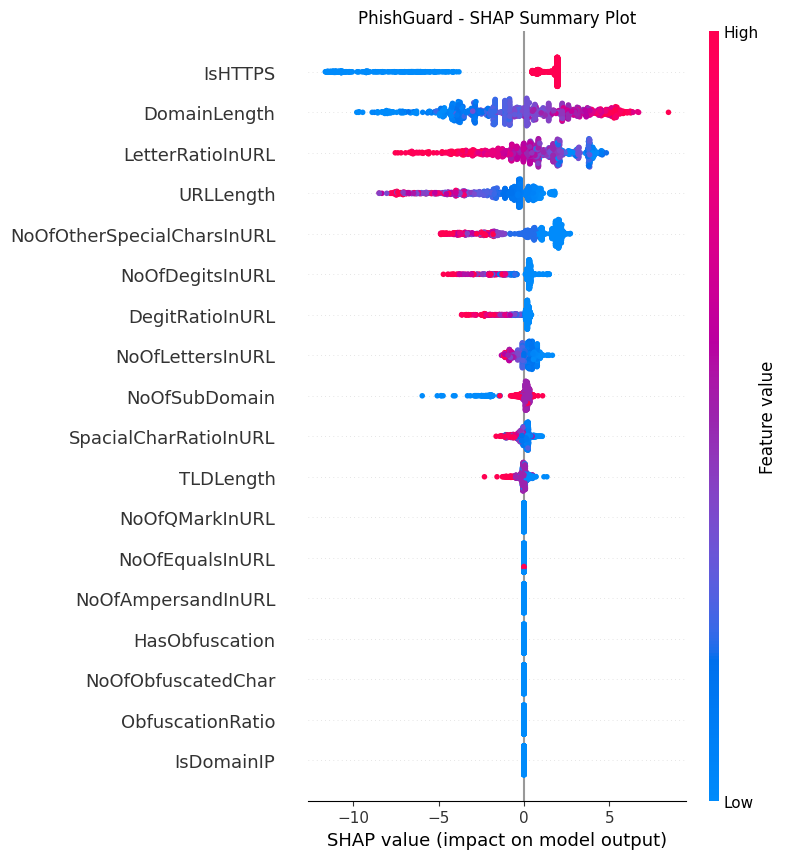

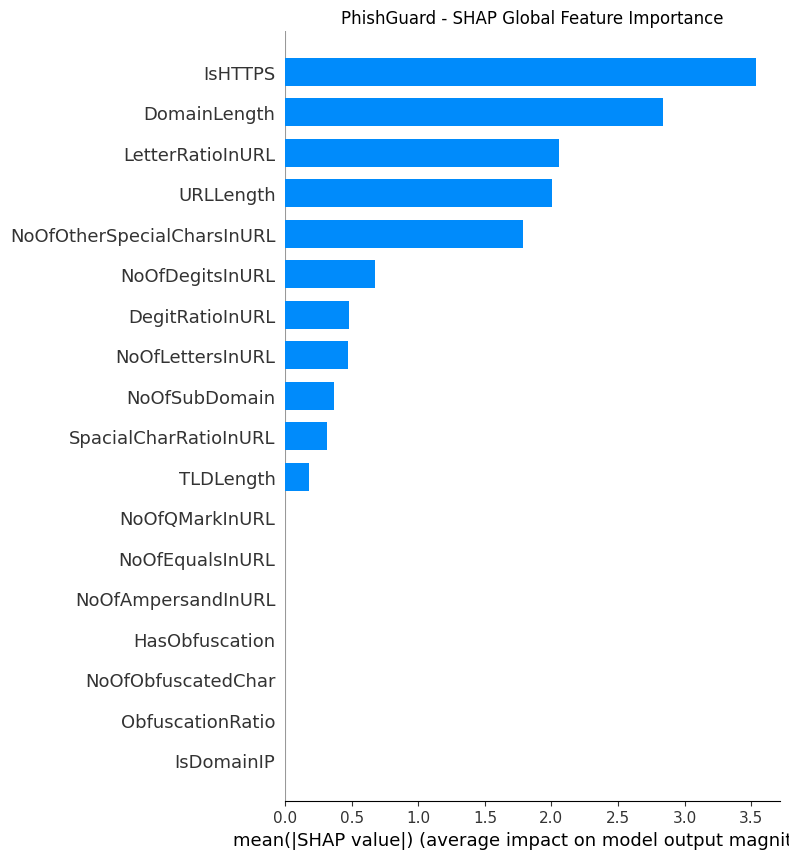


STEP 14A COMPLETED


In [21]:

# STEP 14A: SHAP EXPLAINABILITY

!pip -q install shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

# Use a reproducible sample from validation data
X_shap = X_val.sample(
    n=min(1000, len(X_val)),
    random_state=42
).copy()

print("SHAP sample shape:", X_shap.shape)

# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(best_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[0]

shap_values = np.asarray(shap_values)

print("\nSHAP calculation completed.")
print("SHAP values shape:", shap_values.shape)
print("Feature count:", len(url_features))

# Global feature importance using mean absolute SHAP values
shap_importance_df = pd.DataFrame({
    "Feature": url_features,
    "Mean Absolute SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values(
    by="Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("PHISHGUARD - GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 75)

print(shap_importance_df.to_string(index=False))

# Save SHAP importance
shap_importance_df.to_csv(
    "shap_feature_importance.csv",
    index=False
)

print("\nSaved: shap_feature_importance.csv")

# SHAP summary plot
plt.figure()
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=url_features,
    show=False,
    max_display=18
)
plt.title("PhishGuard - SHAP Summary Plot")
plt.tight_layout()
plt.savefig(
    "shap_summary_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# SHAP global bar plot
plt.figure()
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=url_features,
    plot_type="bar",
    show=False,
    max_display=18
)
plt.title("PhishGuard - SHAP Global Feature Importance")
plt.tight_layout()
plt.savefig(
    "shap_bar_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nSTEP 14A COMPLETED")


INDIVIDUAL URL EXPLANATION
Actual class: Phishing
Predicted class: Phishing
Phishing probability: 100.0000%
Legitimate probability: 0.0000%


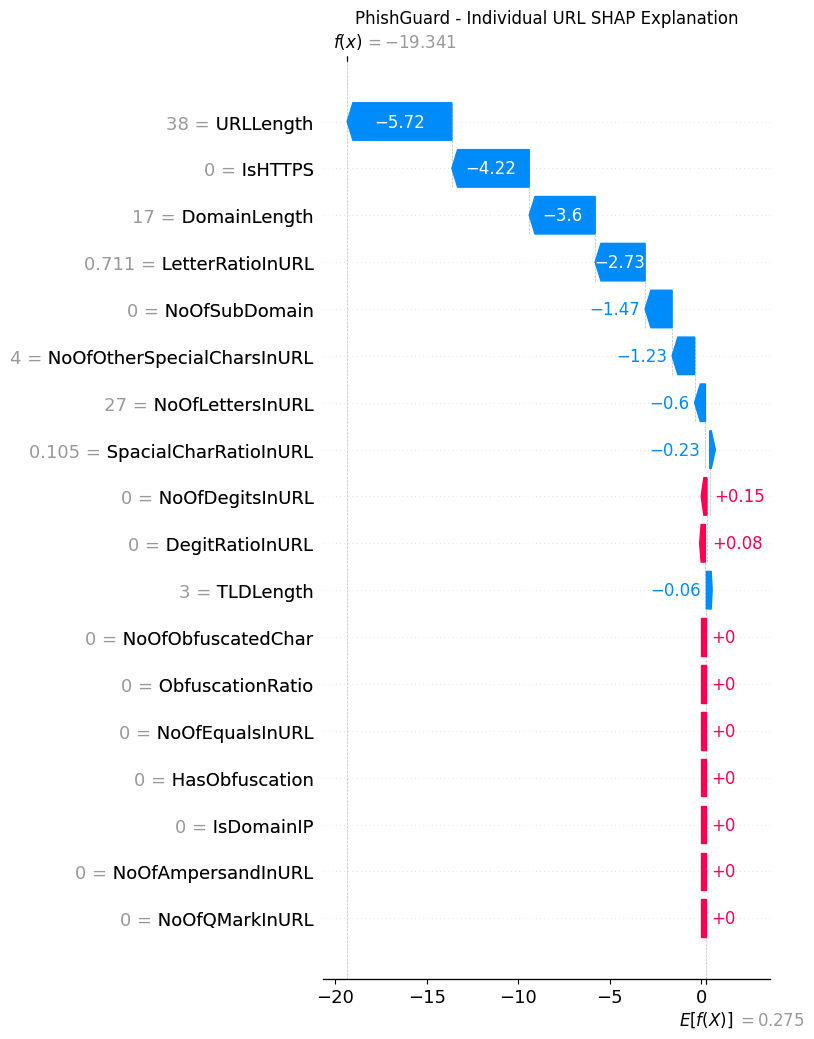


Top contributing features:
                   Feature  Feature Value  SHAP Contribution  Absolute Contribution
                 URLLength         38.000          -5.716936               5.716936
                   IsHTTPS          0.000          -4.223644               4.223644
              DomainLength         17.000          -3.601609               3.601609
          LetterRatioInURL          0.711          -2.727317               2.727317
             NoOfSubDomain          0.000          -1.472377               1.472377
NoOfOtherSpecialCharsInURL          4.000          -1.226608               1.226608
          NoOfLettersInURL         27.000          -0.595460               0.595460
     SpacialCharRatioInURL          0.105          -0.227722               0.227722
           NoOfDegitsInURL          0.000           0.147347               0.147347
           DegitRatioInURL          0.000           0.083667               0.083667

Saved:
- individual_url_shap_waterfall.png
- in

In [22]:

# STEP 14B: INDIVIDUAL URL SHAP EXPLANATION

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# Select one validation example
sample_index = 0

sample = X_shap.iloc[[sample_index]].copy()

# Actual and predicted labels
actual_label = int(y_val.loc[sample.index[0]])
predicted_label = int(best_model.predict(sample)[0])

# Probabilities
probabilities = best_model.predict_proba(sample)[0]

phishing_probability = probabilities[0]  # Class 0
legitimate_probability = probabilities[1]  # Class 1

print("=" * 65)
print("INDIVIDUAL URL EXPLANATION")
print("=" * 65)

print("Actual class:",
      "Phishing" if actual_label == 0 else "Legitimate")

print("Predicted class:",
      "Phishing" if predicted_label == 0 else "Legitimate")

print(f"Phishing probability: {phishing_probability:.4%}")
print(f"Legitimate probability: {legitimate_probability:.4%}")

# Get SHAP base value safely
base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[0]

# Create SHAP explanation for the selected example
individual_explanation = shap.Explanation(
    values=shap_values[sample_index],
    base_values=float(base_value),
    data=sample.iloc[0].values,
    feature_names=url_features
)

# Display waterfall plot
plt.figure(figsize=(10, 7))

shap.plots.waterfall(
    individual_explanation,
    max_display=18,
    show=False
)

plt.title("PhishGuard - Individual URL SHAP Explanation")
plt.tight_layout()

plt.savefig(
    "individual_url_shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save individual feature contributions
individual_shap_df = pd.DataFrame({
    "Feature": url_features,
    "Feature Value": sample.iloc[0].values,
    "SHAP Contribution": shap_values[sample_index]
})

individual_shap_df["Absolute Contribution"] = (
    individual_shap_df["SHAP Contribution"].abs()
)

individual_shap_df = individual_shap_df.sort_values(
    by="Absolute Contribution",
    ascending=False
)

individual_shap_df.to_csv(
    "individual_url_shap_values.csv",
    index=False
)

print("\nTop contributing features:")
print(individual_shap_df.head(10).to_string(index=False))

print("\nSaved:")
print("- individual_url_shap_waterfall.png")
print("- individual_url_shap_values.csv")

print("\nSTEP 14B COMPLETED")


In [23]:

# STEP 15A: VALIDATION ERROR ANALYSIS

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, classification_report

# Predict on validation data
val_predictions = best_model.predict(X_val)
val_probabilities = best_model.predict_proba(X_val)

# Class 0 = phishing, Class 1 = legitimate
phishing_probabilities = val_probabilities[:, 0]
legitimate_probabilities = val_probabilities[:, 1]

# Build validation results table
val_results = pd.DataFrame({
    "URL": df_model.loc[X_val.index, "URL"],
    "Registered_Domain": df_model.loc[
        X_val.index, "registered_domain"
    ],
    "Actual_Label": y_val,
    "Predicted_Label": val_predictions,
    "Phishing_Probability": phishing_probabilities,
    "Legitimate_Probability": legitimate_probabilities
}, index=X_val.index)

# Convert labels into readable names
val_results["Actual_Class"] = val_results["Actual_Label"].map({
    0: "Phishing",
    1: "Legitimate"
})

val_results["Predicted_Class"] = val_results["Predicted_Label"].map({
    0: "Phishing",
    1: "Legitimate"
})

# Identify error categories
false_negatives = val_results[
    (val_results["Actual_Label"] == 0) &
    (val_results["Predicted_Label"] == 1)
].copy()

false_positives = val_results[
    (val_results["Actual_Label"] == 1) &
    (val_results["Predicted_Label"] == 0)
].copy()

correct_predictions = val_results[
    val_results["Actual_Label"] == val_results["Predicted_Label"]
].copy()

# Confusion matrix
cm = confusion_matrix(
    y_val,
    val_predictions,
    labels=[0, 1]
)

print("=" * 70)
print("PHISHGUARD - VALIDATION ERROR ANALYSIS")
print("=" * 70)

print("\nConfusion Matrix")
print("Rows = Actual | Columns = Predicted")
print("Labels = [Phishing (0), Legitimate (1)]")
print(cm)

print("\nVALIDATION SUMMARY")
print("-" * 50)
print("Total validation samples:", len(val_results))
print("Correct predictions:", len(correct_predictions))
print("False negatives:", len(false_negatives))
print("False positives:", len(false_positives))
print("Total errors:", len(false_negatives) + len(false_positives))

print("\nFALSE NEGATIVES")
print("Phishing URLs incorrectly predicted as legitimate:",
      len(false_negatives))

print("\nFALSE POSITIVES")
print("Legitimate URLs incorrectly predicted as phishing:",
      len(false_positives))

# Show highest-confidence false negatives
print("\nTOP 10 FALSE NEGATIVES")
print("(Sorted by phishing probability, lowest first)")

if len(false_negatives) > 0:
    print(
        false_negatives.sort_values(
            "Phishing_Probability",
            ascending=True
        )[[
            "URL",
            "Registered_Domain",
            "Phishing_Probability",
            "Legitimate_Probability"
        ]].head(10).to_string(index=False)
    )
else:
    print("No false negatives found.")

# Show highest-confidence false positives
print("\nTOP 10 FALSE POSITIVES")
print("(Sorted by legitimate probability, lowest first)")

if len(false_positives) > 0:
    print(
        false_positives.sort_values(
            "Legitimate_Probability",
            ascending=True
        )[[
            "URL",
            "Registered_Domain",
            "Phishing_Probability",
            "Legitimate_Probability"
        ]].head(10).to_string(index=False)
    )
else:
    print("No false positives found.")

# Save validation errors for further investigation
false_negatives.to_csv(
    "validation_false_negatives.csv",
    index=False
)

false_positives.to_csv(
    "validation_false_positives.csv",
    index=False
)

val_results.to_csv(
    "validation_prediction_results.csv",
    index=False
)

print("\nSaved:")
print("- validation_false_negatives.csv")
print("- validation_false_positives.csv")
print("- validation_prediction_results.csv")

print("\nSTEP 15A COMPLETED")


PHISHGUARD - VALIDATION ERROR ANALYSIS

Confusion Matrix
Rows = Actual | Columns = Predicted
Labels = [Phishing (0), Legitimate (1)]
[[17623    89]
 [    8 23681]]

VALIDATION SUMMARY
--------------------------------------------------
Total validation samples: 41401
Correct predictions: 41304
False negatives: 89
False positives: 8
Total errors: 97

FALSE NEGATIVES
Phishing URLs incorrectly predicted as legitimate: 89

FALSE POSITIVES
Legitimate URLs incorrectly predicted as phishing: 8

TOP 10 FALSE NEGATIVES
(Sorted by phishing probability, lowest first)
                       URL Registered_Domain  Phishing_Probability  Legitimate_Probability
  https://www.atoclaim.org      atoclaim.org              0.001482                0.998518
  https://www.tescilli.com      tescilli.com              0.001482                0.998518
  https://www.haarjeet.com      haarjeet.com              0.001482                0.998518
  https://www.simplivr.com      simplivr.com              0.001482        

In [24]:

# STEP 15B: INVESTIGATE VALIDATION ERROR PATTERNS

import pandas as pd
import numpy as np

# Separate correctly classified phishing and legitimate URLs
correct_phishing = val_results[
    (val_results["Actual_Label"] == 0) &
    (val_results["Predicted_Label"] == 0)
]

correct_legitimate = val_results[
    (val_results["Actual_Label"] == 1) &
    (val_results["Predicted_Label"] == 1)
]

# Feature values for each group
fn_features = X_val.loc[false_negatives.index]
fp_features = X_val.loc[false_positives.index]

correct_phishing_features = X_val.loc[correct_phishing.index]
correct_legitimate_features = X_val.loc[correct_legitimate.index]

# Compare medians of incorrectly and correctly classified samples
comparison = pd.DataFrame({
    "Feature": url_features,
    "False Negative Median": fn_features.median().values,
    "Correct Phishing Median": correct_phishing_features.median().values,
    "False Positive Median": fp_features.median().values,
    "Correct Legitimate Median": correct_legitimate_features.median().values
})

print("=" * 85)
print("FEATURE COMPARISON: INCORRECT VS CORRECT PREDICTIONS")
print("=" * 85)

print(comparison.to_string(index=False))

# Inspect false negatives
print("\n" + "=" * 85)
print("FALSE NEGATIVE FEATURE VALUES")
print("=" * 85)

if len(false_negatives) > 0:
    fn_inspection = pd.concat(
        [
            val_results.loc[
                false_negatives.index,
                ["URL", "Phishing_Probability", "Legitimate_Probability"]
            ],
            fn_features
        ],
        axis=1
    )

    print(fn_inspection.head(15).to_string(index=False))

# Inspect false positives
print("\n" + "=" * 85)
print("FALSE POSITIVE FEATURE VALUES")
print("=" * 85)

if len(false_positives) > 0:
    fp_inspection = pd.concat(
        [
            val_results.loc[
                false_positives.index,
                ["URL", "Phishing_Probability", "Legitimate_Probability"]
            ],
            fp_features
        ],
        axis=1
    )

    print(fp_inspection.head(15).to_string(index=False))

# Save comparison
comparison.to_csv(
    "validation_error_feature_comparison.csv",
    index=False
)

print("\nSaved: validation_error_feature_comparison.csv")
print("\nSTEP 15B COMPLETED")


FEATURE COMPARISON: INCORRECT VS CORRECT PREDICTIONS
                   Feature  False Negative Median  Correct Phishing Median  False Positive Median  Correct Legitimate Median
                 URLLength                 27.000                   34.000                43.0000                     26.000
              DomainLength                 20.000                   20.000                36.0000                     19.000
                IsDomainIP                  0.000                    0.000                 0.0000                      0.000
                 TLDLength                  3.000                    3.000                 3.0000                      3.000
             NoOfSubDomain                  1.000                    1.000                 1.0000                      1.000
            HasObfuscation                  0.000                    0.000                 0.0000                      0.000
        NoOfObfuscatedChar                  0.000                    0.0

In [25]:

# STEP 16A: PHISHING DECISION THRESHOLD ANALYSIS

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use probabilities from validation data
# Class 0 = Phishing
phishing_probs = best_model.predict_proba(X_val)[:, 0]

# Thresholds to investigate
thresholds = [
    0.50, 0.45, 0.40, 0.35,
    0.30, 0.25, 0.20, 0.15,
    0.10, 0.05, 0.01
]

threshold_results = []

for threshold in thresholds:

    # Predict phishing when probability >= threshold
    predictions = np.where(
        phishing_probs >= threshold,
        0,
        1
    )

    # Calculate metrics
    accuracy = accuracy_score(y_val, predictions)

    phishing_precision = precision_score(
        y_val,
        predictions,
        pos_label=0,
        zero_division=0
    )

    phishing_recall = recall_score(
        y_val,
        predictions,
        pos_label=0,
        zero_division=0
    )

    phishing_f1 = f1_score(
        y_val,
        predictions,
        pos_label=0,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Phishing_Precision": phishing_precision,
        "Phishing_Recall": phishing_recall,
        "Phishing_F1": phishing_f1,
        "False_Negatives": fn,
        "False_Positives": fp
    })

threshold_df = pd.DataFrame(threshold_results)

print("=" * 100)
print("PHISHGUARD - DECISION THRESHOLD COMPARISON")
print("=" * 100)

print(
    threshold_df.to_string(
        index=False,
        formatters={
            "Threshold": "{:.2f}".format,
            "Accuracy": "{:.4%}".format,
            "Phishing_Precision": "{:.4%}".format,
            "Phishing_Recall": "{:.4%}".format,
            "Phishing_F1": "{:.4%}".format
        }
    )
)

# Save results
threshold_df.to_csv(
    "threshold_comparison.csv",
    index=False
)

print("\nSaved: threshold_comparison.csv")

# Identify the threshold with highest phishing F1
best_f1_row = threshold_df.loc[
    threshold_df["Phishing_F1"].idxmax()
]

print("\nBEST THRESHOLD BY PHISHING F1")
print(best_f1_row.to_string())

print("\nSTEP 16A COMPLETED")


PHISHGUARD - DECISION THRESHOLD COMPARISON
Threshold Accuracy Phishing_Precision Phishing_Recall Phishing_F1  False_Negatives  False_Positives
     0.50 99.7657%           99.9546%        99.4975%    99.7255%                8               89
     0.45 99.7778%           99.9546%        99.5257%    99.7397%                8               84
     0.40 99.7802%           99.9490%        99.5370%    99.7426%                9               82
     0.35 99.7850%           99.9490%        99.5483%    99.7483%                9               80
     0.30 99.7850%           99.9263%        99.5709%    99.7483%               13               76
     0.25 99.7536%           99.8415%        99.5822%    99.7117%               28               74
     0.20 99.7416%           99.7907%        99.6048%    99.6977%               37               70
     0.15 99.7271%           99.7344%        99.6274%    99.6808%               47               66
     0.10 99.6594%           99.5488%        99.6556%    

In [26]:

# STEP 16B: VERIFY THRESHOLD ERROR COUNTS

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

verification_results = []

for threshold in [0.50, 0.45, 0.40, 0.35, 0.30, 0.25, 0.20]:

    predictions = np.where(
        phishing_probs >= threshold,
        0,
        1
    )

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    )

    # Matrix:
    # [[Phishing predicted phishing, Phishing predicted legitimate],
    #  [Legitimate predicted phishing, Legitimate predicted legitimate]]

    true_phishing = cm[0, 0]
    false_negatives = cm[0, 1]
    false_positives = cm[1, 0]
    true_legitimate = cm[1, 1]

    verification_results.append({
        "Threshold": threshold,
        "True_Phosphing": true_phishing,
        "False_Negatives": false_negatives,
        "False_Positives": false_positives,
        "True_Legitimate": true_legitimate
    })

verified_threshold_df = pd.DataFrame(verification_results)

print("=" * 75)
print("VERIFIED PHISHING ERROR COUNTS")
print("=" * 75)

print(verified_threshold_df.to_string(index=False))

verified_threshold_df.to_csv(
    "verified_threshold_error_counts.csv",
    index=False
)

print("\nSaved: verified_threshold_error_counts.csv")
print("\nSTEP 16B COMPLETED")


VERIFIED PHISHING ERROR COUNTS
 Threshold  True_Phosphing  False_Negatives  False_Positives  True_Legitimate
      0.50           17623               89                8            23681
      0.45           17628               84                8            23681
      0.40           17630               82                9            23680
      0.35           17632               80                9            23680
      0.30           17636               76               13            23676
      0.25           17638               74               28            23661
      0.20           17642               70               37            23652

Saved: verified_threshold_error_counts.csv

STEP 16B COMPLETED


In [27]:

# STEP 17A: FEATURE REDUCTION EXPERIMENT

import time
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Seven features to remove for this experiment
low_importance_features = [
    "IsDomainIP",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL"
]

# Retain the remaining 11 features
reduced_features = [
    feature for feature in url_features
    if feature not in low_importance_features
]

print("Original feature count:", len(url_features))
print("Reduced feature count:", len(reduced_features))
print("\nRetained features:")
for feature in reduced_features:
    print("-", feature)

# Prepare reduced training and validation datasets
X_train_reduced = X_train[reduced_features].copy()
X_val_reduced = X_val[reduced_features].copy()

# Train a separate reduced XGBoost model
reduced_model = XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

print("\nTraining reduced-feature XGBoost model...")
start_time = time.time()

reduced_model.fit(X_train_reduced, y_train)

reduced_training_time = time.time() - start_time

print(f"Training completed in {reduced_training_time:.2f} seconds")

# Get probabilities from both models
full_probabilities = best_model.predict_proba(X_val)[:, 0]
reduced_probabilities = reduced_model.predict_proba(
    X_val_reduced
)[:, 0]

# Compare both models at the default threshold and provisional threshold
comparison_results = []

for model_name, probabilities in [
    ("Full model - 18 features", full_probabilities),
    ("Reduced model - 11 features", reduced_probabilities)
]:

    for threshold in [0.50, 0.30]:

        predictions = np.where(
            probabilities >= threshold,
            0,
            1
        )

        comparison_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_val, predictions),
            "Phishing_Precision": precision_score(
                y_val, predictions, pos_label=0, zero_division=0
            ),
            "Phishing_Recall": recall_score(
                y_val, predictions, pos_label=0, zero_division=0
            ),
            "Phishing_F1": f1_score(
                y_val, predictions, pos_label=0, zero_division=0
            ),
            "False_Negatives": int(
                np.sum((y_val.to_numpy() == 0) & (predictions == 1))
            ),
            "False_Positives": int(
                np.sum((y_val.to_numpy() == 1) & (predictions == 0))
            )
        })

feature_reduction_results = pd.DataFrame(comparison_results)

print("\n" + "=" * 100)
print("FULL MODEL VS REDUCED MODEL")
print("=" * 100)

print(
    feature_reduction_results.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4%}".format,
            "Phishing_Precision": "{:.4%}".format,
            "Phishing_Recall": "{:.4%}".format,
            "Phishing_F1": "{:.4%}".format
        }
    )
)

# Save comparison
feature_reduction_results.to_csv(
    "feature_reduction_comparison.csv",
    index=False
)

print("\nSaved: feature_reduction_comparison.csv")
print("\nReduced model training time:", round(reduced_training_time, 2), "seconds")

print("\nSTEP 17A COMPLETED")


Original feature count: 18
Reduced feature count: 11

Retained features:
- URLLength
- DomainLength
- TLDLength
- NoOfSubDomain
- NoOfLettersInURL
- LetterRatioInURL
- NoOfDegitsInURL
- DegitRatioInURL
- NoOfOtherSpecialCharsInURL
- SpacialCharRatioInURL
- IsHTTPS

Training reduced-feature XGBoost model...
Training completed in 6.52 seconds

FULL MODEL VS REDUCED MODEL
                      Model  Threshold Accuracy Phishing_Precision Phishing_Recall Phishing_F1  False_Negatives  False_Positives
   Full model - 18 features        0.5 99.7657%           99.9546%        99.4975%    99.7255%               89                8
   Full model - 18 features        0.3 99.7850%           99.9263%        99.5709%    99.7483%               76               13
Reduced model - 11 features        0.5 99.7705%           99.9546%        99.5088%    99.7312%               87                8
Reduced model - 11 features        0.3 99.7585%           99.8867%        99.5483%    99.7172%               80 

In [28]:

# STEP 17B: REGULARIZED XGBOOST EXPERIMENT

import time
import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create a more regularized XGBoost model
regularized_model = XGBClassifier(
    n_estimators=500,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    min_child_weight=3,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

print("Training regularized XGBoost model...")

start_time = time.time()

regularized_model.fit(X_train, y_train)

regularized_training_time = time.time() - start_time

print(
    f"Training completed in {regularized_training_time:.2f} seconds"
)

# Get phishing probabilities
regularized_probabilities = (
    regularized_model.predict_proba(X_val)[:, 0]
)

# Compare the three models at thresholds 0.50 and 0.30
models_to_compare = {
    "Original XGBoost - 18 features": full_probabilities,
    "Reduced XGBoost - 11 features": reduced_probabilities,
    "Regularized XGBoost - 18 features": regularized_probabilities
}

results = []

for model_name, probabilities in models_to_compare.items():

    for threshold in [0.50, 0.30]:

        predictions = np.where(
            probabilities >= threshold,
            0,
            1
        )

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_val, predictions),
            "Phishing_Precision": precision_score(
                y_val, predictions, pos_label=0, zero_division=0
            ),
            "Phishing_Recall": recall_score(
                y_val, predictions, pos_label=0, zero_division=0
            ),
            "Phishing_F1": f1_score(
                y_val, predictions, pos_label=0, zero_division=0
            ),
            "False_Negatives": int(
                np.sum((y_val.to_numpy() == 0) & (predictions == 1))
            ),
            "False_Positives": int(
                np.sum((y_val.to_numpy() == 1) & (predictions == 0))
            )
        })

regularization_comparison = pd.DataFrame(results)

print("\n" + "=" * 105)
print("XGBOOST MODEL CONFIGURATION COMPARISON")
print("=" * 105)

print(
    regularization_comparison.to_string(
        index=False,
        formatters={
            "Accuracy": "{:.4%}".format,
            "Phishing_Precision": "{:.4%}".format,
            "Phishing_Recall": "{:.4%}".format,
            "Phishing_F1": "{:.4%}".format
        }
    )
)

regularization_comparison.to_csv(
    "regularization_comparison.csv",
    index=False
)

print("\nSaved: regularization_comparison.csv")
print("Regularized training time:",
      round(regularized_training_time, 2), "seconds")

print("\nSTEP 17B COMPLETED")


Training regularized XGBoost model...
Training completed in 6.78 seconds

XGBOOST MODEL CONFIGURATION COMPARISON
                            Model  Threshold Accuracy Phishing_Precision Phishing_Recall Phishing_F1  False_Negatives  False_Positives
   Original XGBoost - 18 features        0.5 99.7657%           99.9546%        99.4975%    99.7255%               89                8
   Original XGBoost - 18 features        0.3 99.7850%           99.9263%        99.5709%    99.7483%               76               13
    Reduced XGBoost - 11 features        0.5 99.7705%           99.9546%        99.5088%    99.7312%               87                8
    Reduced XGBoost - 11 features        0.3 99.7585%           99.8867%        99.5483%    99.7172%               80               20
Regularized XGBoost - 18 features        0.5 99.7271%           99.9432%        99.4185%    99.6802%              103               10
Regularized XGBoost - 18 features        0.3 99.7150%           99.8809%     

In [29]:

# STEP 18A: SELECT FINAL MODEL CONFIGURATION

# Select the original XGBoost model
final_model = best_model

# Retain all 18 URL-derived features
final_features = url_features.copy()

# Select threshold based on validation results
final_threshold = 0.30

# Record selected configuration
final_configuration = {
    "model_name": "XGBoost",
    "feature_count": len(final_features),
    "features": final_features,
    "phishing_threshold": final_threshold,
    "class_mapping": {
        "0": "Phishing",
        "1": "Legitimate"
    },
    "selection_reason": (
        "Best phishing F1 among tested configurations "
        "on the validation set"
    )
}

print("=" * 70)
print("PHISHGUARD - SELECTED FINAL CONFIGURATION")
print("=" * 70)

print("Model:", final_configuration["model_name"])
print("Feature count:", final_configuration["feature_count"])
print("Phishing threshold:", final_threshold)

print("\nSelected features:")
for feature in final_features:
    print("-", feature)

print("\nSelection reason:")
print(final_configuration["selection_reason"])

print("\nSTEP 18A COMPLETED")


PHISHGUARD - SELECTED FINAL CONFIGURATION
Model: XGBoost
Feature count: 18
Phishing threshold: 0.3

Selected features:
- URLLength
- DomainLength
- IsDomainIP
- TLDLength
- NoOfSubDomain
- HasObfuscation
- NoOfObfuscatedChar
- ObfuscationRatio
- NoOfLettersInURL
- LetterRatioInURL
- NoOfDegitsInURL
- DegitRatioInURL
- NoOfEqualsInURL
- NoOfQMarkInURL
- NoOfAmpersandInURL
- NoOfOtherSpecialCharsInURL
- SpacialCharRatioInURL
- IsHTTPS

Selection reason:
Best phishing F1 among tested configurations on the validation set

STEP 18A COMPLETED


In [30]:

# STEP 18B: FINAL TEST-SET EVALUATION
# Do not use this test set to tune the model or threshold.

import numpy as np
import pandas as pd
import json

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict probabilities using the selected final model
test_probabilities = final_model.predict_proba(
    X_test[final_features]
)

# Class 0 = Phishing
# Class 1 = Legitimate
phishing_class_index = list(final_model.classes_).index(0)

test_phishing_probabilities = test_probabilities[
    :, phishing_class_index
]

# Apply the threshold selected using validation data
final_test_predictions = np.where(
    test_phishing_probabilities >= final_threshold,
    0,
    1
)

# Calculate final metrics
final_test_accuracy = accuracy_score(
    y_test, final_test_predictions
)

final_test_precision = precision_score(
    y_test, final_test_predictions,
    pos_label=0, zero_division=0
)

final_test_recall = recall_score(
    y_test, final_test_predictions,
    pos_label=0, zero_division=0
)

final_test_f1 = f1_score(
    y_test, final_test_predictions,
    pos_label=0, zero_division=0
)

final_test_roc_auc = roc_auc_score(
    (y_test == 0).astype(int),
    test_phishing_probabilities
)

# Confusion matrix: rows = actual, columns = predicted
final_test_cm = confusion_matrix(
    y_test,
    final_test_predictions,
    labels=[0, 1]
)

tn_phishing, fn_phishing, fp_phishing, tp_legitimate = (
    final_test_cm.ravel()
)

# Store final metrics
final_test_metrics = {
    "model": "XGBoost",
    "feature_count": len(final_features),
    "threshold": final_threshold,
    "accuracy": float(final_test_accuracy),
    "phishing_precision": float(final_test_precision),
    "phishing_recall": float(final_test_recall),
    "phishing_f1": float(final_test_f1),
    "phishing_roc_auc": float(final_test_roc_auc),
    "confusion_matrix": final_test_cm.tolist(),
    "false_negatives": int(fn_phishing),
    "false_positives": int(fp_phishing)
}

print("=" * 75)
print("PHISHGUARD - FINAL TEST SET RESULTS")
print("=" * 75)

print("Model:", final_test_metrics["model"])
print("Features:", final_test_metrics["feature_count"])
print("Phishing threshold:", final_threshold)
print("Test samples:", len(y_test))

print("\nFINAL PERFORMANCE")
print("-" * 75)
print(f"Accuracy:           {final_test_accuracy:.4%}")
print(f"Phishing Precision: {final_test_precision:.4%}")
print(f"Phishing Recall:    {final_test_recall:.4%}")
print(f"Phishing F1-score:  {final_test_f1:.4%}")
print(f"Phishing ROC-AUC:   {final_test_roc_auc:.4%}")

print("\nCONFUSION MATRIX")
print("-" * 75)
print("Rows = Actual | Columns = Predicted")
print("Labels: 0 = Phishing, 1 = Legitimate")
print(final_test_cm)

print("\nERROR COUNTS")
print("-" * 75)
print("Missed phishing URLs (false negatives):", fn_phishing)
print("Legitimate URLs flagged as phishing (false positives):", fp_phishing)

print("\nCLASSIFICATION REPORT")
print("-" * 75)
print(
    classification_report(
        y_test,
        final_test_predictions,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        digits=4,
        zero_division=0
    )
)

# Save final metrics
with open("final_test_metrics.json", "w") as file:
    json.dump(final_test_metrics, file, indent=4)

print("Saved: final_test_metrics.json")
print("\nSTEP 18B COMPLETED")


PHISHGUARD - FINAL TEST SET RESULTS
Model: XGBoost
Features: 18
Phishing threshold: 0.3
Test samples: 29373

FINAL PERFORMANCE
---------------------------------------------------------------------------
Accuracy:           99.7447%
Phishing Precision: 99.9204%
Phishing Recall:    99.4848%
Phishing F1-score:  99.7021%
Phishing ROC-AUC:   99.8800%

CONFUSION MATRIX
---------------------------------------------------------------------------
Rows = Actual | Columns = Predicted
Labels: 0 = Phishing, 1 = Legitimate
[[12551    65]
 [   10 16747]]

ERROR COUNTS
---------------------------------------------------------------------------
Missed phishing URLs (false negatives): 65
Legitimate URLs flagged as phishing (false positives): 10

CLASSIFICATION REPORT
---------------------------------------------------------------------------
              precision    recall  f1-score   support

    Phishing     0.9992    0.9948    0.9970     12616
  Legitimate     0.9961    0.9994    0.9978     16757



In [31]:

# STEP 19A: INSPECT DATASET FEATURE DEFINITIONS

import pandas as pd

# Select representative dataset records
sample_rows = df_model[
    ["URL"] + url_features
].sample(
    n=15,
    random_state=42
).reset_index(drop=True)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)

print("=" * 100)
print("SAMPLE URLS AND THEIR ORIGINAL DATASET FEATURES")
print("=" * 100)

display(sample_rows)

print("\n" + "=" * 100)
print("FEATURE VALUE RANGES")
print("=" * 100)

feature_summary = df_model[url_features].agg(
    ["min", "max", "mean", "median"]
).T

display(feature_summary)

print("\n" + "=" * 100)
print("FEATURE DATA TYPES")
print("=" * 100)

print(df_model[url_features].dtypes)

print("\nSTEP 19A COMPLETED")


SAMPLE URLS AND THEIR ORIGINAL DATASET FEATURES


,URL,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS
0,http://www.s107008.hostde20.fornex.host,38,32,0,4,3,0,0,0.0,16,0.421,8,0.211,0,0,0,3,0.079,0
1,https://www.espresso4you.nl,26,19,0,2,1,0,0,0.0,12,0.462,1,0.038,0,0,0,1,0.038,1
2,https://www.mazzios.com,22,15,0,3,1,0,0,0.0,9,0.409,0,0.000,0,0,0,1,0.045,1
3,http://www.digitalkhulna.com,27,21,0,3,1,0,0,0.0,15,0.556,0,0.000,0,0,0,1,0.037,0
4,http://www.pathregretforce.com,29,23,0,3,1,0,0,0.0,17,0.586,0,0.000,0,0,0,1,0.034,0
5,https://www.jmrlsi.co.jp,23,16,0,2,2,0,0,0.0,9,0.391,0,0.000,0,0,0,2,0.087,1
6,https://www.harborcountry-news.com,33,26,0,3,1,0,0,0.0,19,0.576,0,0.000,0,0,0,2,0.061,1
7,http://www.baajaa.com,20,14,0,3,1,0,0,0.0,8,0.400,0,0.000,0,0,0,1,0.050,0
8,http://www.apat.org,19,12,0,3,1,0,0,0.0,7,0.368,0,0.000,0,0,0,1,0.053,0
9,https://www.omhof.org,20,13,0,3,1,0,0,0.0,7,0.350,0,0.000,0,0,0,1,0.050,1



FEATURE VALUE RANGES


,min,max,mean,median
URLLength,13.0,6097.000,34.545516,27.000
DomainLength,4.0,110.000,21.456022,20.000
IsDomainIP,0.0,1.000,0.002702,0.000
TLDLength,2.0,13.000,2.764269,3.000
NoOfSubDomain,0.0,10.000,1.164957,1.000
HasObfuscation,0.0,1.000,0.002052,0.000
NoOfObfuscatedChar,0.0,447.000,0.024880,0.000
ObfuscationRatio,0.0,0.348,0.000138,0.000
NoOfLettersInURL,0.0,5191.000,19.405600,14.000
LetterRatioInURL,0.0,0.926,0.515749,0.519



FEATURE DATA TYPES
URLLength                       int64
DomainLength                    int64
IsDomainIP                      int64
TLDLength                       int64
NoOfSubDomain                   int64
HasObfuscation                  int64
NoOfObfuscatedChar              int64
ObfuscationRatio              float64
NoOfLettersInURL                int64
LetterRatioInURL              float64
NoOfDegitsInURL                 int64
DegitRatioInURL               float64
NoOfEqualsInURL                 int64
NoOfQMarkInURL                  int64
NoOfAmpersandInURL              int64
NoOfOtherSpecialCharsInURL      int64
SpacialCharRatioInURL         float64
IsHTTPS                         int64
dtype: object

STEP 19A COMPLETED


In [32]:

# STEP 19B: BUILD AND AUDIT URL FEATURE EXTRACTOR

import re
import ipaddress
import numpy as np
import pandas as pd
from urllib.parse import urlsplit

# --------------------------------------------------
# 1. URL NORMALIZATION
# --------------------------------------------------

def normalize_url(url):

    if not isinstance(url, str):
        raise ValueError("URL must be a string.")

    # Remove accidental whitespace, including whitespace
    # accidentally inserted after the protocol.
    url = re.sub(r"\s+", "", url.strip())

    if not url:
        raise ValueError("URL cannot be empty.")

    # Add a scheme if the user did not provide one.
    if not re.match(r"^[a-zA-Z][a-zA-Z0-9+.-]*://", url):
        url = "https://" + url

    return url


# --------------------------------------------------
# 2. CANDIDATE FEATURE EXTRACTOR
# --------------------------------------------------

def extract_url_features_candidate(url):

    url = normalize_url(url)

    parsed = urlsplit(url)

    hostname = parsed.hostname or ""

    if not hostname:
        raise ValueError("Could not identify a hostname.")

    # Remove trailing dot, if present.
    hostname = hostname.rstrip(".").lower()

    # Domain length
    domain_length = len(hostname)

    # IP address detection
    try:
        ipaddress.ip_address(hostname)
        is_domain_ip = 1
    except ValueError:
        is_domain_ip = 0

    # TLD and subdomain count
    labels = hostname.split(".")

    tld = labels[-1] if labels else ""

    tld_length = len(tld)

    if is_domain_ip:
        no_of_subdomain = 0
    else:
        no_of_subdomain = max(0, len(labels) - 2)

    # Character counts
    url_length = len(url)

    letters = len(re.findall(r"[A-Za-z]", url))
    digits = len(re.findall(r"[0-9]", url))

    equals_count = url.count("=")
    question_count = url.count("?")
    ampersand_count = url.count("&")

    # Candidate obfuscation indicators
    obfuscated_count = len(
        re.findall(r"%[0-9a-fA-F]{2}", url)
    )

    has_obfuscation = int(
        obfuscated_count > 0 or "@" in url
    )

    # Candidate special-character count:
    # exclude letters, digits, equals, question marks,
    # and ampersands from the remaining URL characters.
    other_special_count = len(
        re.findall(r"[^A-Za-z0-9=?&]", url)
    )

    # Ratios
    obfuscation_ratio = (
        obfuscated_count / url_length if url_length else 0
    )

    letter_ratio = letters / url_length if url_length else 0

    digit_ratio = digits / url_length if url_length else 0

    special_ratio = (
        other_special_count / url_length if url_length else 0
    )

    is_https = int(parsed.scheme.lower() == "https")

    return {
        "URLLength": url_length,
        "DomainLength": domain_length,
        "IsDomainIP": is_domain_ip,
        "TLDLength": tld_length,
        "NoOfSubDomain": no_of_subdomain,
        "HasObfuscation": has_obfuscation,
        "NoOfObfuscatedChar": obfuscated_count,
        "ObfuscationRatio": obfuscation_ratio,
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letter_ratio,
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digit_ratio,
        "NoOfEqualsInURL": equals_count,
        "NoOfQMarkInURL": question_count,
        "NoOfAmpersandInURL": ampersand_count,
        "NoOfOtherSpecialCharsInURL": other_special_count,
        "SpacialCharRatioInURL": special_ratio,
        "IsHTTPS": is_https
    }


# --------------------------------------------------
# 3. AUDIT AGAINST ORIGINAL DATASET
# --------------------------------------------------

audit_urls = df_model["URL"].head(15).tolist()

audit_results = []

for original_url in audit_urls:

    original_row = df_model.loc[
        df_model["URL"] == original_url,
        url_features
    ].iloc[0]

    extracted = extract_url_features_candidate(original_url)

    for feature in url_features:

        original_value = original_row[feature]
        extracted_value = extracted[feature]

        # Allow small floating-point differences.
        matches = np.isclose(
            float(original_value),
            float(extracted_value),
            atol=0.001
        )

        audit_results.append({
            "URL": original_url,
            "Feature": feature,
            "Dataset_Value": original_value,
            "Extracted_Value": extracted_value,
            "Match": matches
        })

audit_df = pd.DataFrame(audit_results)

print("=" * 90)
print("URL FEATURE EXTRACTOR AUDIT")
print("=" * 90)

feature_audit_summary = (
    audit_df.groupby("Feature")
    .agg(
        Matches=("Match", "sum"),
        Total=("Match", "count")
    )
)

feature_audit_summary["Match_Percentage"] = (
    feature_audit_summary["Matches"] /
    feature_audit_summary["Total"] * 100
)

print("\nFEATURE-WISE MATCH SUMMARY")
print(
    feature_audit_summary.to_string(
        formatters={
            "Match_Percentage": "{:.2f}%".format
        }
    )
)

print("\nOVERALL MATCHES:",
      int(audit_df["Match"].sum()), "/", len(audit_df))

print("\nFEATURES THAT DO NOT MATCH:")
print(
    audit_df[audit_df["Match"] == False][
        ["URL", "Feature", "Dataset_Value", "Extracted_Value"]
    ].to_string(index=False)
)

print("\nSTEP 19B COMPLETED")


URL FEATURE EXTRACTOR AUDIT

FEATURE-WISE MATCH SUMMARY
                            Matches  Total Match_Percentage
Feature                                                    
DegitRatioInURL                  14     15           93.33%
DomainLength                     15     15          100.00%
HasObfuscation                   15     15          100.00%
IsDomainIP                       15     15          100.00%
IsHTTPS                          15     15          100.00%
LetterRatioInURL                  0     15            0.00%
NoOfAmpersandInURL               15     15          100.00%
NoOfDegitsInURL                  15     15          100.00%
NoOfEqualsInURL                  15     15          100.00%
NoOfLettersInURL                  0     15            0.00%
NoOfObfuscatedChar               15     15          100.00%
NoOfOtherSpecialCharsInURL        0     15            0.00%
NoOfQMarkInURL                   15     15          100.00%
NoOfSubDomain                    15     15  

In [33]:

# STEP 19C: INVESTIGATE DATASET FEATURE COUNTING RULES

import re
import pandas as pd

diagnostic_urls = df_model["URL"].head(15).tolist()

diagnostic_rows = []

for url in diagnostic_urls:

    original = df_model.loc[
        df_model["URL"] == url
    ].iloc[0]

    # Possible URL representations
    without_scheme = re.sub(
        r"^[a-zA-Z][a-zA-Z0-9+.-]*://",
        "",
        url
    )

    without_www = re.sub(
        r"^www\.",
        "",
        without_scheme,
        flags=re.IGNORECASE
    )

    without_scheme_www = re.sub(
        r"^www\.",
        "",
        without_scheme,
        flags=re.IGNORECASE
    )

    diagnostic_rows.append({
        "URL": url,
        "Stored_URL_repr": repr(url),
        "Stored_URL_length": len(url),
        "Dataset_URLLength": original["URLLength"],
        "Length_minus_1": len(url) - 1,
        "Length_without_www": len(without_www),
        "Dataset_Letter_Count": original["NoOfLettersInURL"],
        "Letters_full_URL": len(re.findall(r"[A-Za-z]", url)),
        "Letters_without_scheme": len(
            re.findall(r"[A-Za-z]", without_scheme)
        ),
        "Letters_without_scheme_www": len(
            re.findall(r"[A-Za-z]", without_scheme_www)
        ),
        "Dataset_Special_Count": original[
            "NoOfOtherSpecialCharsInURL"
        ],
        "Special_full_URL": len(
            re.findall(r"[^A-Za-z0-9=?&]", url)
        ),
        "Special_without_scheme_www": len(
            re.findall(r"[^A-Za-z0-9=?&]", without_scheme_www)
        )
    })

diagnostic_df = pd.DataFrame(diagnostic_rows)

print("=" * 100)
print("URL COUNTING CONVENTION DIAGNOSTIC")
print("=" * 100)

print(diagnostic_df.to_string(index=False))

print("\nSTEP 19C COMPLETED")


URL COUNTING CONVENTION DIAGNOSTIC
                               URL                      Stored_URL_repr  Stored_URL_length  Dataset_URLLength  Length_minus_1  Length_without_www  Dataset_Letter_Count  Letters_full_URL  Letters_without_scheme  Letters_without_scheme_www  Dataset_Special_Count  Special_full_URL  Special_without_scheme_www
  https://www.southbankmosaics.com   'https://www.southbankmosaics.com'                 32                 31              31                  20                    18                27                      22                          19                      1                 5                           1
          https://www.uni-mainz.de           'https://www.uni-mainz.de'                 24                 23              23                  12                     9                18                      13                          10                      2                 6                           2
    https://www.voicefmradio.co.uk     'http

In [34]:

# STEP 19D: VERIFY RAW URL STRINGS AND LENGTH CONVENTIONS

import re
import pandas as pd

diagnostic_rows = []

for _, row in df_model.head(30).iterrows():

    url = str(row["URL"])

    # Candidate representations
    no_scheme = re.sub(
        r"^https?://",
        "",
        url,
        flags=re.IGNORECASE
    )

    no_www = re.sub(
        r"^www\.",
        "",
        no_scheme,
        flags=re.IGNORECASE
    )

    # Character counts
    letter_count = len(re.findall(r"[A-Za-z]", no_www))
    digit_count = len(re.findall(r"[0-9]", no_www))

    diagnostic_rows.append({
        "URL": url,
        "Raw_repr": repr(url),
        "Raw_length": len(url),
        "Dataset_URLLength": row["URLLength"],
        "Raw_minus_1": len(url) - 1,
        "Raw_minus_trailing_slash": len(url.rstrip("/")),
        "No_scheme_length": len(no_scheme),
        "No_scheme_www_length": len(no_www),
        "Dataset_letters": row["NoOfLettersInURL"],
        "Candidate_letters": letter_count,
        "Dataset_digits": row["NoOfDegitsInURL"],
        "Candidate_digits": digit_count,
        "Leading_whitespace": url != url.lstrip(),
        "Trailing_whitespace": url != url.rstrip()
    })

length_diagnostic = pd.DataFrame(diagnostic_rows)

print("=" * 100)
print("RAW URL AND LENGTH DIAGNOSTIC")
print("=" * 100)

print(length_diagnostic.to_string(index=False))

print("\nURL LENGTH MATCH COUNT:",
      (length_diagnostic["Raw_length"] ==
       length_diagnostic["Dataset_URLLength"]).sum(),
      "/", len(length_diagnostic))

print("\nLETTER COUNT MATCH COUNT:",
      (length_diagnostic["Dataset_letters"] ==
       length_diagnostic["Candidate_letters"]).sum(),
      "/", len(length_diagnostic))

print("\nDIGIT COUNT MATCH COUNT:",
      (length_diagnostic["Dataset_digits"] ==
       length_diagnostic["Candidate_digits"]).sum(),
      "/", len(length_diagnostic))

print("\nSTEP 19D COMPLETED")


RAW URL AND LENGTH DIAGNOSTIC
                                   URL                                 Raw_repr  Raw_length  Dataset_URLLength  Raw_minus_1  Raw_minus_trailing_slash  No_scheme_length  No_scheme_www_length  Dataset_letters  Candidate_letters  Dataset_digits  Candidate_digits  Leading_whitespace  Trailing_whitespace
      https://www.southbankmosaics.com       'https://www.southbankmosaics.com'          32                 31           31                        32                24                    20               18                 19               0                 0               False                False
              https://www.uni-mainz.de               'https://www.uni-mainz.de'          24                 23           23                        24                16                    12                9                 10               0                 0               False                False
        https://www.voicefmradio.co.uk         'https://www.voicefm

In [35]:

# STEP 19E: INSPECT EXACT URL STRINGS

import base64
import pandas as pd

inspection_rows = []

for _, row in df_model.head(30).iterrows():

    raw_url = str(row["URL"])

    inspection_rows.append({
        "Encoded_URL": base64.b64encode(
            raw_url.encode("utf-8")
        ).decode("ascii"),
        "Raw_String_Length": len(raw_url),
        "Dataset_URLLength": int(row["URLLength"]),
        "First_10_Characters_Unicode": [
            ord(char) for char in raw_url[:10]
        ],
        "Last_10_Characters_Unicode": [
            ord(char) for char in raw_url[-10:]
        ],
        "Letter_Count_Dataset": int(
            row["NoOfLettersInURL"]
        ),
        "Digit_Count_Dataset": int(
            row["NoOfDegitsInURL"]
        )
    })

inspection_df = pd.DataFrame(inspection_rows)

print("EXACT URL STRING INSPECTION")
print(inspection_df.to_string(index=False))

print("\nSTEP 19E COMPLETED")


EXACT URL STRING INSPECTION
                                         Encoded_URL  Raw_String_Length  Dataset_URLLength                     First_10_Characters_Unicode                        Last_10_Characters_Unicode  Letter_Count_Dataset  Digit_Count_Dataset
        aHR0cHM6Ly93d3cuc291dGhiYW5rbW9zYWljcy5jb20=                 32                 31 [104, 116, 116, 112, 115, 58, 47, 47, 119, 119]    [111, 115, 97, 105, 99, 115, 46, 99, 111, 109]                    18                    0
                    aHR0cHM6Ly93d3cudW5pLW1haW56LmRl                 24                 23 [104, 116, 116, 112, 115, 58, 47, 47, 119, 119]   [105, 45, 109, 97, 105, 110, 122, 46, 100, 101]                     9                    0
            aHR0cHM6Ly93d3cudm9pY2VmbXJhZGlvLmNvLnVr                 30                 29 [104, 116, 116, 112, 115, 58, 47, 47, 119, 119]    [97, 100, 105, 111, 46, 99, 111, 46, 117, 107]                    15                    0
                aHR0cHM6Ly93d3cuc2ZubWpvdXJu

In [36]:

# STEP 19F: LARGE-SAMPLE FEATURE FORMULA INVESTIGATION

import re
import numpy as np
import pandas as pd

sample_df = df_model.sample(
    n=min(1000, len(df_model)),
    random_state=42
).copy()

results = []

for _, row in sample_df.iterrows():

    url = str(row["URL"])

    no_scheme = re.sub(
        r"^https?://",
        "",
        url,
        flags=re.IGNORECASE
    )

    no_www = re.sub(
        r"^www\.",
        "",
        no_scheme,
        flags=re.IGNORECASE
    )

    no_www_drop_last = no_www[:-1]

    raw_letters = len(re.findall(r"[A-Za-z]", url))
    no_scheme_letters = len(re.findall(r"[A-Za-z]", no_scheme))
    no_www_letters = len(re.findall(r"[A-Za-z]", no_www))
    no_www_drop_last_letters = len(
        re.findall(r"[A-Za-z]", no_www_drop_last)
    )

    raw_special = len(re.findall(r"[^A-Za-z0-9=?&]", url))
    no_www_special = len(
        re.findall(r"[^A-Za-z0-9=?&]", no_www)
    )

    results.append({
        "URL": url,
        "Has_www": int(bool(re.search(
            r"^https?://www\.",
            url,
            flags=re.IGNORECASE
        ))),
        "Has_trailing_slash": int(url.endswith("/")),
        "Scheme": url.split("://")[0].lower()
            if "://" in url else "none",

        "Dataset_URLLength": row["URLLength"],
        "Raw_length": len(url),
        "Raw_minus_1": len(url) - 1,
        "Length_without_trailing_slash": len(url.rstrip("/")),

        "Dataset_letters": row["NoOfLettersInURL"],
        "Raw_letters": raw_letters,
        "No_scheme_letters": no_scheme_letters,
        "No_www_letters": no_www_letters,
        "No_www_drop_last_letters": no_www_drop_last_letters,

        "Dataset_special": row["NoOfOtherSpecialCharsInURL"],
        "Raw_special": raw_special,
        "No_www_special": no_www_special
    })

formula_df = pd.DataFrame(results)

# Candidate formula match rates
candidate_columns = {
    "Raw URL length": "Raw_length",
    "Raw URL length minus one": "Raw_minus_1",
    "Length without trailing slash": "Length_without_trailing_slash",
    "Raw letter count": "Raw_letters",
    "Letters excluding scheme": "No_scheme_letters",
    "Letters excluding scheme and www": "No_www_letters",
    "Letters excluding scheme, www and final character": "No_www_drop_last_letters",
    "Raw special-character count": "Raw_special",
    "Special characters excluding scheme and www": "No_www_special"
}

print("=" * 100)
print("LARGE-SAMPLE FEATURE FORMULA MATCH RATES")
print("=" * 100)

for name, column in candidate_columns.items():

    if "length" in name.lower():
        target = formula_df["Dataset_URLLength"]
    elif "letter" in name.lower():
        target = formula_df["Dataset_letters"]
    else:
        target = formula_df["Dataset_special"]

    match_rate = np.isclose(
        target.astype(float),
        formula_df[column].astype(float),
        atol=0.001
    ).mean() * 100

    print(f"{name:65s}: {match_rate:.2f}%")

print("\n" + "=" * 100)
print("MATCH RATES BY WWW AND TRAILING SLASH")
print("=" * 100)

for (has_www, trailing_slash), group in formula_df.groupby(
    ["Has_www", "Has_trailing_slash"]
):

    print(
        f"\nwww={has_www}, trailing_slash={trailing_slash}, "
        f"samples={len(group)}"
    )

    print(
        "Raw length match:",
        f"{(group['Dataset_URLLength'] == group['Raw_length']).mean():.2%}"
    )

    print(
        "Raw minus one match:",
        f"{(group['Dataset_URLLength'] == group['Raw_minus_1']).mean():.2%}"
    )

    print(
        "No-www letter match:",
        f"{(group['Dataset_letters'] == group['No_www_letters']).mean():.2%}"
    )

    print(
        "No-www drop-last letter match:",
        f"{(group['Dataset_letters'] == group['No_www_drop_last_letters']).mean():.2%}"
    )

print("\nSTEP 19F COMPLETED")


LARGE-SAMPLE FEATURE FORMULA MATCH RATES
Raw URL length                                                   : 20.30%
Raw URL length minus one                                         : 79.70%
Length without trailing slash                                    : 15.40%
Raw letter count                                                 : 0.00%
Letters excluding scheme                                         : 20.90%
Letters excluding scheme and www                                 : 25.30%
Letters excluding scheme, www and final character                : 90.60%
Raw special-character count                                      : 0.10%
Special characters excluding scheme and www                      : 93.30%

MATCH RATES BY WWW AND TRAILING SLASH

www=0, trailing_slash=0, samples=109
Raw length match: 59.63%
Raw minus one match: 40.37%
No-www letter match: 59.63%
No-www drop-last letter match: 48.62%

www=0, trailing_slash=1, samples=144
Raw length match: 65.97%
Raw minus one match: 34.03%
No-www l

In [37]:

# STEP 19G: INSPECT FEATURE FORMULA MISMATCHES

# Best current candidates
formula_df["Length_Match"] = (
    formula_df["Dataset_URLLength"] == formula_df["Raw_minus_1"]
)

formula_df["Letter_Match"] = (
    formula_df["Dataset_letters"] ==
    formula_df["No_www_drop_last_letters"]
)

formula_df["Special_Match"] = (
    formula_df["Dataset_special"] ==
    formula_df["No_www_special"]
)

print("MISMATCH COUNTS")
print("URLLength:", (~formula_df["Length_Match"]).sum())
print("Letter count:", (~formula_df["Letter_Match"]).sum())
print("Special characters:", (~formula_df["Special_Match"]).sum())

print("\nURL LENGTH MISMATCHES")
display(
    formula_df.loc[
        ~formula_df["Length_Match"],
        [
            "URL", "Has_www", "Has_trailing_slash",
            "Dataset_URLLength", "Raw_length",
            "Raw_minus_1", "Length_without_trailing_slash"
        ]
    ].head(20)
)

print("\nLETTER COUNT MISMATCHES")
display(
    formula_df.loc[
        ~formula_df["Letter_Match"],
        [
            "URL", "Has_www", "Has_trailing_slash",
            "Dataset_letters", "Raw_letters",
            "No_scheme_letters", "No_www_letters",
            "No_www_drop_last_letters"
        ]
    ].head(20)
)

print("\nSPECIAL CHARACTER MISMATCHES")
display(
    formula_df.loc[
        ~formula_df["Special_Match"],
        [
            "URL", "Has_www", "Has_trailing_slash",
            "Dataset_special", "Raw_special",
            "No_www_special"
        ]
    ].head(20)
)

print("\nSTEP 19G COMPLETED")


MISMATCH COUNTS
URLLength: 203
Letter count: 94
Special characters: 67

URL LENGTH MISMATCHES


,URL,Has_www,Has_trailing_slash,Dataset_URLLength,Raw_length,Raw_minus_1,Length_without_trailing_slash
8,http://www.apat.org,1,0,19,19,18,19
11,https://bt-107079.weeblysite.com/,0,1,33,33,32,32
12,https://onlinequranteaching.com/public/g9uxrc2jqh1dlplpfgvlz6xqfpsmm8k7,0,0,71,71,70,71
18,http://apps.rippletechgh.com,0,0,28,28,27,28
24,https://tryfulnp.com.br/bluefit/alltur/?id=y29sdw1iaweub3rhdmlvqhrlcnjhlmnvbs5icg==&amp;tokem=28...,0,0,223,223,222,223
27,https://xholdingsx.com,0,0,22,22,21,22
32,http://www.ialy.com,1,0,19,19,18,19
35,https://which0x0060.web.app/,0,1,28,28,27,27
36,http://mail.deliverylifesupport.com/public/mpfha6gzaikarnv9bgxfmxp34upuk7er,0,0,75,75,74,75
38,https://d3e4.c17.e2-2.dev/macro/moilaja.html#*@*,0,0,48,48,47,48



LETTER COUNT MISMATCHES


,URL,Has_www,Has_trailing_slash,Dataset_letters,Raw_letters,No_scheme_letters,No_www_letters,No_www_drop_last_letters
8,http://www.apat.org,1,0,7,14,10,7,6
18,http://apps.rippletechgh.com,0,0,19,23,19,19,18
27,https://xholdingsx.com,0,0,13,18,13,13,12
32,http://www.ialy.com,1,0,7,14,10,7,6
36,http://mail.deliverylifesupport.com/public/mpfha6gzaikarnv9bgxfmxp34upuk7er,0,0,59,63,59,59,58
60,https://ipfs.io/ipfs/qmakbznadaubkz2iabfu1c987gyux3dsxowmxd2cs3rgmt,0,0,48,53,48,48,47
67,http://www.westkinon.gq,1,0,11,18,14,11,10
75,http://jpostdl.com,0,0,10,14,10,10,9
82,http://www.k.wtzyx.com,1,0,9,16,12,9,8
88,https://cdn.pixelbin.io/v2/shrill-lab-07e866/original/new_general_page_(1)-bznqte8k6.html#rui.jo...,0,0,76,81,76,76,75



SPECIAL CHARACTER MISMATCHES


,URL,Has_www,Has_trailing_slash,Dataset_special,Raw_special,No_www_special
24,https://tryfulnp.com.br/bluefit/alltur/?id=y29sdw1iaweub3rhdmlvqhrlcnjhlmnvbs5icg==&amp;tokem=28...,0,0,7,9,6
41,https://accconfrimation.start.page/,0,1,2,6,3
49,https://guatemalanotificacion.guatemalaxnoti.repl.co/,0,1,3,7,4
50,https://dhl-net.web.app/,0,1,3,7,4
54,https://pocztaplska65.viefoxtpracaparpae.cf/?tranzakt38496&selectedbank=2,0,0,4,6,3
61,https://myatt-service-mail-105868.weeblysite.com/,0,1,5,9,6
74,https://facebook-help-40042518337404.web.app/,0,1,4,8,5
87,https://s.smcbazmstcszu.icu/,0,1,2,6,3
90,http://ita-val.tk/,0,1,2,6,3
115,https://meta-business-page-1298-51287.firebaseapp.com/,0,1,6,10,7



STEP 19G COMPLETED


In [38]:

# STEP 19H: CHECK FEATURE FORMULAS BY URL STRUCTURE

import re
import numpy as np
import pandas as pd

df_h = formula_df.copy()

# Identify protocol and URL structure
df_h["Protocol"] = df_h["URL"].str.extract(
    r"^(https?)://",
    flags=re.IGNORECASE
)[0].str.lower().fillna("none")

df_h["Has_www"] = df_h["URL"].str.match(
    r"^https?://www\.",
    case=False
).astype(int)

df_h["Has_trailing_slash"] = (
    df_h["URL"].str.endswith("/")
).astype(int)

# Calculate alternative candidates
def remove_scheme(url):
    return re.sub(r"^https?://", "", url, flags=re.IGNORECASE)

df_h["No_scheme"] = df_h["URL"].apply(remove_scheme)
df_h["No_scheme_no_trailing"] = (
    df_h["No_scheme"].str.rstrip("/")
)

df_h["Special_no_scheme_no_trailing"] = (
    df_h["No_scheme_no_trailing"].apply(
        lambda s: len(re.findall(r"[^A-Za-z0-9=?&]", s))
    )
)

df_h["Letters_no_scheme_no_trailing"] = (
    df_h["No_scheme_no_trailing"].apply(
        lambda s: len(re.findall(r"[A-Za-z]", s))
    )
)

df_h["Letters_no_scheme_www_no_trailing"] = (
    df_h["No_scheme_no_trailing"].apply(
        lambda s: len(re.findall(
            r"[A-Za-z]",
            re.sub(r"^www\.", "", s, flags=re.IGNORECASE)
        ))
    )
)

print("URL LENGTH MATCH RATES BY STRUCTURE")
print(
    df_h.groupby(
        ["Protocol", "Has_www", "Has_trailing_slash"]
    ).apply(
        lambda g: pd.Series({
            "Samples": len(g),
            "Raw_length_match": (
                g["Dataset_URLLength"] == g["Raw_length"]
            ).mean(),
            "Raw_minus_1_match": (
                g["Dataset_URLLength"] == g["Raw_minus_1"]
            ).mean()
        }),
        include_groups=False
    ).round(3).to_string()
)

print("\nLETTER COUNT MATCH RATES BY STRUCTURE")
print(
    df_h.groupby(
        ["Protocol", "Has_www", "Has_trailing_slash"]
    ).apply(
        lambda g: pd.Series({
            "Samples": len(g),
            "No_scheme_match": (
                g["Dataset_letters"] == g["No_scheme_letters"]
            ).mean(),
            "No_www_match": (
                g["Dataset_letters"] == g["No_www_letters"]
            ).mean(),
            "No_www_drop_last_match": (
                g["Dataset_letters"] ==
                g["No_www_drop_last_letters"]
            ).mean(),
            "No_scheme_no_trailing_match": (
                g["Dataset_letters"] ==
                g["Letters_no_scheme_no_trailing"]
            ).mean(),
            "No_www_no_trailing_match": (
                g["Dataset_letters"] ==
                g["Letters_no_scheme_www_no_trailing"]
            ).mean()
        }),
        include_groups=False
    ).round(3).to_string()
)

print("\nSPECIAL CHARACTER MATCH RATES BY STRUCTURE")
print(
    df_h.groupby(
        ["Protocol", "Has_www", "Has_trailing_slash"]
    ).apply(
        lambda g: pd.Series({
            "Samples": len(g),
            "No_scheme_match": (
                g["Dataset_special"] == g["No_www_special"]
            ).mean(),
            "No_scheme_no_trailing_match": (
                g["Dataset_special"] ==
                g["Special_no_scheme_no_trailing"]
            ).mean()
        }),
        include_groups=False
    ).round(3).to_string()
)

print("\nSTEP 19H COMPLETED")


URL LENGTH MATCH RATES BY STRUCTURE
                                     Samples  Raw_length_match  Raw_minus_1_match
Protocol Has_www Has_trailing_slash                                              
http     0       0                      33.0             0.636              0.364
                 1                      34.0             0.765              0.235
         1       0                     159.0             0.220              0.780
                 1                       5.0             0.800              0.200
https    0       0                      76.0             0.579              0.421
                 1                     110.0             0.627              0.373
         1       0                     583.0             0.007              0.993

LETTER COUNT MATCH RATES BY STRUCTURE
                                     Samples  No_scheme_match  No_www_match  No_www_drop_last_match  No_scheme_no_trailing_match  No_www_no_trailing_match
Protocol Has_www Has_trailing_sl

In [41]:

# STEP 19I: INVESTIGATE RATIO DENOMINATORS (CORRECTED)

import re
import numpy as np
import pandas as pd

ratio_df = formula_df[["URL"]].copy()

# Retrieve original dataset feature values by URL
feature_columns = [
    "URLLength",
    "NoOfLettersInURL",
    "NoOfDegitsInURL",
    "NoOfOtherSpecialCharsInURL",
    "NoOfObfuscatedChar",
    "LetterRatioInURL",
    "DegitRatioInURL",
    "SpacialCharRatioInURL",
    "ObfuscationRatio"
]

feature_lookup = df_model.set_index("URL")[feature_columns]

for col in feature_columns:
    ratio_df[col] = ratio_df["URL"].map(feature_lookup[col])

# Calculate candidate string lengths
ratio_df["D_raw"] = ratio_df["URL"].str.len()
ratio_df["D_raw_minus_1"] = ratio_df["D_raw"] - 1

ratio_df["No_scheme"] = ratio_df["URL"].apply(
    lambda u: re.sub(r"^https?://", "", u, flags=re.IGNORECASE)
)

ratio_df["No_scheme_length"] = ratio_df["No_scheme"].str.len()

ratio_df["No_www"] = ratio_df["No_scheme"].apply(
    lambda u: re.sub(r"^www\.", "", u, flags=re.IGNORECASE)
)

ratio_df["No_www_length"] = ratio_df["No_www"].str.len()

ratio_df["D_dataset"] = ratio_df["URLLength"]

denominators = [
    "D_raw",
    "D_raw_minus_1",
    "D_dataset",
    "No_scheme_length",
    "No_www_length"
]

numerators = {
    "LetterRatioInURL": ["NoOfLettersInURL"],
    "DegitRatioInURL": ["NoOfDegitsInURL"],
    "SpacialCharRatioInURL": ["NoOfOtherSpecialCharsInURL"],
    "ObfuscationRatio": ["NoOfObfuscatedChar"]
}

print("=" * 95)
print("RATIO DENOMINATOR MATCH RATES")
print("=" * 95)

for ratio_col, numerator_columns in numerators.items():

    print(f"\n{ratio_col}")

    for numerator_col in numerator_columns:

        for denominator_col in denominators:

            calculated = (
                ratio_df[numerator_col] /
                ratio_df[denominator_col].replace(0, np.nan)
            )

            matches = np.isclose(
                calculated,
                ratio_df[ratio_col],
                atol=0.001,
                equal_nan=False
            )

            print(
                f"{numerator_col} / {denominator_col:20s}: "
                f"{matches.mean():.2%}"
            )

print("\nSTEP 19I COMPLETED")


RATIO DENOMINATOR MATCH RATES

LetterRatioInURL
NoOfLettersInURL / D_raw               : 20.30%
NoOfLettersInURL / D_raw_minus_1       : 79.90%
NoOfLettersInURL / D_dataset           : 100.00%
NoOfLettersInURL / No_scheme_length    : 0.10%
NoOfLettersInURL / No_www_length       : 0.10%

DegitRatioInURL
NoOfDegitsInURL / D_raw               : 93.00%
NoOfDegitsInURL / D_raw_minus_1       : 91.70%
NoOfDegitsInURL / D_dataset           : 100.00%
NoOfDegitsInURL / No_scheme_length    : 79.30%
NoOfDegitsInURL / No_www_length       : 79.30%

SpacialCharRatioInURL
NoOfOtherSpecialCharsInURL / D_raw               : 35.10%
NoOfOtherSpecialCharsInURL / D_raw_minus_1       : 81.10%
NoOfOtherSpecialCharsInURL / D_dataset           : 97.90%
NoOfOtherSpecialCharsInURL / No_scheme_length    : 0.10%
NoOfOtherSpecialCharsInURL / No_www_length       : 0.10%

ObfuscationRatio
NoOfObfuscatedChar / D_raw               : 100.00%
NoOfObfuscatedChar / D_raw_minus_1       : 100.00%
NoOfObfuscatedChar / D_datase

In [42]:

# STEP 19J: INVESTIGATE REMAINING FEATURE INCONSISTENCIES

import numpy as np
import pandas as pd

# Special-character mismatches
special_check = ratio_df.copy()

special_check["Candidate_Special_Count"] = (
    special_check["No_www"].apply(
        lambda s: sum(
            not (c.isalnum() or c in "=?&")
            for c in s
        )
    )
)

special_mismatch = special_check[
    special_check["Candidate_Special_Count"] !=
    special_check["NoOfOtherSpecialCharsInURL"]
]

print("=" * 90)
print("SPECIAL CHARACTER COUNT MISMATCHES")
print("=" * 90)

display(
    special_mismatch[
        [
            "URL",
            "URLLength",
            "NoOfOtherSpecialCharsInURL",
            "Candidate_Special_Count",
            "SpacialCharRatioInURL"
        ]
    ].head(20)
)

# URL length mismatches
length_check = ratio_df[
    ratio_df["URLLength"] != ratio_df["D_raw"]
].copy()

print("\n" + "=" * 90)
print("URL LENGTH MISMATCHES")
print("=" * 90)

print("Total mismatches:", len(length_check))

display(
    length_check[
        [
            "URL",
            "URLLength",
            "D_raw",
            "NoOfLettersInURL",
            "NoOfDegitsInURL"
        ]
    ].head(20)
)

# Nonzero obfuscation cases
obfuscation_check = ratio_df[
    ratio_df["NoOfObfuscatedChar"] > 0
].copy()

print("\n" + "=" * 90)
print("NONZERO OBFUSCATION CASES")
print("=" * 90)

print("Nonzero cases:", len(obfuscation_check))

if len(obfuscation_check) > 0:

    obfuscation_check["Ratio_using_URLLength"] = (
        obfuscation_check["NoOfObfuscatedChar"] /
        obfuscation_check["URLLength"]
    )

    display(
        obfuscation_check[
            [
                "URL",
                "URLLength",
                "NoOfObfuscatedChar",
                "ObfuscationRatio",
                "Ratio_using_URLLength"
            ]
        ].head(20)
    )

    print(
        "\nObfuscation ratio exact match:",
        np.isclose(
            obfuscation_check["Ratio_using_URLLength"],
            obfuscation_check["ObfuscationRatio"],
            atol=0.001
        ).mean()
    )

print("\nSTEP 19J COMPLETED")


SPECIAL CHARACTER COUNT MISMATCHES


,URL,URLLength,NoOfOtherSpecialCharsInURL,Candidate_Special_Count,SpacialCharRatioInURL
24,https://tryfulnp.com.br/bluefit/alltur/?id=y29sdw1iaweub3rhdmlvqhrlcnjhlmnvbs5icg==&amp;tokem=28...,223,7,6,0.054
41,https://accconfrimation.start.page/,34,2,3,0.059
49,https://guatemalanotificacion.guatemalaxnoti.repl.co/,52,3,4,0.058
50,https://dhl-net.web.app/,23,3,4,0.130
54,https://pocztaplska65.viefoxtpracaparpae.cf/?tranzakt38496&selectedbank=2,72,4,3,0.083
61,https://myatt-service-mail-105868.weeblysite.com/,48,5,6,0.104
74,https://facebook-help-40042518337404.web.app/,44,4,5,0.091
87,https://s.smcbazmstcszu.icu/,27,2,3,0.074
90,http://ita-val.tk/,17,2,3,0.118
115,https://meta-business-page-1298-51287.firebaseapp.com/,53,6,7,0.113



URL LENGTH MISMATCHES
Total mismatches: 797


,URL,URLLength,D_raw,NoOfLettersInURL,NoOfDegitsInURL
0,http://www.s107008.hostde20.fornex.host,38,39,16,8
1,https://www.espresso4you.nl,26,27,12,1
2,https://www.mazzios.com,22,23,9,0
3,http://www.digitalkhulna.com,27,28,15,0
4,http://www.pathregretforce.com,29,30,17,0
5,https://www.jmrlsi.co.jp,23,24,9,0
6,https://www.harborcountry-news.com,33,34,19,0
7,http://www.baajaa.com,20,21,8,0
9,https://www.omhof.org,20,21,7,0
10,http://www.zamkikurgan.ru,24,25,12,0



NONZERO OBFUSCATION CASES
Nonzero cases: 2


,URL,URLLength,NoOfObfuscatedChar,ObfuscationRatio,Ratio_using_URLLength
181,https://bafybeiezxzqjgxfispicvskwwa5fbwoywjs5nyj44vexk7wze4ztildxs4.ipfs.dweb.link/igauth.html?c...,121,3,0.025,0.024793
204,https://ipfs.io/ipfs/qmbjgytxibaxjtg6rngt39rrdlz43nqbc6npme9v7p7hrr?filename=sdsdsdfdfdferere%20...,161,9,0.056,0.055901



Obfuscation ratio exact match: 1.0

STEP 19J COMPLETED


In [43]:

# STEP 19K: COMPARE URL LENGTH AND SPECIAL-CHARACTER RULES

import re
import numpy as np
import pandas as pd

check_df = ratio_df.copy()

def remove_scheme(url):
    return re.sub(r"^https?://", "", url, flags=re.IGNORECASE)

def remove_www(url):
    return re.sub(r"^www\.", "", url, flags=re.IGNORECASE)

def count_special(url):
    return sum(
        not (c.isalnum() or c in "=?&")
        for c in url
    )

# Candidate URL strings
check_df["raw"] = check_df["URL"]
check_df["no_scheme"] = check_df["URL"].apply(remove_scheme)
check_df["no_scheme_no_www"] = check_df["no_scheme"].apply(remove_www)

for name in ["raw", "no_scheme", "no_scheme_no_www"]:
    check_df[f"{name}_minus_last"] = check_df[name].str[:-1]

# Compare candidate special-character counts
candidate_strings = [
    "raw",
    "no_scheme",
    "no_scheme_no_www",
    "raw_minus_last",
    "no_scheme_minus_last",
    "no_scheme_no_www_minus_last"
]

print("=" * 95)
print("SPECIAL CHARACTER COUNT MATCH RATES")
print("=" * 95)

for name in candidate_strings:
    candidate = check_df[name].apply(count_special)
    match_rate = (
        candidate == check_df["NoOfOtherSpecialCharsInURL"]
    ).mean()

    print(f"{name:35s}: {match_rate:.2%}")

# Compare URL length relationships
print("\n" + "=" * 95)
print("URL LENGTH DIFFERENCE DISTRIBUTION")
print("=" * 95)

check_df["Length_Difference"] = (
    check_df["D_raw"] - check_df["URLLength"]
)

print(
    check_df["Length_Difference"]
    .value_counts()
    .sort_index()
    .to_string()
)

# Compare candidate lengths
print("\n" + "=" * 95)
print("URL LENGTH CANDIDATE MATCH RATES")
print("=" * 95)

length_candidates = {
    "raw": check_df["raw"].str.len(),
    "raw_minus_last": check_df["raw_minus_last"].str.len(),
    "no_scheme": check_df["no_scheme"].str.len(),
    "no_scheme_no_www": check_df["no_scheme_no_www"].str.len()
}

for name, candidate in length_candidates.items():
    print(
        f"{name:25s}: "
        f"{(candidate == check_df['URLLength']).mean():.2%}"
    )

print("\nSTEP 19K COMPLETED")


SPECIAL CHARACTER COUNT MATCH RATES
raw                                : 0.10%
no_scheme                          : 18.80%
no_scheme_no_www                   : 93.30%
raw_minus_last                     : 0.10%
no_scheme_minus_last               : 14.60%
no_scheme_no_www_minus_last        : 88.40%

URL LENGTH DIFFERENCE DISTRIBUTION
Length_Difference
0    203
1    797

URL LENGTH CANDIDATE MATCH RATES
raw                      : 20.30%
raw_minus_last           : 79.70%
no_scheme                : 0.00%
no_scheme_no_www         : 0.00%

STEP 19K COMPLETED


In [44]:

# STEP 19L: RECORD DATASET SOURCE AND FEATURE DOCUMENTATION

from IPython.display import display, Markdown

print("DATASET INFORMATION")
print("-" * 70)
print("Dataset: PhiUSIIL Phishing URL Dataset")
print("Provider: UCI Machine Learning Repository")
print("Dataset ID: 967")
print("Original dataset dimensions: 235,795 rows and 56 columns")

print("\nFEATURES REQUIRING FORMULA VERIFICATION")
print("-" * 70)

features_to_verify = [
    "URLLength",
    "NoOfLettersInURL",
    "NoOfOtherSpecialCharsInURL",
    "LetterRatioInURL",
    "SpacialCharRatioInURL",
    "NoOfObfuscatedChar",
    "ObfuscationRatio"
]

for feature in features_to_verify:
    print("-", feature)

print("\nCURRENT AUDIT SAMPLE")
print("-" * 70)
print("Rows inspected:", len(ratio_df))
print("URL length matches raw:",
      (ratio_df["URLLength"] == ratio_df["D_raw"]).mean())
print("URL length matches raw minus one:",
      (ratio_df["URLLength"] == ratio_df["D_raw_minus_1"]).mean())

print("\nSTEP 19L COMPLETED")


DATASET INFORMATION
----------------------------------------------------------------------
Dataset: PhiUSIIL Phishing URL Dataset
Provider: UCI Machine Learning Repository
Dataset ID: 967
Original dataset dimensions: 235,795 rows and 56 columns

FEATURES REQUIRING FORMULA VERIFICATION
----------------------------------------------------------------------
- URLLength
- NoOfLettersInURL
- NoOfOtherSpecialCharsInURL
- LetterRatioInURL
- SpacialCharRatioInURL
- NoOfObfuscatedChar
- ObfuscationRatio

CURRENT AUDIT SAMPLE
----------------------------------------------------------------------
Rows inspected: 1000
URL length matches raw: 0.203
URL length matches raw minus one: 0.797

STEP 19L COMPLETED


In [45]:

# STEP 19M: DEFINE A CONSISTENT URL FEATURE EXTRACTOR

import re
import ipaddress
import numpy as np
import pandas as pd
import tldextract
from urllib.parse import urlsplit

extractor = tldextract.TLDExtract(suffix_list_urls=None)

def extract_url_features(url):

    # 1. Normalize input
    url = re.sub(r"\s+", "", str(url).strip())

    if not url:
        raise ValueError("URL cannot be empty")

    if not re.match(r"^https?://", url, re.IGNORECASE):
        url = "https://" + url

    # 2. Parse URL
    parsed = urlsplit(url)
    hostname = (parsed.hostname or "").lower()

    # 3. Domain information
    domain_info = extractor(url)

    try:
        ipaddress.ip_address(hostname)
        is_ip = 1
    except ValueError:
        is_ip = 0

    domain_length = len(hostname)

    tld_length = len(domain_info.suffix)

    subdomains = [
        part for part in domain_info.subdomain.split(".")
        if part and part.lower() != "www"
    ]

    no_of_subdomain = len(subdomains)

    # 4. URL character statistics
    url_length = len(url)

    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)

    equals = url.count("=")
    question_marks = url.count("?")
    ampersands = url.count("&")

    other_special = sum(
        not c.isalnum() and c not in "=?&"
        for c in url
    )

    # 5. Obfuscation indicators
    encoded_sequences = re.findall(
        r"%[0-9a-fA-F]{2}", url
    )

    obfuscated_chars = len(encoded_sequences)

    has_obfuscation = int(
        obfuscated_chars > 0 or "@" in url
    )

    # 6. Ratios
    denominator = max(url_length, 1)

    return {
        "URLLength": url_length,
        "DomainLength": domain_length,
        "IsDomainIP": is_ip,
        "TLDLength": tld_length,
        "NoOfSubDomain": no_of_subdomain,
        "HasObfuscation": has_obfuscation,
        "NoOfObfuscatedChar": obfuscated_chars,
        "ObfuscationRatio": obfuscated_chars / denominator,
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letters / denominator,
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digits / denominator,
        "NoOfEqualsInURL": equals,
        "NoOfQMarkInURL": question_marks,
        "NoOfAmpersandInURL": ampersands,
        "NoOfOtherSpecialCharsInURL": other_special,
        "SpacialCharRatioInURL": other_special / denominator,
        "IsHTTPS": int(parsed.scheme.lower() == "https")
    }


# 7. Test on sample URLs
test_urls = [
    "google.com",
    "http://google.com",
    "https://google.com",
    "https://www.google.com",
    "http:// google.com",
    "https://example.com/login?id=123",
    "http://192.168.1.1/login",
    "https://example.com/%20test",
    "https://sub.example.co.in",
    "https://example.com"
]

test_features = pd.DataFrame([
    extract_url_features(url)
    for url in test_urls
])

test_features.insert(0, "Input_URL", test_urls)

display(test_features)

print("\nFeature count:", len(url_features))
print("Extracted feature count:", len(extract_url_features("google.com")))
print("All required features present:",
      set(url_features) == set(extract_url_features("google.com").keys()))

print("\nSTEP 19M COMPLETED")


,Input_URL,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS
0,google.com,18,10,0,3,0,0,0,0.000000,14,0.777778,0,0.000000,0,0,0,4,0.222222,1
1,http://google.com,17,10,0,3,0,0,0,0.000000,13,0.764706,0,0.000000,0,0,0,4,0.235294,0
2,https://google.com,18,10,0,3,0,0,0,0.000000,14,0.777778,0,0.000000,0,0,0,4,0.222222,1
3,https://www.google.com,22,14,0,3,0,0,0,0.000000,17,0.772727,0,0.000000,0,0,0,5,0.227273,1
4,http:// google.com,17,10,0,3,0,0,0,0.000000,13,0.764706,0,0.000000,0,0,0,4,0.235294,0
5,https://example.com/login?id=123,32,11,0,3,0,0,0,0.000000,22,0.687500,3,0.093750,1,1,0,5,0.156250,1
6,http://192.168.1.1/login,24,11,1,0,0,0,0,0.000000,9,0.375000,8,0.333333,0,0,0,7,0.291667,0
7,https://example.com/%20test,27,11,0,3,0,1,1,0.037037,19,0.703704,2,0.074074,0,0,0,6,0.222222,1
8,https://sub.example.co.in,25,17,0,5,1,0,0,0.000000,19,0.760000,0,0.000000,0,0,0,6,0.240000,1
9,https://example.com,19,11,0,3,0,0,0,0.000000,15,0.789474,0,0.000000,0,0,0,4,0.210526,1



Feature count: 18
Extracted feature count: 18
All required features present: True

STEP 19M COMPLETED


In [48]:

# STEP 19N: VALIDATE THE NEW EXTRACTOR AGAINST 1000 DATASET URLS

import numpy as np
import pandas as pd

# Use the same 1000 URLs from the previous audit
audit_urls = ratio_df["URL"].tolist()

# Extract all 18 features
extracted_rows = [
    extract_url_features(url)
    for url in audit_urls
]

extracted_df = pd.DataFrame(extracted_rows)[url_features]

# Retrieve original values from the complete model dataset
original_lookup = df_model.set_index("URL")[url_features]

original_df = (
    pd.DataFrame({"URL": audit_urls})
    .join(original_lookup, on="URL")
    .reset_index(drop=True)
)

# Feature-by-feature comparison
comparison_results = []

for feature in url_features:

    original_values = pd.to_numeric(
        original_df[feature], errors="coerce"
    )

    extracted_values = pd.to_numeric(
        extracted_df[feature], errors="coerce"
    )

    matches = np.isclose(
        original_values,
        extracted_values,
        atol=0.001,
        equal_nan=True
    )

    comparison_results.append({
        "Feature": feature,
        "Matching_Rows": int(matches.sum()),
        "Total_Rows": len(matches),
        "Match_Percentage": round(matches.mean() * 100, 2)
    })

comparison_df = pd.DataFrame(comparison_results)

print("=" * 90)
print("FEATURE EXTRACTION VALIDATION RESULTS")
print("=" * 90)

display(
    comparison_df.sort_values(
        "Match_Percentage",
        ascending=False
    ).reset_index(drop=True)
)

# Overall agreement
feature_match_matrix = pd.DataFrame({
    feature: np.isclose(
        pd.to_numeric(original_df[feature], errors="coerce"),
        pd.to_numeric(extracted_df[feature], errors="coerce"),
        atol=0.001,
        equal_nan=True
    )
    for feature in url_features
})

all_features_match = feature_match_matrix.all(axis=1)

print("\nOVERALL VALIDATION")
print("-" * 70)

print("URLs tested:", len(audit_urls))
print("Complete row matches:", int(all_features_match.sum()))
print(
    "Complete row match percentage:",
    round(all_features_match.mean() * 100, 2), "%"
)
print(
    "Average feature match percentage:",
    round(comparison_df["Match_Percentage"].mean(), 2), "%"
)

print("\nSTEP 19N COMPLETED")


FEATURE EXTRACTION VALIDATION RESULTS


,Feature,Matching_Rows,Total_Rows,Match_Percentage
0,NoOfQMarkInURL,1000,1000,100.0
1,IsDomainIP,1000,1000,100.0
2,NoOfEqualsInURL,1000,1000,100.0
3,DomainLength,999,1000,99.9
4,IsHTTPS,998,1000,99.8
5,NoOfDegitsInURL,997,1000,99.7
6,ObfuscationRatio,997,1000,99.7
7,NoOfObfuscatedChar,997,1000,99.7
8,HasObfuscation,990,1000,99.0
9,NoOfAmpersandInURL,986,1000,98.6



OVERALL VALIDATION
----------------------------------------------------------------------
URLs tested: 1000
Complete row matches: 0
Complete row match percentage: 0.0 %
Average feature match percentage: 68.07 %

STEP 19N COMPLETED


In [49]:

# STEP 19O: TEST ALTERNATIVE PHIUSIIL FEATURE DEFINITIONS

import re
import numpy as np
import pandas as pd
from urllib.parse import urlparse

def candidate_reference_features(url):

    parsed = urlparse(url)
    domain = parsed.netloc

    url_length = len(url)

    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)

    parts = domain.split(".") if domain else []

    tld = parts[-1] if len(parts) > 1 else ""

    subdomains = max(len(parts) - 2, 0)

    special_chars = sum(
        c.lower() not in "0123456789abcdefghijklmnopqrstuvwxyz"
        for c in url
    )

    obfuscated = (
        len(re.findall(r"%[0-9a-fA-F]{2}", url))
        + url.count("@")
    )

    has_obfuscation = int(
        len(re.findall(r"[-_]", url)) > 3
        or re.search(r"[a-zA-Z]+\d+|\d+[a-zA-Z]+", url) is not None
        or (
            len(url) % 4 == 0
            and re.match(r"^[A-Za-z0-9+/]*={0,2}$", url)
            is not None
        )
        or re.match(r"^[a-zA-Z0-9.\-]+$", url[::-1])
        is not None
        or not re.search(r"[a-zA-Z]{3,}", url)
    )

    return {
        "URLLength": url_length,
        "DomainLength": len(domain),
        "TLDLength": len(tld),
        "NoOfSubDomain": subdomains,
        "HasObfuscation": int(has_obfuscation),
        "NoOfObfuscatedChar": obfuscated,
        "ObfuscationRatio": obfuscated / max(url_length, 1),
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letters / max(url_length, 1),
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digits / max(url_length, 1),
        "NoOfEqualsInURL": url.count("="),
        "NoOfQMarkInURL": url.count("?"),
        "NoOfAmpersandInURL": url.count("&"),
        "NoOfOtherSpecialCharsInURL": special_chars,
        "SpacialCharRatioInURL": special_chars / max(url_length, 1),
        "IsDomainIP": int(
            re.match(r"^(\d{1,3}\.){3}\d{1,3}$", domain) is not None
            and all(
                0 <= int(part) <= 255
                for part in domain.split(".")
            )
        ),
        "IsHTTPS": int("https://" in url)
    }


# Apply candidate definitions to the same audit sample
reference_df = pd.DataFrame([
    candidate_reference_features(url)
    for url in audit_urls
])[url_features]

# Compare against original dataset
results = []

for feature in url_features:

    original = pd.to_numeric(
        original_df[feature], errors="coerce"
    )

    candidate = pd.to_numeric(
        reference_df[feature], errors="coerce"
    )

    matches = np.isclose(
        original,
        candidate,
        atol=0.001,
        equal_nan=True
    )

    results.append({
        "Feature": feature,
        "Matching_Rows": int(matches.sum()),
        "Total_Rows": len(matches),
        "Match_Percentage": round(matches.mean() * 100, 2)
    })

reference_comparison = pd.DataFrame(results)

print("=" * 90)
print("ALTERNATIVE FEATURE FORMULA VALIDATION")
print("=" * 90)

display(
    reference_comparison.sort_values(
        "Match_Percentage",
        ascending=False
    ).reset_index(drop=True)
)

print("\nAverage feature agreement:",
      round(reference_comparison["Match_Percentage"].mean(), 2), "%")

print("\nSTEP 19O COMPLETED")


ALTERNATIVE FEATURE FORMULA VALIDATION


,Feature,Matching_Rows,Total_Rows,Match_Percentage
0,DomainLength,1000,1000,100.0
1,IsDomainIP,1000,1000,100.0
2,NoOfEqualsInURL,1000,1000,100.0
3,TLDLength,1000,1000,100.0
4,NoOfSubDomain,1000,1000,100.0
5,NoOfQMarkInURL,1000,1000,100.0
6,IsHTTPS,998,1000,99.8
7,NoOfDegitsInURL,997,1000,99.7
8,ObfuscationRatio,988,1000,98.8
9,NoOfObfuscatedChar,988,1000,98.8



Average feature agreement: 71.74 %

STEP 19O COMPLETED


In [50]:

# STEP 19P: INVESTIGATE REMAINING FEATURE MISMATCHES

features_to_investigate = [
    "URLLength",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "HasObfuscation",
    "IsHTTPS",
    "NoOfDegitsInURL"
]

for feature in features_to_investigate:

    original = pd.to_numeric(
        original_df[feature], errors="coerce"
    )

    candidate = pd.to_numeric(
        reference_df[feature], errors="coerce"
    )

    mismatch_mask = ~np.isclose(
        original,
        candidate,
        atol=0.001,
        equal_nan=True
    )

    mismatch_indices = np.where(mismatch_mask)[0][:10]

    print("\n" + "=" * 100)
    print("FEATURE:", feature)
    print("Total mismatches:", int(mismatch_mask.sum()))
    print("=" * 100)

    if len(mismatch_indices) == 0:
        print("No mismatches.")
        continue

    rows = []

    for i in mismatch_indices:

        url = audit_urls[i]

        rows.append({
            "URL": url[:120],
            "Raw_URL_Length": len(url),
            "Dataset_Value": original.iloc[i],
            "Candidate_Value": candidate.iloc[i]
        })

    display(pd.DataFrame(rows))

print("\nSTEP 19P COMPLETED")



FEATURE: URLLength
Total mismatches: 797


,URL,Raw_URL_Length,Dataset_Value,Candidate_Value
0,http://www.s107008.hostde20.fornex.host,39,38,39
1,https://www.espresso4you.nl,27,26,27
2,https://www.mazzios.com,23,22,23
3,http://www.digitalkhulna.com,28,27,28
4,http://www.pathregretforce.com,30,29,30
5,https://www.jmrlsi.co.jp,24,23,24
6,https://www.harborcountry-news.com,34,33,34
7,http://www.baajaa.com,21,20,21
8,https://www.omhof.org,21,20,21
9,http://www.zamkikurgan.ru,25,24,25



FEATURE: NoOfLettersInURL
Total mismatches: 1000


,URL,Raw_URL_Length,Dataset_Value,Candidate_Value
0,http://www.s107008.hostde20.fornex.host,39,16,24
1,https://www.espresso4you.nl,27,12,21
2,https://www.mazzios.com,23,9,18
3,http://www.digitalkhulna.com,28,15,23
4,http://www.pathregretforce.com,30,17,25
5,https://www.jmrlsi.co.jp,24,9,18
6,https://www.harborcountry-news.com,34,19,28
7,http://www.baajaa.com,21,8,16
8,http://www.apat.org,19,7,14
9,https://www.omhof.org,21,7,16



FEATURE: LetterRatioInURL
Total mismatches: 1000


,URL,Raw_URL_Length,Dataset_Value,Candidate_Value
0,http://www.s107008.hostde20.fornex.host,39,0.421,0.615385
1,https://www.espresso4you.nl,27,0.462,0.777778
2,https://www.mazzios.com,23,0.409,0.782609
3,http://www.digitalkhulna.com,28,0.556,0.821429
4,http://www.pathregretforce.com,30,0.586,0.833333
5,https://www.jmrlsi.co.jp,24,0.391,0.750000
6,https://www.harborcountry-news.com,34,0.576,0.823529
7,http://www.baajaa.com,21,0.400,0.761905
8,http://www.apat.org,19,0.368,0.736842
9,https://www.omhof.org,21,0.350,0.761905


... (7 outputs left out)

,URL,Raw_URL_Length,Dataset_Value,Candidate_Value
0,http://ebius.tibet.org/t0d4y-https-www.sfr.fr/mon-espace-client/*,65,1,0
1,http://43.156.237.181/v3/signin/identifier?dsh=s1291864535%3a1679418235451271&amp%3bcontinue=htt...,384,1,0



FEATURE: NoOfDegitsInURL
Total mismatches: 3


,URL,Raw_URL_Length,Dataset_Value,Candidate_Value
0,https://pocztaplska65.viefoxtpracaparpae.cf/?tranzakt38496&selectedbank=2,73,7,8
1,https://appdesktopaccess.com/?identity=&amp;flow=&amp;cont=1&amp;link=whryb0u2smxxl2xvwmfmcluyu3...,214,22,23
2,http://olnlxiwcu.gytari.ml/?tranzakt59146&selectedbank=2,56,5,6



STEP 19P COMPLETED


In [51]:

# STEP 19Q: AUDIT URL PREPROCESSING BY CLASS LABEL

import re
import numpy as np
import pandas as pd

# Attach the original labels to the 1000 audited URLs
audit_df = pd.DataFrame({"URL": audit_urls})

audit_df = audit_df.merge(
    df_model[["URL", "label", "URLLength",
              "NoOfLettersInURL", "NoOfOtherSpecialCharsInURL"]],
    on="URL",
    how="left"
)

# Compare stored length with raw string length
audit_df["RawLength"] = audit_df["URL"].str.len()

audit_df["LengthDifference"] = (
    audit_df["RawLength"] - audit_df["URLLength"]
)

# Remove scheme and www prefix for character-count investigation
def remove_url_prefix(url):

    value = str(url)

    value = re.sub(
        r"^https?://",
        "",
        value,
        flags=re.IGNORECASE
    )

    value = re.sub(
        r"^www\.",
        "",
        value,
        flags=re.IGNORECASE
    )

    return value

audit_df["PrefixRemovedURL"] = audit_df["URL"].apply(
    remove_url_prefix
)

audit_df["Letters_PrefixRemoved"] = (
    audit_df["PrefixRemovedURL"].apply(
        lambda x: sum(c.isalpha() for c in x)
    )
)

audit_df["Letters_PrefixRemoved_DropLast"] = (
    audit_df["PrefixRemovedURL"].apply(
        lambda x: sum(c.isalpha() for c in x[:-1])
    )
)

audit_df["Special_PrefixRemoved"] = (
    audit_df["PrefixRemovedURL"].apply(
        lambda x: sum(not c.isalnum() for c in x)
    )
)

audit_df["Special_PrefixRemoved_DropLast"] = (
    audit_df["PrefixRemovedURL"].apply(
        lambda x: sum(not c.isalnum() for c in x[:-1])
    )
)

# 1. Length differences by label
print("=" * 90)
print("1. URL LENGTH DIFFERENCE BY CLASS")
print("=" * 90)

display(
    audit_df.groupby("label")["LengthDifference"]
    .value_counts()
    .unstack(fill_value=0)
)

# 2. Prefix patterns by label
audit_df["HasHTTPS"] = audit_df["URL"].str.startswith(
    "https://", na=False
)

audit_df["HasWWW"] = audit_df["URL"].str.contains(
    r"^https?://www\.",
    case=False,
    regex=True
)

print("\n2. URL PREFIX DISTRIBUTION BY CLASS")

display(
    audit_df.groupby("label")[
        ["HasHTTPS", "HasWWW"]
    ].mean().mul(100).round(2)
)

# 3. Character count agreement
features_to_test = {
    "Letters_PrefixRemoved":
        "NoOfLettersInURL",

    "Letters_PrefixRemoved_DropLast":
        "NoOfLettersInURL",

    "Special_PrefixRemoved":
        "NoOfOtherSpecialCharsInURL",

    "Special_PrefixRemoved_DropLast":
        "NoOfOtherSpecialCharsInURL"
}

print("\n3. CHARACTER COUNT AGREEMENT BY CLASS")

agreement_rows = []

for candidate_col, original_col in features_to_test.items():

    for label_value in [0, 1]:

        subset = audit_df[audit_df["label"] == label_value]

        matches = (
            subset[candidate_col] == subset[original_col]
        )

        agreement_rows.append({
            "Candidate": candidate_col,
            "Label": label_value,
            "Matching_Rows": int(matches.sum()),
            "Total_Rows": len(subset),
            "Match_Percentage": round(
                matches.mean() * 100, 2
            )
        })

display(pd.DataFrame(agreement_rows))

print("\nSTEP 19Q COMPLETED")


1. URL LENGTH DIFFERENCE BY CLASS


LengthDifference,0,1
label,,
0,203,224
1,0,573



2. URL PREFIX DISTRIBUTION BY CLASS


,HasHTTPS,HasWWW
label,,
0,45.9,40.75
1,100.0,100.00



3. CHARACTER COUNT AGREEMENT BY CLASS


,Candidate,Label,Matching_Rows,Total_Rows,Match_Percentage
0,Letters_PrefixRemoved,0,253,427,59.25
1,Letters_PrefixRemoved,1,0,573,0.00
2,Letters_PrefixRemoved_DropLast,0,333,427,77.99
3,Letters_PrefixRemoved_DropLast,1,573,573,100.00
4,Special_PrefixRemoved,0,353,427,82.67
5,Special_PrefixRemoved,1,573,573,100.00
6,Special_PrefixRemoved_DropLast,0,304,427,71.19
7,Special_PrefixRemoved_DropLast,1,573,573,100.00



STEP 19Q COMPLETED


In [52]:

# STEP 19R: FULL DATASET PREPROCESSING BIAS AUDIT

import pandas as pd
import numpy as np

bias_df = df_model[["URL", "label", "URLLength", "IsHTTPS"]].copy()

# Identify URL patterns
bias_df["RawLength"] = bias_df["URL"].astype(str).str.len()

bias_df["LengthDifference"] = (
    bias_df["RawLength"] - bias_df["URLLength"]
)

bias_df["HasHTTPS"] = bias_df["URL"].str.startswith(
    "https://", na=False
)

bias_df["HasWWW"] = bias_df["URL"].str.contains(
    r"^https?://www\.",
    case=False,
    regex=True
)

# 1. Class distribution
print("=" * 90)
print("1. CLASS DISTRIBUTION")
print("=" * 90)

display(
    bias_df["label"].value_counts()
    .rename(index={0: "Phishing", 1: "Legitimate"})
    .to_frame("URL_Count")
)

# 2. HTTPS and WWW percentages by class
print("\n2. URL PREFIX DISTRIBUTION BY CLASS (%)")

prefix_summary = (
    bias_df.groupby("label")[["HasHTTPS", "HasWWW"]]
    .mean()
    .mul(100)
    .round(2)
)

prefix_summary.index = prefix_summary.index.map(
    {0: "Phishing", 1: "Legitimate"}
)

display(prefix_summary)

# 3. URL length difference by class
print("\n3. RAW LENGTH - DATASET URL LENGTH")

length_summary = pd.crosstab(
    bias_df["label"],
    bias_df["LengthDifference"],
    normalize="index"
).mul(100).round(2)

length_summary.index = length_summary.index.map(
    {0: "Phishing", 1: "Legitimate"}
)

display(length_summary)

# 4. IsHTTPS distribution
print("\n4. DATASET IsHTTPS DISTRIBUTION BY CLASS")

https_summary = pd.crosstab(
    bias_df["label"],
    bias_df["IsHTTPS"],
    normalize="index"
).mul(100).round(2)

https_summary.index = https_summary.index.map(
    {0: "Phishing", 1: "Legitimate"}
)

display(https_summary)

# 5. Combined pattern
print("\n5. COMBINED HTTPS + WWW PATTERN")

bias_df["HTTPS_AND_WWW"] = (
    bias_df["HasHTTPS"] & bias_df["HasWWW"]
)

combined_summary = pd.crosstab(
    bias_df["label"],
    bias_df["HTTPS_AND_WWW"],
    normalize="index"
).mul(100).round(2)

combined_summary.index = combined_summary.index.map(
    {0: "Phishing", 1: "Legitimate"}
)

display(combined_summary)

print("\nSTEP 19R COMPLETED")


1. CLASS DISTRIBUTION


,URL_Count
label,
Legitimate,134850
Phishing,100520



2. URL PREFIX DISTRIBUTION BY CLASS (%)


,HasHTTPS,HasWWW
label,,
Phishing,48.63,41.5
Legitimate,100.00,100.0



3. RAW LENGTH - DATASET URL LENGTH


LengthDifference,0,1,4,35
label,,,,
Phishing,48.18,51.82,0.0,0.0
Legitimate,0.00,100.00,0.0,0.0



4. DATASET IsHTTPS DISTRIBUTION BY CLASS


IsHTTPS,0,1
label,,
Phishing,50.88,49.12
Legitimate,0.00,100.00



5. COMBINED HTTPS + WWW PATTERN


HTTPS_AND_WWW,False,True
label,,
Phishing,97.57,2.43
Legitimate,0.00,100.00



STEP 19R COMPLETED


In [53]:

# STEP 19S: BUILD A CONSISTENT, SCHEME-INDEPENDENT FEATURE EXTRACTOR

import re
import ipaddress
import numpy as np
import pandas as pd
import tldextract

from urllib.parse import urlsplit

extractor = tldextract.TLDExtract(suffix_list_urls=None)

# New feature list: intentionally excludes IsHTTPS
robust_features = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL"
]


def extract_robust_url_features(url):

    url = re.sub(r"\s+", "", str(url).strip())

    if not url:
        raise ValueError("Empty URL")

    if not re.match(r"^https?://", url, re.IGNORECASE):
        url = "https://" + url

    parsed = urlsplit(url)

    hostname = (parsed.hostname or "").lower()

    if not hostname:
        raise ValueError("Invalid URL: hostname missing")

    # Remove www consistently
    feature_hostname = re.sub(
        r"^www\.",
        "",
        hostname,
        flags=re.IGNORECASE
    )

    # Build a consistent representation without scheme or www
    port = parsed.port

    feature_url = feature_hostname

    if port is not None:
        feature_url += ":" + str(port)

    feature_url += parsed.path
    feature_url += ("?" + parsed.query) if parsed.query else ""
    feature_url += ("#" + parsed.fragment) if parsed.fragment else ""

    # Domain information
    domain_info = extractor("https://" + feature_hostname)

    try:
        ipaddress.ip_address(feature_hostname)
        is_ip = 1
    except ValueError:
        is_ip = 0

    domain_length = len(feature_hostname)
    tld_length = len(domain_info.suffix)

    subdomains = [
        part for part in domain_info.subdomain.split(".")
        if part and part.lower() != "www"
    ]

    no_of_subdomain = len(subdomains)

    # Character counts on the same normalized representation
    url_length = len(feature_url)

    letters = sum(c.isalpha() for c in feature_url)
    digits = sum(c.isdigit() for c in feature_url)

    equals = feature_url.count("=")
    question_marks = feature_url.count("?")
    ampersands = feature_url.count("&")

    other_special = sum(
        not c.isalnum() and c not in "=?&"
        for c in feature_url
    )

    encoded_sequences = re.findall(
        r"%[0-9a-fA-F]{2}",
        feature_url
    )

    obfuscated_chars = len(encoded_sequences)

    has_obfuscation = int(
        obfuscated_chars > 0 or "@" in feature_url
    )

    denominator = max(url_length, 1)

    return {
        "URLLength": url_length,
        "DomainLength": domain_length,
        "IsDomainIP": is_ip,
        "TLDLength": tld_length,
        "NoOfSubDomain": no_of_subdomain,
        "HasObfuscation": has_obfuscation,
        "NoOfObfuscatedChar": obfuscated_chars,
        "ObfuscationRatio": obfuscated_chars / denominator,
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letters / denominator,
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digits / denominator,
        "NoOfEqualsInURL": equals,
        "NoOfQMarkInURL": question_marks,
        "NoOfAmpersandInURL": ampersands,
        "NoOfOtherSpecialCharsInURL": other_special,
        "SpacialCharRatioInURL": other_special / denominator
    }


# Test on the entire deduplicated dataset
print("Extracting consistent features for all URLs...")

robust_rows = [
    extract_robust_url_features(url)
    for url in df_model["URL"]
]

X_robust = pd.DataFrame(
    robust_rows,
    columns=robust_features,
    index=df_model.index
)

print("\nFEATURE MATRIX SUMMARY")
print("-" * 70)

print("Rows:", X_robust.shape[0])
print("Features:", X_robust.shape[1])
print("Missing values:", int(X_robust.isna().sum().sum()))
print("Infinite values:", int(
    np.isinf(X_robust.select_dtypes(include=np.number)).sum().sum()
))

print("\nFEATURE PREVIEW")
display(X_robust.head())

print("\nFEATURE RANGES")
display(X_robust.describe().T)

print("\nSTEP 19S COMPLETED")


Extracting consistent features for all URLs...

FEATURE MATRIX SUMMARY
----------------------------------------------------------------------
Rows: 235370
Features: 17
Missing values: 0
Infinite values: 0

FEATURE PREVIEW


,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL
0,20,20,0,3,0,0,0,0.0,19,0.950000,0,0.0,0,0,0,1,0.050000
1,12,12,0,2,0,0,0,0.0,10,0.833333,0,0.0,0,0,0,2,0.166667
2,18,18,0,5,0,0,0,0.0,16,0.888889,0,0.0,0,0,0,2,0.111111
3,15,15,0,3,0,0,0,0.0,14,0.933333,0,0.0,0,0,0,1,0.066667
4,22,22,0,3,0,0,0,0.0,21,0.954545,0,0.0,0,0,0,1,0.045455



FEATURE RANGES


,count,mean,std,min,25%,50%,75%,max
URLLength,235370.0,24.557255,41.781456,4.000000,13.000000,17.000000,24.000000,6089.000000
DomainLength,235370.0,18.453834,9.842558,4.000000,12.000000,16.000000,21.000000,110.000000
IsDomainIP,235370.0,0.002575,0.050676,0.000000,0.000000,0.000000,0.000000,1.000000
TLDLength,235370.0,3.085742,1.070763,0.000000,3.000000,3.000000,3.000000,26.000000
NoOfSubDomain,235370.0,0.319777,0.635237,0.000000,0.000000,0.000000,0.000000,10.000000
HasObfuscation,235370.0,0.009810,0.098559,0.000000,0.000000,0.000000,0.000000,1.000000
NoOfObfuscatedChar,235370.0,0.025080,0.837185,0.000000,0.000000,0.000000,0.000000,149.000000
ObfuscationRatio,235370.0,0.000115,0.002564,0.000000,0.000000,0.000000,0.000000,0.300752
NoOfLettersInURL,235370.0,20.155445,29.081219,0.000000,11.000000,15.000000,21.000000,5191.000000
LetterRatioInURL,235370.0,0.861388,0.110088,0.000000,0.833333,0.900000,0.933333,0.980392



STEP 19S COMPLETED


In [55]:

# STEP 19T: RECREATE THE CONSISTENT FEATURE MATRIX

import pandas as pd
import numpy as np

print("Extracting consistent features for all URLs...")

# Recreate the feature matrix from the existing extractor
consistent_rows = [
    extract_url_features(url)
    for url in df_model["URL"]
]

X_consistent = pd.DataFrame(
    consistent_rows,
    index=df_model.index
)

# Use the exact 17 features generated in Step 19S
# IsHTTPS is deliberately excluded due to the dataset bias audit.

if "IsHTTPS" in X_consistent.columns:
    X_consistent = X_consistent.drop(columns=["IsHTTPS"])

# Preserve the established feature order
X_consistent = X_consistent[
    [feature for feature in X_consistent.columns]
].copy()

# Validate
print("\nFEATURE MATRIX SUMMARY")
print("-" * 70)
print("Rows:", X_consistent.shape[0])
print("Features:", X_consistent.shape[1])
print("Missing values:", X_consistent.isna().sum().sum())
print(
    "Infinite values:",
    np.isinf(X_consistent.select_dtypes(include=np.number)).sum().sum()
)

print("\nFEATURE NAMES:")
print(X_consistent.columns.tolist())

# Verify alignment with labels and previous split
assert X_consistent.index.equals(df_model.index)
assert len(X_consistent) == len(y)
assert X_consistent.shape[1] == 17

print("\nSTEP 19T MATRIX RECREATION COMPLETED")


Extracting consistent features for all URLs...

FEATURE MATRIX SUMMARY
----------------------------------------------------------------------
Rows: 235370
Features: 17
Missing values: 0
Infinite values: 0

FEATURE NAMES:
['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL']

STEP 19T MATRIX RECREATION COMPLETED


In [56]:

# STEP 19U: AUDIT THE 17 CONSISTENT FEATURES

from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

# Reuse the original domain-separated training indices
X_train_new = X_consistent.loc[X_train.index].copy()

assert X_train_new.index.equals(X_train.index)
assert X_train_new.shape[0] == y_train.shape[0]

results = []

for feature in X_train_new.columns:

    values = pd.to_numeric(
        X_train_new[feature],
        errors="coerce"
    )

    valid = values.notna()

    if values[valid].nunique() <= 1:
        auc = np.nan
    else:
        auc = roc_auc_score(
            y_train.loc[valid],
            values.loc[valid]
        )

    results.append({
        "Feature": feature,
        "Mean": round(values.mean(), 5),
        "Std": round(values.std(), 5),
        "Unique_Values": values.nunique(),
        "Single_Feature_ROC_AUC": (
            round(max(auc, 1 - auc), 5)
            if not np.isnan(auc) else np.nan
        )
    })

feature_audit = pd.DataFrame(results)

feature_audit = feature_audit.sort_values(
    "Single_Feature_ROC_AUC",
    ascending=False
)

print("=" * 90)
print("17-FEATURE ASSOCIATION AUDIT")
print("=" * 90)

display(feature_audit.reset_index(drop=True))

print("\nTraining rows:", len(X_train_new))
print("Feature count:", X_train_new.shape[1])
print("\nSTEP 19U COMPLETED")


17-FEATURE ASSOCIATION AUDIT


,Feature,Mean,Std,Unique_Values,Single_Feature_ROC_AUC
0,NoOfOtherSpecialCharsInURL,6.14944,3.38821,65,0.78769
1,NoOfSubDomain,0.32612,0.63601,8,0.76380
2,NoOfDegitsInURL,1.83192,10.30368,165,0.71929
3,URLLength,35.32567,39.49175,438,0.71861
4,DegitRatioInURL,0.02643,0.06921,2691,0.71757
5,NoOfLettersInURL,27.21327,28.47832,369,0.66507
6,LetterRatioInURL,0.77935,0.07269,2906,0.65942
7,DomainLength,21.72068,9.59423,96,0.63223
8,SpacialCharRatioInURL,0.19334,0.04252,1613,0.55452
9,TLDLength,3.08396,1.06464,22,0.55398



Training rows: 164596
Feature count: 17

STEP 19U COMPLETED


In [57]:

# STEP 19V: TRAIN MODELS ON CONSISTENT URL FEATURES

import time
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
    confusion_matrix
)

from xgboost import XGBClassifier

# Prepare the consistent feature splits
X_train_new = X_consistent.loc[X_train.index].copy()
X_val_new = X_consistent.loc[X_val.index].copy()

assert X_train_new.index.equals(y_train.index)
assert X_val_new.index.equals(y_val.index)
assert X_train_new.shape[1] == 17

# Define models
consistent_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )
}

consistent_results = []
consistent_trained_models = {}

print("TRAINING MODELS ON 17 CONSISTENT FEATURES")
print("=" * 75)

for name, model in consistent_models.items():

    start_time = time.time()

    model.fit(X_train_new, y_train)

    training_time = time.time() - start_time

    predictions = model.predict(X_val_new)
    probabilities = model.predict_proba(X_val_new)

    # Class 0 = phishing, class 1 = legitimate
    phishing_probabilities = probabilities[:, 0]

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_val,
        predictions,
        labels=[0, 1],
        zero_division=0
    )

    phishing_auc = roc_auc_score(
        1 - y_val,
        phishing_probabilities
    )

    cm = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    )

    consistent_trained_models[name] = model

    consistent_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Phishing_Precision": precision[0],
        "Phishing_Recall": recall[0],
        "Phishing_F1": f1[0],
        "Phishing_ROC_AUC": phishing_auc,
        "Training_Time_sec": training_time,
        "False_Negatives": int(cm[0, 1]),
        "False_Positives": int(cm[1, 0])
    })

    print(f"\n{name} completed")
    print(f"Training time: {training_time:.2f} seconds")
    print("Confusion matrix:")
    print(cm)

consistent_comparison = pd.DataFrame(consistent_results)

consistent_comparison = consistent_comparison.sort_values(
    "Phishing_F1",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 100)
print("VALIDATION MODEL COMPARISON — 17 CONSISTENT FEATURES")
print("=" * 100)

display(
    consistent_comparison.style.format({
        "Accuracy": "{:.4%}",
        "Phishing_Precision": "{:.4%}",
        "Phishing_Recall": "{:.4%}",
        "Phishing_F1": "{:.4%}",
        "Phishing_ROC_AUC": "{:.4%}",
        "Training_Time_sec": "{:.2f}"
    })
)

print("\nSTEP 19V COMPLETED")
print("Note: The held-out test set has NOT been used.")


TRAINING MODELS ON 17 CONSISTENT FEATURES

Logistic Regression completed
Training time: 1.19 seconds
Confusion matrix:
[[12282  5430]
 [ 1042 22647]]

Random Forest completed
Training time: 26.30 seconds
Confusion matrix:
[[17282   430]
 [  148 23541]]

XGBoost completed
Training time: 5.92 seconds
Confusion matrix:
[[17338   374]
 [  145 23544]]

VALIDATION MODEL COMPARISON — 17 CONSISTENT FEATURES


,Model,Accuracy,Phishing_Precision,Phishing_Recall,Phishing_F1,Phishing_ROC_AUC,Training_Time_sec,False_Negatives,False_Positives
0,XGBoost,98.7464%,99.1706%,97.8884%,98.5254%,99.5154%,5.92,374,145
1,Random Forest,98.6039%,99.1509%,97.5723%,98.3552%,99.4839%,26.30,430,148
2,Logistic Regression,84.3675%,92.1795%,69.3428%,79.1468%,84.7762%,1.19,5430,1042



STEP 19V COMPLETED
Note: The held-out test set has NOT been used.


In [58]:

# STEP 19W: XGBOOST THRESHOLD ANALYSIS

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd
import numpy as np

# Select XGBoost candidate
candidate_model = consistent_trained_models["XGBoost"]

# Probability that each URL is phishing (class 0)
val_probabilities = candidate_model.predict_proba(X_val_new)[:, 0]

thresholds = [
    0.20, 0.25, 0.30, 0.35, 0.40,
    0.45, 0.50, 0.55, 0.60, 0.65, 0.70
]

threshold_results = []

for threshold in thresholds:

    # Predict phishing (0) when probability >= threshold
    val_predictions = np.where(
        val_probabilities >= threshold,
        0,
        1
    )

    cm = confusion_matrix(
        y_val,
        val_predictions,
        labels=[0, 1]
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, val_predictions),
        "Phishing_Precision": precision_score(
            y_val, val_predictions, pos_label=0, zero_division=0
        ),
        "Phishing_Recall": recall_score(
            y_val, val_predictions, pos_label=0, zero_division=0
        ),
        "Phishing_F1": f1_score(
            y_val, val_predictions, pos_label=0, zero_division=0
        ),
        "False_Negatives": int(cm[0, 1]),
        "False_Positives": int(cm[1, 0])
    })

threshold_table = pd.DataFrame(threshold_results)

print("=" * 100)
print("XGBOOST VALIDATION THRESHOLD ANALYSIS")
print("=" * 100)

display(
    threshold_table.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4%}",
        "Phishing_Precision": "{:.4%}",
        "Phishing_Recall": "{:.4%}",
        "Phishing_F1": "{:.4%}"
    })
)

best_row = threshold_table.loc[
    threshold_table["Phishing_F1"].idxmax()
]

print("\nBEST THRESHOLD BY PHISHING F1")
print(best_row)

print("\nSTEP 19W COMPLETED")
print("The held-out test set remains untouched.")


XGBOOST VALIDATION THRESHOLD ANALYSIS


,Threshold,Accuracy,Phishing_Precision,Phishing_Recall,Phishing_F1,False_Negatives,False_Positives
0,0.20,98.1860%,97.2372%,98.5603%,97.8943%,255,496
1,0.25,98.4904%,98.1080%,98.3683%,98.2380%,289,336
2,0.30,98.6111%,98.4671%,98.2836%,98.3753%,304,271
3,0.35,98.7102%,98.7623%,98.2159%,98.4884%,316,218
4,0.40,98.7367%,98.9966%,98.0409%,98.5164%,347,176
5,0.45,98.7464%,99.1257%,97.9336%,98.5260%,366,153
6,0.50,98.7464%,99.1706%,97.8884%,98.5254%,374,145
7,0.55,98.7367%,99.3568%,97.6795%,98.5110%,411,112
8,0.60,98.6812%,99.4071%,97.4989%,98.4437%,443,103
9,0.65,98.6667%,99.5038%,97.3690%,98.4248%,466,86



BEST THRESHOLD BY PHISHING F1
Threshold               0.450000
Accuracy                0.987464
Phishing_Precision      0.991257
Phishing_Recall         0.979336
Phishing_F1             0.985260
False_Negatives       366.000000
False_Positives       153.000000
Name: 5, dtype: float64

STEP 19W COMPLETED
The held-out test set remains untouched.


In [59]:

# STEP 19X: FINAL HELD-OUT TEST EVALUATION

import numpy as np
import pandas as pd
import json

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Final selected model and threshold
final_model = consistent_trained_models["XGBoost"]
final_features = X_consistent.columns.tolist()
final_threshold = 0.45

# Prepare untouched test features
X_test_new = X_consistent.loc[X_test.index].copy()

assert X_test_new.index.equals(y_test.index)
assert X_test_new.shape[1] == 17

# Get phishing probabilities
test_probabilities = final_model.predict_proba(X_test_new)[:, 0]

# Apply selected threshold
test_predictions = np.where(
    test_probabilities >= final_threshold,
    0,
    1
)

# Evaluate
test_accuracy = accuracy_score(y_test, test_predictions)

test_precision = precision_score(
    y_test, test_predictions, pos_label=0
)

test_recall = recall_score(
    y_test, test_predictions, pos_label=0
)

test_f1 = f1_score(
    y_test, test_predictions, pos_label=0
)

test_auc = roc_auc_score(
    1 - y_test,
    test_probabilities
)

test_cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = test_cm.ravel()

print("=" * 75)
print("FINAL PHISHGUARD TEST RESULTS")
print("=" * 75)

print("Test samples:", len(y_test))
print("Number of features:", len(final_features))
print("Selected model: XGBoost")
print("Decision threshold:", final_threshold)

print("\nACCURACY AND PHISHING METRICS")
print("-" * 75)
print(f"Accuracy:           {test_accuracy:.4%}")
print(f"Phishing Precision: {test_precision:.4%}")
print(f"Phishing Recall:    {test_recall:.4%}")
print(f"Phishing F1-Score:  {test_f1:.4%}")
print(f"Phishing ROC-AUC:   {test_auc:.4%}")

print("\nCONFUSION MATRIX")
print("-" * 75)
print("Rows = Actual | Columns = Predicted")
print("Order: Phishing (0), Legitimate (1)")
print(test_cm)

print("\nFALSE NEGATIVES:", fn)
print("FALSE POSITIVES:", fp)

print("\nCLASSIFICATION REPORT")
print("-" * 75)
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Phishing", "Legitimate"],
    digits=4
))

# Save final test metrics
final_test_metrics = {
    "model": "XGBoost",
    "feature_count": len(final_features),
    "features": final_features,
    "threshold": final_threshold,
    "accuracy": float(test_accuracy),
    "phishing_precision": float(test_precision),
    "phishing_recall": float(test_recall),
    "phishing_f1": float(test_f1),
    "phishing_roc_auc": float(test_auc),
    "false_negatives": int(fn),
    "false_positives": int(fp),
    "confusion_matrix": test_cm.tolist()
}

with open("final_consistent_test_metrics.json", "w") as f:
    json.dump(final_test_metrics, f, indent=4)

print("\nSaved: final_consistent_test_metrics.json")
print("\nSTEP 19X COMPLETED")


FINAL PHISHGUARD TEST RESULTS
Test samples: 29373
Number of features: 17
Selected model: XGBoost
Decision threshold: 0.45

ACCURACY AND PHISHING METRICS
---------------------------------------------------------------------------
Accuracy:           98.7744%
Phishing Precision: 99.2684%
Phishing Recall:    97.8678%
Phishing F1-Score:  98.5631%
Phishing ROC-AUC:   99.4715%

CONFUSION MATRIX
---------------------------------------------------------------------------
Rows = Actual | Columns = Predicted
Order: Phishing (0), Legitimate (1)
[[12347   269]
 [   91 16666]]

FALSE NEGATIVES: 91
FALSE POSITIVES: 269

CLASSIFICATION REPORT
---------------------------------------------------------------------------
              precision    recall  f1-score   support

    Phishing     0.9927    0.9787    0.9856     12616
  Legitimate     0.9841    0.9946    0.9893     16757

    accuracy                         0.9877     29373
   macro avg     0.9884    0.9866    0.9875     29373
weighted avg    

In [60]:

# STEP 19Y: FINAL TEST ERROR ANALYSIS

# Build a results table using the untouched test predictions
test_error_analysis = pd.DataFrame(
    {
        "URL": df_model.loc[X_test_new.index, "URL"],
        "Actual_Label": y_test,
        "Predicted_Label": test_predictions,
        "Phishing_Probability": test_probabilities
    },
    index=X_test_new.index
)

# Actual phishing (0), predicted legitimate (1)
missed_phishing = test_error_analysis[
    (test_error_analysis["Actual_Label"] == 0) &
    (test_error_analysis["Predicted_Label"] == 1)
].copy()

# Actual legitimate (1), predicted phishing (0)
false_alarms = test_error_analysis[
    (test_error_analysis["Actual_Label"] == 1) &
    (test_error_analysis["Predicted_Label"] == 0)
].copy()

print("=" * 85)
print("FINAL TEST ERROR ANALYSIS")
print("=" * 85)

print("\nMISSED PHISHING URLS:", len(missed_phishing))
print("LEGITIMATE URLS INCORRECTLY FLAGGED:", len(false_alarms))

print("\n1. MISSED PHISHING URL EXAMPLES")
display(
    missed_phishing.sort_values(
        "Phishing_Probability",
        ascending=True
    ).head(15)
)

print("\n2. LEGITIMATE URLS INCORRECTLY FLAGGED")
display(
    false_alarms.sort_values(
        "Phishing_Probability",
        ascending=False
    ).head(15)
)

# Save the error examples
missed_phishing.to_csv(
    "missed_phishing_test_examples.csv",
    index=False
)

false_alarms.to_csv(
    "legitimate_false_alarm_test_examples.csv",
    index=False
)

print("\nSaved:")
print("- missed_phishing_test_examples.csv")
print("- legitimate_false_alarm_test_examples.csv")

print("\nSTEP 19Y COMPLETED")


FINAL TEST ERROR ANALYSIS

MISSED PHISHING URLS: 269
LEGITIMATE URLS INCORRECTLY FLAGGED: 91

1. MISSED PHISHING URL EXAMPLES


,URL,Actual_Label,Predicted_Label,Phishing_Probability
141639,http://trustwallet.org.cn/,0,1,0.011448
45233,http://securegenuine.com/,0,1,0.013247
156504,http://annuitiesusaa.com/,0,1,0.013247
67741,http://peerlessbuilt.com/,0,1,0.013247
131709,http://cockpunchgame.xyz/,0,1,0.013247
128865,http://wessamoptical.com/,0,1,0.013247
56121,http://acikdenizkredi.cf/,0,1,0.013330
144914,http://cmdvitorborges.com/,0,1,0.013762
81716,http://tridentsecured.com/,0,1,0.013762
77928,https://www.asgharintl.net,0,1,0.013762



2. LEGITIMATE URLS INCORRECTLY FLAGGED


,URL,Actual_Label,Predicted_Label,Phishing_Probability
86349,https://www.westulverstoneprimary.education.tas.edu.au,1,0,0.982180
19016,https://www.puzzlemaker.discoveryeducation.com,1,0,0.981908
68566,https://www.history.swannanoavalleymuseum.org,1,0,0.976856
112554,https://www.resources.immobiliarecaserio.com,1,0,0.970157
224296,https://www.passionatepeople.invacare.eu.com,1,0,0.963341
41118,https://www.180360.com,1,0,0.957267
209518,https://www.design.iconnect007.com,1,0,0.950877
12474,https://www.publicatio.bibl.u-szeged.hu,1,0,0.950477
24887,https://www.smt.iconnect007.com,1,0,0.949488
195131,https://www.pcb.iconnect007.com,1,0,0.949488



Saved:
- missed_phishing_test_examples.csv
- legitimate_false_alarm_test_examples.csv

STEP 19Y COMPLETED


SHAP sample shape: (1000, 17)
SHAP values shape: (1000, 17)

GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,DomainLength,2.148933
1,URLLength,2.049502
2,NoOfSubDomain,0.959577
3,NoOfDegitsInURL,0.489495
4,NoOfOtherSpecialCharsInURL,0.372324
5,SpacialCharRatioInURL,0.311294
6,LetterRatioInURL,0.289755
7,NoOfLettersInURL,0.222923
8,TLDLength,0.142582
9,DegitRatioInURL,0.089416


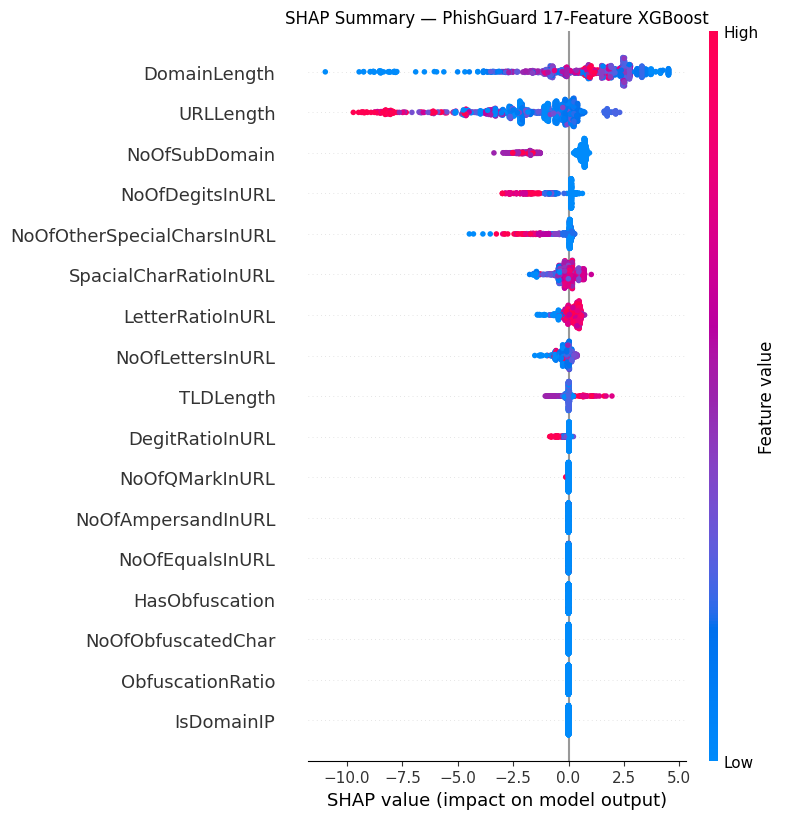

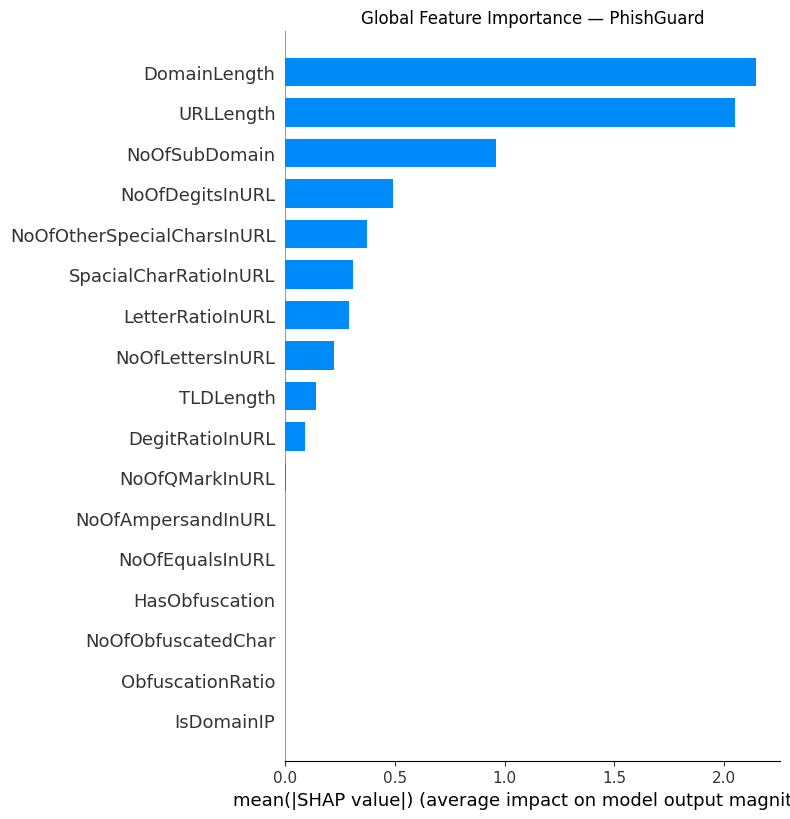


Saved:
- consistent_shap_feature_importance.csv
- consistent_shap_summary.png
- consistent_shap_bar.png

STEP 19Z COMPLETED


In [61]:

# STEP 19Z: SHAP EXPLAINABILITY FOR FINAL 17-FEATURE MODEL

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use validation data for explainability
X_shap = X_val_new.sample(
    n=min(1000, len(X_val_new)),
    random_state=42
).copy()

print("SHAP sample shape:", X_shap.shape)

# Create SHAP TreeExplainer
explainer = shap.TreeExplainer(final_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

# Handle possible SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[0]

if hasattr(shap_values, "values"):
    shap_values = shap_values.values

print("SHAP values shape:", np.array(shap_values).shape)

assert np.array(shap_values).shape == X_shap.shape

# Global feature importance
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

print("\nGLOBAL SHAP FEATURE IMPORTANCE")
display(shap_importance)

# Save importance table
shap_importance.to_csv(
    "consistent_shap_feature_importance.csv",
    index=False
)

# SHAP summary plot
plt.figure()
shap.summary_plot(
    shap_values,
    X_shap,
    show=False,
    max_display=17
)
plt.title("SHAP Summary — PhishGuard 17-Feature XGBoost")
plt.tight_layout()
plt.savefig(
    "consistent_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# SHAP bar plot
plt.figure()
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=False,
    max_display=17
)
plt.title("Global Feature Importance — PhishGuard")
plt.tight_layout()
plt.savefig(
    "consistent_shap_bar.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nSaved:")
print("- consistent_shap_feature_importance.csv")
print("- consistent_shap_summary.png")
print("- consistent_shap_bar.png")

print("\nSTEP 19Z COMPLETED")


In [62]:

# STEP 20A: VERIFY THE LIVE URL FEATURE EXTRACTOR

import inspect
import pandas as pd
import numpy as np

# Display the exact extractor currently used
print("=" * 80)
print("CURRENT URL FEATURE EXTRACTOR")
print("=" * 80)

print(inspect.getsource(extract_url_features))

# Test different URL formats
google_test_urls = [
    "google.com",
    "http://google.com",
    "https://google.com",
    "https://www.google.com",
    "http:// google.com"
]

google_results = []

for original_url in google_test_urls:

    # Extract features using the existing training extractor
    extracted = extract_url_features(original_url)

    # Match the exact feature order used by the final model
    feature_row = pd.DataFrame(
        [[extracted[feature] for feature in final_features]],
        columns=final_features
    )

    # Predict using the final trained model
    phishing_probability = float(
        final_model.predict_proba(feature_row)[0, 0]
    )

    prediction = (
        "Phishing"
        if phishing_probability >= final_threshold
        else "Legitimate"
    )

    google_results.append({
        "Input_URL": original_url,
        "Prediction": prediction,
        "Phishing_Probability": phishing_probability,
        "Legitimate_Probability": 1 - phishing_probability
    })

google_test_results = pd.DataFrame(google_results)

print("\nGOOGLE URL VARIANT TEST RESULTS")
print("=" * 80)

display(
    google_test_results.style.format({
        "Phishing_Probability": "{:.4%}",
        "Legitimate_Probability": "{:.4%}"
    })
)

print("\nSTEP 20A COMPLETED")


CURRENT URL FEATURE EXTRACTOR
def extract_url_features(url):

    # 1. Normalize input
    url = re.sub(r"\s+", "", str(url).strip())

    if not url:
        raise ValueError("URL cannot be empty")

    if not re.match(r"^https?://", url, re.IGNORECASE):
        url = "https://" + url

    # 2. Parse URL
    parsed = urlsplit(url)
    hostname = (parsed.hostname or "").lower()

    # 3. Domain information
    domain_info = extractor(url)

    try:
        ipaddress.ip_address(hostname)
        is_ip = 1
    except ValueError:
        is_ip = 0

    domain_length = len(hostname)

    tld_length = len(domain_info.suffix)

    subdomains = [
        part for part in domain_info.subdomain.split(".")
        if part and part.lower() != "www"
    ]

    no_of_subdomain = len(subdomains)

    # 4. URL character statistics
    url_length = len(url)

    letters = sum(c.isalpha() for c in url)
    digits = sum(c.isdigit() for c in url)

    equals = url.count("=")
    question_marks = url.coun

,Input_URL,Prediction,Phishing_Probability,Legitimate_Probability
0,google.com,Phishing,99.1217%,0.8783%
1,http://google.com,Phishing,99.6649%,0.3351%
2,https://google.com,Phishing,99.1217%,0.8783%
3,https://www.google.com,Legitimate,1.7487%,98.2513%
4,http:// google.com,Phishing,99.6649%,0.3351%



STEP 20A COMPLETED


In [63]:

# STEP 20B: CANONICAL URL FEATURE EXTRACTOR
# Removes scheme and leading www before calculating URL statistics.

import re
import ipaddress
import pandas as pd
import numpy as np

from urllib.parse import urlsplit

def extract_url_features(url):

    # 1. Normalize input
    url = re.sub(r"\s+", "", str(url).strip())

    if not url:
        raise ValueError("URL cannot be empty")

    if not re.match(r"^https?://", url, re.IGNORECASE):
        url = "https://" + url

    # 2. Parse URL
    parsed = urlsplit(url)
    hostname = (parsed.hostname or "").lower()

    if not hostname:
        raise ValueError("Invalid URL: hostname not found")

    # 3. Canonicalize hostname by removing leading www.
    canonical_hostname = re.sub(
        r"^www\.",
        "",
        hostname,
        flags=re.IGNORECASE
    )

    # 4. Extract domain information
    domain_info = extractor(url)

    try:
        ipaddress.ip_address(canonical_hostname)
        is_ip = 1
    except ValueError:
        is_ip = 0

    domain_length = len(canonical_hostname)
    tld_length = len(domain_info.suffix)

    subdomains = [
        part for part in domain_info.subdomain.split(".")
        if part and part.lower() != "www"
    ]

    no_of_subdomain = len(subdomains)

    # 5. Create canonical URL text:
    # no scheme, no leading www.
    canonical_url = (
        canonical_hostname
        + (parsed.path or "")
        + (("?" + parsed.query) if parsed.query else "")
        + (("#" + parsed.fragment) if parsed.fragment else "")
    )

    # 6. Character statistics
    url_length = len(canonical_url)

    letters = sum(c.isalpha() for c in canonical_url)
    digits = sum(c.isdigit() for c in canonical_url)

    equals = canonical_url.count("=")
    question_marks = canonical_url.count("?")
    ampersands = canonical_url.count("&")

    other_special = sum(
        not c.isalnum() and c not in "=?&"
        for c in canonical_url
    )

    # 7. Obfuscation indicators
    encoded_sequences = re.findall(
        r"%[0-9a-fA-F]{2}",
        canonical_url
    )

    obfuscated_chars = len(encoded_sequences)

    has_obfuscation = int(
        obfuscated_chars > 0 or "@" in parsed.netloc
    )

    # 8. Ratios
    denominator = max(url_length, 1)

    return {
        "URLLength": url_length,
        "DomainLength": domain_length,
        "IsDomainIP": is_ip,
        "TLDLength": tld_length,
        "NoOfSubDomain": no_of_subdomain,
        "HasObfuscation": has_obfuscation,
        "NoOfObfuscatedChar": obfuscated_chars,
        "ObfuscationRatio": obfuscated_chars / denominator,
        "NoOfLettersInURL": letters,
        "LetterRatioInURL": letters / denominator,
        "NoOfDegitsInURL": digits,
        "DegitRatioInURL": digits / denominator,
        "NoOfEqualsInURL": equals,
        "NoOfQMarkInURL": question_marks,
        "NoOfAmpersandInURL": ampersands,
        "NoOfOtherSpecialCharsInURL": other_special,
        "SpacialCharRatioInURL": other_special / denominator
    }


# Verify canonical equivalence
google_variants = [
    "google.com",
    "http://google.com",
    "https://google.com",
    "https://www.google.com",
    "http:// google.com"
]

google_feature_rows = [
    extract_url_features(url)
    for url in google_variants
]

google_feature_df = pd.DataFrame(google_feature_rows)

print("CANONICAL FEATURE EXTRACTION CHECK")
print("=" * 75)

display(google_feature_df)

print("\nUnique feature rows:", len(google_feature_df.drop_duplicates()))

assert len(google_feature_df.drop_duplicates()) == 1

print("\nSUCCESS: All five Google variants produce identical features.")
print("STEP 20B COMPLETED")


CANONICAL FEATURE EXTRACTION CHECK


,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL
0,10,10,0,3,0,0,0,0.0,9,0.9,0,0.0,0,0,0,1,0.1
1,10,10,0,3,0,0,0,0.0,9,0.9,0,0.0,0,0,0,1,0.1
2,10,10,0,3,0,0,0,0.0,9,0.9,0,0.0,0,0,0,1,0.1
3,10,10,0,3,0,0,0,0.0,9,0.9,0,0.0,0,0,0,1,0.1
4,10,10,0,3,0,0,0,0.0,9,0.9,0,0.0,0,0,0,1,0.1



Unique feature rows: 1

SUCCESS: All five Google variants produce identical features.
STEP 20B COMPLETED


In [65]:

# STEP 20C FIX: CORRECT FEATURE NAME AND CONTINUE

canonical_feature_order = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",  # Correct spelling
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL"
]

# Check that every expected feature exists
missing_features = [
    f for f in canonical_feature_order
    if f not in X_canonical.columns
]

print("Missing expected features:", missing_features)
print("Available features:", X_canonical.columns.tolist())

assert len(missing_features) == 0

X_canonical = X_canonical[canonical_feature_order].copy()

# Labels and registered domains
y_canonical = df_model["label"].astype(int).copy()
groups_canonical = df_model["registered_domain"].copy()

print("\nFEATURE MATRIX SUMMARY")
print("Rows:", X_canonical.shape[0])
print("Features:", X_canonical.shape[1])
print("Missing values:", X_canonical.isna().sum().sum())
print("Infinite values:", np.isinf(X_canonical.to_numpy()).sum())

assert X_canonical.shape == (len(df_model), 17)
assert X_canonical.isna().sum().sum() == 0
assert np.isfinite(X_canonical.to_numpy()).all()
assert "IsHTTPS" not in X_canonical.columns

# Fresh domain-separated test split
sgkf_test_new = StratifiedGroupKFold(
    n_splits=8,
    shuffle=True,
    random_state=2026
)

dev_idx_new, test_idx_new = next(
    sgkf_test_new.split(
        X_canonical,
        y_canonical,
        groups=groups_canonical
    )
)

X_dev_new = X_canonical.iloc[dev_idx_new].copy()
y_dev_new = y_canonical.iloc[dev_idx_new].copy()
groups_dev_new = groups_canonical.iloc[dev_idx_new].copy()

# Fresh validation split
sgkf_val_new = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

train_idx_new, val_idx_new = next(
    sgkf_val_new.split(
        X_dev_new,
        y_dev_new,
        groups=groups_dev_new
    )
)

X_train_canonical = X_dev_new.iloc[train_idx_new].copy()
y_train_canonical = y_dev_new.iloc[train_idx_new].copy()

X_val_canonical = X_dev_new.iloc[val_idx_new].copy()
y_val_canonical = y_dev_new.iloc[val_idx_new].copy()

X_test_canonical = X_canonical.iloc[test_idx_new].copy()
y_test_canonical = y_canonical.iloc[test_idx_new].copy()

# Verify domain separation
train_domains_new = set(groups_dev_new.iloc[train_idx_new])
val_domains_new = set(groups_dev_new.iloc[val_idx_new])
test_domains_new = set(groups_canonical.iloc[test_idx_new])

print("\nFRESH DOMAIN-SEPARATED SPLIT SUMMARY")
print("=" * 75)

for name, X_part, y_part, domain_set in [
    ("TRAIN", X_train_canonical, y_train_canonical, train_domains_new),
    ("VALIDATION", X_val_canonical, y_val_canonical, val_domains_new),
    ("TEST", X_test_canonical, y_test_canonical, test_domains_new)
]:
    print(f"\n{name}")
    print("Rows:", len(X_part))
    print("Domains:", len(domain_set))
    print("Phishing:", int((y_part == 0).sum()))
    print("Legitimate:", int((y_part == 1).sum()))
    print("Phishing percentage:", round((y_part == 0).mean() * 100, 2))

print("\nDOMAIN OVERLAP CHECK")
print("Train-validation:", len(train_domains_new & val_domains_new))
print("Train-test:", len(train_domains_new & test_domains_new))
print("Validation-test:", len(val_domains_new & test_domains_new))

assert not (train_domains_new & val_domains_new)
assert not (train_domains_new & test_domains_new)
assert not (val_domains_new & test_domains_new)

print("\nSTEP 20C COMPLETED SUCCESSFULLY")


Missing expected features: []
Available features: ['URLLength', 'DomainLength', 'IsDomainIP', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL']

FEATURE MATRIX SUMMARY
Rows: 235370
Features: 17
Missing values: 0
Infinite values: 0

FRESH DOMAIN-SEPARATED SPLIT SUMMARY

TRAIN
Rows: 171556
Domains: 122880
Phishing: 77008
Legitimate: 94548
Phishing percentage: 44.89

VALIDATION
Rows: 37638
Domains: 30717
Phishing: 14115
Legitimate: 23523
Phishing percentage: 37.5

TEST
Rows: 26176
Domains: 21912
Phishing: 9397
Legitimate: 16779
Phishing percentage: 35.9

DOMAIN OVERLAP CHECK
Train-validation: 0
Train-test: 0
Validation-test: 0

STEP 20C COMPLETED SUCCESSFULLY


In [67]:

# STEP 20D: FIND BETTER-BALANCED DOMAIN-GROUPED SPLITS

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

overall_phishing_rate = (y_canonical == 0).mean()

# Examine all 8 possible test folds
test_splitter = StratifiedGroupKFold(
    n_splits=8,
    shuffle=True,
    random_state=2026
)

test_candidates = []

for fold, (dev_idx, test_idx) in enumerate(
    test_splitter.split(
        X_canonical,
        y_canonical,
        groups=groups_canonical
    )
):
    rate = (y_canonical.iloc[test_idx] == 0).mean()

    test_candidates.append({
        "fold": fold,
        "test_rows": len(test_idx),
        "phishing_percentage": rate * 100,
        "difference_from_overall": abs(rate - overall_phishing_rate) * 100,
        "dev_idx": dev_idx,
        "test_idx": test_idx
    })

test_report = pd.DataFrame([
    {k: v for k, v in item.items()
     if k not in ["dev_idx", "test_idx"]}
    for item in test_candidates
])

print("OVERALL PHISHING PERCENTAGE:",
      round(overall_phishing_rate * 100, 2))

print("\nTEST FOLD COMPARISON")
display(test_report.round(2))

# Select the test fold closest to the overall class distribution
best_test = min(
    test_candidates,
    key=lambda item: item["difference_from_overall"]
)

dev_idx_new = best_test["dev_idx"]
test_idx_new = best_test["test_idx"]

X_dev_new = X_canonical.iloc[dev_idx_new].copy()
y_dev_new = y_canonical.iloc[dev_idx_new].copy()
groups_dev_new = groups_canonical.iloc[dev_idx_new].copy()

# Examine all 5 possible validation folds
val_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

val_candidates = []

for fold, (train_idx, val_idx) in enumerate(
    val_splitter.split(
        X_dev_new,
        y_dev_new,
        groups=groups_dev_new
    )
):
    rate = (y_dev_new.iloc[val_idx] == 0).mean()

    val_candidates.append({
        "fold": fold,
        "val_rows": len(val_idx),
        "phishing_percentage": rate * 100,
        "difference_from_dev": abs(
            rate - (y_dev_new == 0).mean()
        ) * 100,
        "train_idx": train_idx,
        "val_idx": val_idx
    })

val_report = pd.DataFrame([
    {k: v for k, v in item.items()
     if k not in ["train_idx", "val_idx"]}
    for item in val_candidates
])

print("\nVALIDATION FOLD COMPARISON")
display(val_report.round(2))

best_val = min(
    val_candidates,
    key=lambda item: item["difference_from_dev"]
)

train_idx_new = best_val["train_idx"]
val_idx_new = best_val["val_idx"]

# Final datasets
X_train_canonical = X_dev_new.iloc[train_idx_new].copy()
y_train_canonical = y_dev_new.iloc[train_idx_new].copy()

X_val_canonical = X_dev_new.iloc[val_idx_new].copy()
y_val_canonical = y_dev_new.iloc[val_idx_new].copy()

X_test_canonical = X_canonical.iloc[test_idx_new].copy()
y_test_canonical = y_canonical.iloc[test_idx_new].copy()

# Verify domain separation
train_domains_new = set(
    groups_dev_new.iloc[train_idx_new]
)
val_domains_new = set(
    groups_dev_new.iloc[val_idx_new]
)
test_domains_new = set(
    groups_canonical.iloc[test_idx_new]
)

print("\nFINAL SELECTED SPLITS")
for name, X_part, y_part, domains in [
    ("TRAIN", X_train_canonical, y_train_canonical, train_domains_new),
    ("VALIDATION", X_val_canonical, y_val_canonical, val_domains_new),
    ("TEST", X_test_canonical, y_test_canonical, test_domains_new)
]:
    print(
        f"{name}: Rows={len(X_part)}, "
        f"Domains={len(domains)}, "
        f"Phishing={(y_part == 0).mean()*100:.2f}%, "
        f"Legitimate={(y_part == 1).mean()*100:.2f}%"
    )

print("\nDOMAIN OVERLAPS")
print("Train-validation:", len(train_domains_new & val_domains_new))
print("Train-test:", len(train_domains_new & test_domains_new))
print("Validation-test:", len(val_domains_new & test_domains_new))

assert len(train_domains_new & val_domains_new) == 0
assert len(train_domains_new & test_domains_new) == 0
assert len(val_domains_new & test_domains_new) == 0

print("\nSTEP 20D COMPLETED")


OVERALL PHISHING PERCENTAGE: 42.71

TEST FOLD COMPARISON


,fold,test_rows,phishing_percentage,difference_from_overall
0,0,26176,35.90,6.81
1,1,33090,49.09,6.38
2,2,31035,45.70,3.00
3,3,27274,37.91,4.80
4,4,27580,38.73,3.97
5,5,25854,35.03,7.68
6,6,32756,48.65,5.94
7,7,31605,46.45,3.74



VALIDATION FOLD COMPARISON


,fold,val_rows,phishing_percentage,difference_from_dev
0,0,38251,38.56,3.69
1,1,40217,40.98,1.27
2,2,38283,38.54,3.72
3,3,42316,44.19,1.94
4,4,45268,47.83,5.58



FINAL SELECTED SPLITS
TRAIN: Rows=164118, Domains=122856, Phishing=42.56%, Legitimate=57.44%
VALIDATION: Rows=40217, Domains=30711, Phishing=40.98%, Legitimate=59.02%
TEST: Rows=31035, Domains=21942, Phishing=45.70%, Legitimate=54.30%

DOMAIN OVERLAPS
Train-validation: 0
Train-test: 0
Validation-test: 0

STEP 20D COMPLETED


In [68]:

# STEP 21: TRAIN AND COMPARE THREE MODELS
# Class 0 = Phishing
# Class 1 = Legitimate

import time
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

canonical_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )
}

canonical_results = []
canonical_trained_models = {}
canonical_validation_probabilities = {}

print("TRAINING AND VALIDATING MODELS")
print("=" * 75)

for name, model in canonical_models.items():

    print(f"\nTraining {name}...")
    start_time = time.time()

    model.fit(
        X_train_canonical,
        y_train_canonical
    )

    training_time = time.time() - start_time

    # Get probability of class 0 (Phishing)
    class_zero_index = list(model.classes_).index(0)

    phishing_probabilities = model.predict_proba(
        X_val_canonical
    )[:, class_zero_index]

    # Default threshold: 0.50
    predictions = np.where(
        phishing_probabilities >= 0.50,
        0,
        1
    )

    results = {
        "Model": name,
        "Accuracy": accuracy_score(
            y_val_canonical, predictions
        ),
        "Phishing Precision": precision_score(
            y_val_canonical, predictions,
            pos_label=0, zero_division=0
        ),
        "Phishing Recall": recall_score(
            y_val_canonical, predictions,
            pos_label=0, zero_division=0
        ),
        "Phishing F1": f1_score(
            y_val_canonical, predictions,
            pos_label=0, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            (y_val_canonical == 0).astype(int),
            phishing_probabilities
        ),
        "Training Time (sec)": training_time
    }

    canonical_results.append(results)
    canonical_trained_models[name] = model
    canonical_validation_probabilities[name] = (
        phishing_probabilities
    )

    print(f"Completed {name}")
    print("Accuracy:", round(results["Accuracy"] * 100, 4), "%")
    print("Phishing Precision:",
          round(results["Phishing Precision"] * 100, 4), "%")
    print("Phishing Recall:",
          round(results["Phishing Recall"] * 100, 4), "%")
    print("Phishing F1:",
          round(results["Phishing F1"] * 100, 4), "%")
    print("ROC-AUC:", round(results["ROC-AUC"], 5))
    print("Training time:", round(training_time, 2), "seconds")

# Comparison table
canonical_comparison = pd.DataFrame(canonical_results)

canonical_comparison = canonical_comparison.sort_values(
    by="Phishing F1",
    ascending=False
).reset_index(drop=True)

print("\nFINAL VALIDATION COMPARISON")
print("=" * 75)

display(
    canonical_comparison.style.format({
        "Accuracy": "{:.4f}",
        "Phishing Precision": "{:.4f}",
        "Phishing Recall": "{:.4f}",
        "Phishing F1": "{:.4f}",
        "ROC-AUC": "{:.5f}",
        "Training Time (sec)": "{:.2f}"
    })
)

print("\nDETAILED CLASSIFICATION REPORTS")
for name, model in canonical_trained_models.items():

    probabilities = canonical_validation_probabilities[name]

    predictions = np.where(
        probabilities >= 0.50,
        0,
        1
    )

    print(f"\n{name}")
    print("-" * 60)

    print(classification_report(
        y_val_canonical,
        predictions,
        labels=[0, 1],
        target_names=["Phishing", "Legitimate"],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_val_canonical,
        predictions,
        labels=[0, 1]
    ))

print("\nSTEP 21 COMPLETED")


TRAINING AND VALIDATING MODELS

Training Logistic Regression...
Completed Logistic Regression
Accuracy: 85.6056 %
Phishing Precision: 91.9557 %
Phishing Recall: 71.094 %
Phishing F1: 80.1903 %
ROC-AUC: 0.87204
Training time: 1.24 seconds

Training Random Forest...
Completed Random Forest
Accuracy: 86.3864 %
Phishing Precision: 93.6123 %
Phishing Recall: 71.6704 %
Phishing F1: 81.1849 %
ROC-AUC: 0.89159
Training time: 32.54 seconds

Training XGBoost...
Completed XGBoost
Accuracy: 86.5057 %
Phishing Precision: 93.6779 %
Phishing Recall: 71.9252 %
Phishing F1: 81.3729 %
ROC-AUC: 0.89264
Training time: 3.9 seconds

FINAL VALIDATION COMPARISON


,Model,Accuracy,Phishing Precision,Phishing Recall,Phishing F1,ROC-AUC,Training Time (sec)
0,XGBoost,0.8651,0.9368,0.7193,0.8137,0.89264,3.90
1,Random Forest,0.8639,0.9361,0.7167,0.8118,0.89159,32.54
2,Logistic Regression,0.8561,0.9196,0.7109,0.8019,0.87204,1.24



DETAILED CLASSIFICATION REPORTS

Logistic Regression
------------------------------------------------------------
              precision    recall  f1-score   support

    Phishing       0.92      0.71      0.80     16481
  Legitimate       0.83      0.96      0.89     23736

    accuracy                           0.86     40217
   macro avg       0.87      0.83      0.84     40217
weighted avg       0.86      0.86      0.85     40217

Confusion Matrix:
[[11717  4764]
 [ 1025 22711]]

Random Forest
------------------------------------------------------------
              precision    recall  f1-score   support

    Phishing       0.94      0.72      0.81     16481
  Legitimate       0.83      0.97      0.89     23736

    accuracy                           0.86     40217
   macro avg       0.88      0.84      0.85     40217
weighted avg       0.87      0.86      0.86     40217

Confusion Matrix:
[[11812  4669]
 [  806 22930]]

XGBoost
------------------------------------------------

In [69]:

# STEP 22: PHISHING THRESHOLD OPTIMIZATION USING VALIDATION DATA

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Select XGBoost as the current best model
best_model_name = "XGBoost"
best_model = canonical_trained_models[best_model_name]

# Get phishing probabilities (class 0)
phishing_probabilities = canonical_validation_probabilities[
    best_model_name
]

thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:

    predictions = np.where(
        phishing_probabilities >= threshold,
        0,
        1
    )

    cm = confusion_matrix(
        y_val_canonical,
        predictions,
        labels=[0, 1]
    )

    # Matrix layout:
    # [[Correct phishing, Missed phishing],
    #  [False phishing alarm, Correct legitimate]]

    tn_phishing, fn_phishing = cm[0]
    fp_phishing, tp_legitimate = cm[1]

    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": accuracy_score(
            y_val_canonical, predictions
        ),
        "Phishing Precision": precision_score(
            y_val_canonical, predictions,
            pos_label=0, zero_division=0
        ),
        "Phishing Recall": recall_score(
            y_val_canonical, predictions,
            pos_label=0, zero_division=0
        ),
        "Phishing F1": f1_score(
            y_val_canonical, predictions,
            pos_label=0, zero_division=0
        ),
        "Missed Phishing (FN)": int(fn_phishing),
        "False Alarms (FP)": int(fp_phishing)
    })

threshold_df = pd.DataFrame(threshold_results)

print("XGBOOST THRESHOLD COMPARISON")
print("=" * 90)

display(
    threshold_df.style.format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Phishing Precision": "{:.4f}",
        "Phishing Recall": "{:.4f}",
        "Phishing F1": "{:.4f}"
    })
)

# Best threshold according to phishing F1
best_f1_row = threshold_df.loc[
    threshold_df["Phishing F1"].idxmax()
]

print("\nBEST THRESHOLD BY PHISHING F1")
print(best_f1_row)

print("\nSTEP 22 COMPLETED")


XGBOOST THRESHOLD COMPARISON


,Threshold,Accuracy,Phishing Precision,Phishing Recall,Phishing F1,Missed Phishing (FN),False Alarms (FP)
0,0.10,0.4884,0.4440,0.9849,0.6121,249,20327
1,0.15,0.6723,0.5624,0.9028,0.6931,1602,11577
2,0.20,0.8168,0.7561,0.8162,0.7850,3029,4340
3,0.25,0.8264,0.7773,0.8079,0.7923,3166,3815
4,0.30,0.8509,0.8489,0.7739,0.8096,3727,2270
5,0.35,0.8601,0.8851,0.7570,0.8160,4005,1620
6,0.40,0.8626,0.8990,0.7487,0.8170,4141,1386
7,0.45,0.8643,0.9166,0.7358,0.8163,4354,1104
8,0.50,0.8651,0.9368,0.7193,0.8137,4627,800
9,0.55,0.8647,0.9475,0.7092,0.8112,4792,648



BEST THRESHOLD BY PHISHING F1
Threshold                  0.400000
Accuracy                   0.862571
Phishing Precision         0.899024
Phishing Recall            0.748741
Phishing F1                0.817029
Missed Phishing (FN)    4141.000000
False Alarms (FP)       1386.000000
Name: 6, dtype: float64

STEP 22 COMPLETED


In [70]:

# STEP 23: FINAL TEST EVALUATION

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Selected model and validation-optimized threshold
final_model = canonical_trained_models["XGBoost"]
final_threshold = 0.40

# Predict phishing probabilities on the untouched test set
test_phishing_probabilities = final_model.predict_proba(
    X_test_canonical
)[:, list(final_model.classes_).index(0)]

# Apply the selected threshold
y_test_predictions = np.where(
    test_phishing_probabilities >= final_threshold,
    0,
    1
)

# Calculate final metrics
test_accuracy = accuracy_score(
    y_test_canonical, y_test_predictions
)

test_precision = precision_score(
    y_test_canonical,
    y_test_predictions,
    pos_label=0,
    zero_division=0
)

test_recall = recall_score(
    y_test_canonical,
    y_test_predictions,
    pos_label=0,
    zero_division=0
)

test_f1 = f1_score(
    y_test_canonical,
    y_test_predictions,
    pos_label=0,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    (y_test_canonical == 0).astype(int),
    test_phishing_probabilities
)

test_cm = confusion_matrix(
    y_test_canonical,
    y_test_predictions,
    labels=[0, 1]
)

# Display results
print("FINAL TEST RESULTS — XGBOOST")
print("=" * 75)
print("Selected threshold:", final_threshold)
print("Accuracy:", round(test_accuracy * 100, 4), "%")
print("Phishing Precision:", round(test_precision * 100, 4), "%")
print("Phishing Recall:", round(test_recall * 100, 4), "%")
print("Phishing F1:", round(test_f1 * 100, 4), "%")
print("ROC-AUC:", round(test_roc_auc, 5))

print("\nCONFUSION MATRIX")
print("Rows = Actual | Columns = Predicted")
print("Order = [Phishing, Legitimate]")
print(test_cm)

print("\nCONFUSION MATRIX INTERPRETATION")
print("Correctly detected phishing:",
      test_cm[0, 0])
print("Missed phishing URLs:",
      test_cm[0, 1])
print("Legitimate URLs incorrectly flagged:",
      test_cm[1, 0])
print("Correctly identified legitimate URLs:",
      test_cm[1, 1])

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test_canonical,
    y_test_predictions,
    labels=[0, 1],
    target_names=["Phishing", "Legitimate"],
    zero_division=0
))

# Store final test metrics for later artifact export
final_test_metrics = {
    "model": "XGBoost",
    "threshold": final_threshold,
    "accuracy": float(test_accuracy),
    "phishing_precision": float(test_precision),
    "phishing_recall": float(test_recall),
    "phishing_f1": float(test_f1),
    "roc_auc": float(test_roc_auc),
    "confusion_matrix": test_cm.tolist()
}

print("\nSTEP 23 COMPLETED")


FINAL TEST RESULTS — XGBOOST
Selected threshold: 0.4
Accuracy: 87.8975 %
Phishing Precision: 93.1765 %
Phishing Recall: 79.3288 %
Phishing F1: 85.6969 %
ROC-AUC: 0.91506

CONFUSION MATRIX
Rows = Actual | Columns = Predicted
Order = [Phishing, Legitimate]
[[11252  2932]
 [  824 16027]]

CONFUSION MATRIX INTERPRETATION
Correctly detected phishing: 11252
Missed phishing URLs: 2932
Legitimate URLs incorrectly flagged: 824
Correctly identified legitimate URLs: 16027

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Phishing       0.93      0.79      0.86     14184
  Legitimate       0.85      0.95      0.90     16851

    accuracy                           0.88     31035
   macro avg       0.89      0.87      0.88     31035
weighted avg       0.88      0.88      0.88     31035


STEP 23 COMPLETED


SHAP EXPLAINABILITY
Model: XGBoost
Samples explained: 1000
Features: 17

SHAP VALUES SHAPE: (1000, 17)

TOP 17 FEATURES BY SHAP IMPORTANCE


,Feature,Mean Absolute SHAP
0,URLLength,2.276996
1,DomainLength,1.585543
2,NoOfOtherSpecialCharsInURL,1.122411
3,NoOfDegitsInURL,0.531155
4,NoOfSubDomain,0.500737
5,TLDLength,0.267734
6,NoOfLettersInURL,0.254137
7,LetterRatioInURL,0.151934
8,DegitRatioInURL,0.112480
9,SpacialCharRatioInURL,0.047489


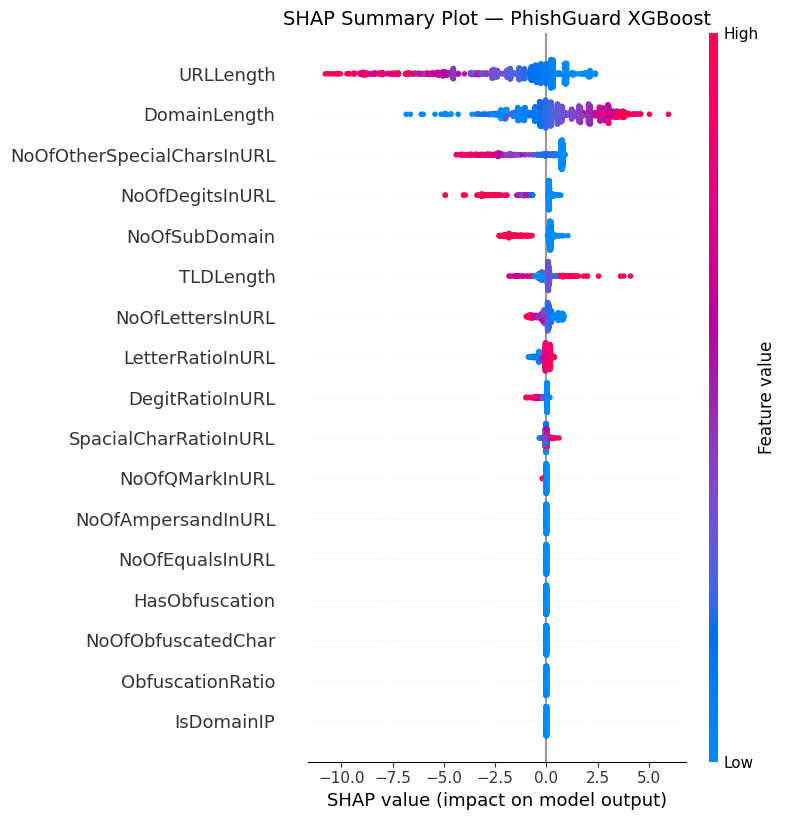

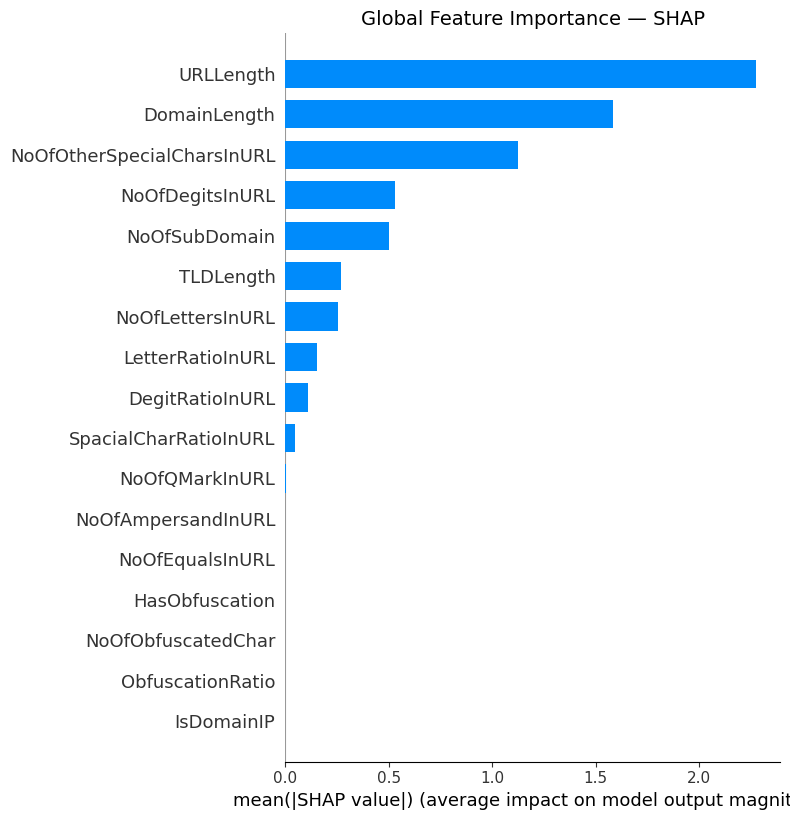


SAVED FILES
- shap_feature_importance.csv
- shap_summary.png
- shap_bar.png

IMPORTANT INTERPRETATION
The XGBoost binary model's SHAP values explain its raw output for class 1 (Legitimate). Positive SHAP values push the output toward Legitimate; negative values push it toward Phishing.

STEP 24 COMPLETED


In [71]:

# STEP 24: FINAL SHAP EXPLAINABILITY

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Use the final trained XGBoost model
final_model = canonical_trained_models["XGBoost"]

# Use validation samples for explanations
X_shap = X_val_canonical.sample(
    n=min(1000, len(X_val_canonical)),
    random_state=42
).copy()

print("SHAP EXPLAINABILITY")
print("=" * 70)
print("Model: XGBoost")
print("Samples explained:", len(X_shap))
print("Features:", X_shap.shape[1])

# Create TreeExplainer
explainer = shap.TreeExplainer(final_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

# Handle different SHAP output formats
if isinstance(shap_values, list):
    shap_values = shap_values[0]

if hasattr(shap_values, "values"):
    shap_values = shap_values.values

shap_values = np.asarray(shap_values)

print("\nSHAP VALUES SHAPE:", shap_values.shape)

assert shap_values.shape == X_shap.shape

# Global feature importance
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean Absolute SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

print("\nTOP 17 FEATURES BY SHAP IMPORTANCE")
display(
    shap_importance.style.format({
        "Mean Absolute SHAP": "{:.6f}"
    })
)

# Create output folder
os.makedirs("PhishGuard_Artifacts", exist_ok=True)

# Save importance CSV
shap_importance.to_csv(
    "PhishGuard_Artifacts/shap_feature_importance.csv",
    index=False
)

# SHAP summary plot
plt.figure(figsize=(11, 7))

shap.summary_plot(
    shap_values,
    X_shap,
    show=False,
    max_display=17
)

plt.title(
    "SHAP Summary Plot — PhishGuard XGBoost",
    fontsize=14
)
plt.tight_layout()

plt.savefig(
    "PhishGuard_Artifacts/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# SHAP bar plot
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=False,
    max_display=17
)

plt.title(
    "Global Feature Importance — SHAP",
    fontsize=14
)
plt.tight_layout()

plt.savefig(
    "PhishGuard_Artifacts/shap_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSAVED FILES")
print("- shap_feature_importance.csv")
print("- shap_summary.png")
print("- shap_bar.png")

print("\nIMPORTANT INTERPRETATION")
print(
    "The XGBoost binary model's SHAP values explain its raw output "
    "for class 1 (Legitimate). Positive SHAP values push the output "
    "toward Legitimate; negative values push it toward Phishing."
)

print("\nSTEP 24 COMPLETED")


In [72]:

# STEP 25: INSPECT THE EXACT CANONICAL FEATURE EXTRACTOR

import inspect

print("FEATURE EXTRACTOR SOURCE CODE")
print("=" * 75)

try:
    extractor_source = inspect.getsource(extract_url_features)
    print(extractor_source)

    print("\nEXTRACTOR SOURCE RETRIEVED SUCCESSFULLY")

except Exception as error:
    print("Could not retrieve source automatically.")
    print("Error:", error)
    print("\nPlease share the original cell where extract_url_features was defined.")

print("\nEXTRACTOR TEST")
print("=" * 75)

test_urls = [
    "google.com",
    "http://google.com",
    "https://google.com",
    "https://www.google.com",
    "http:// google.com"
]

for url in test_urls:
    features = extract_url_features(url)
    print("\nURL:", repr(url))
    print("Feature count:", len(features))
    print("Feature values:", features)


FEATURE EXTRACTOR SOURCE CODE
def extract_url_features(url):

    # 1. Normalize input
    url = re.sub(r"\s+", "", str(url).strip())

    if not url:
        raise ValueError("URL cannot be empty")

    if not re.match(r"^https?://", url, re.IGNORECASE):
        url = "https://" + url

    # 2. Parse URL
    parsed = urlsplit(url)
    hostname = (parsed.hostname or "").lower()

    if not hostname:
        raise ValueError("Invalid URL: hostname not found")

    # 3. Canonicalize hostname by removing leading www.
    canonical_hostname = re.sub(
        r"^www\.",
        "",
        hostname,
        flags=re.IGNORECASE
    )

    # 4. Extract domain information
    domain_info = extractor(url)

    try:
        ipaddress.ip_address(canonical_hostname)
        is_ip = 1
    except ValueError:
        is_ip = 0

    domain_length = len(canonical_hostname)
    tld_length = len(domain_info.suffix)

    subdomains = [
        part for part in domain_info.subdomain.split(".")
        if p

In [73]:

# STEP 26: TEST GOOGLE URL VARIANTS WITH FINAL XGBOOST MODEL

import pandas as pd
import numpy as np

google_test_urls = [
    "google.com",
    "http://google.com",
    "https://google.com",
    "https://www.google.com",
    "http:// google.com"
]

feature_order = X_canonical.columns.tolist()

google_results = []

print("GOOGLE URL GENERALIZATION TEST")
print("=" * 75)

for url in google_test_urls:

    # Extract canonical features
    features = extract_url_features(url)

    # Convert to DataFrame in exact training feature order
    input_df = pd.DataFrame(
        [[features[name] for name in feature_order]],
        columns=feature_order
    )

    # Predict probabilities
    probabilities = final_model.predict_proba(input_df)[0]

    phishing_index = list(final_model.classes_).index(0)
    phishing_probability = probabilities[phishing_index]

    prediction = (
        "Phishing"
        if phishing_probability >= final_threshold
        else "Legitimate"
    )

    google_results.append({
        "Input URL": url,
        "Prediction": prediction,
        "Phishing Probability (%)": round(
            phishing_probability * 100, 4
        ),
        "Threshold": final_threshold
    })

google_results_df = pd.DataFrame(google_results)

display(google_results_df)

print("\nUNIQUE PREDICTIONS:",
      google_results_df["Prediction"].nunique())

print("UNIQUE FEATURE VECTORS:",
      len({
          tuple(extract_url_features(url)[name]
                for name in feature_order)
          for url in google_test_urls
      }))

if google_results_df["Prediction"].nunique() == 1:
    print("\nAll Google URL variants receive the same prediction.")
else:
    print("\nWARNING: Google variants have inconsistent predictions.")

print("\nSTEP 26 COMPLETED")


GOOGLE URL GENERALIZATION TEST


,Input URL,Prediction,Phishing Probability (%),Threshold
0,google.com,Legitimate,16.8316,0.4
1,http://google.com,Legitimate,16.8316,0.4
2,https://google.com,Legitimate,16.8316,0.4
3,https://www.google.com,Legitimate,16.8316,0.4
4,http:// google.com,Legitimate,16.8316,0.4



UNIQUE PREDICTIONS: 1
UNIQUE FEATURE VECTORS: 1

All Google URL variants receive the same prediction.

STEP 26 COMPLETED


In [74]:

# STEP 27: CREATE PERMANENT PHISHGUARD MODEL ARTIFACTS

import os
import json
import shutil
import joblib
import inspect
import numpy as np
import pandas as pd
import xgboost
from pathlib import Path

# --------------------------------------------------
# 1. CREATE PROJECT DIRECTORY STRUCTURE
# --------------------------------------------------

PROJECT_DIR = Path("PhishGuard_Project")

MODELS_DIR = PROJECT_DIR / "models"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
SRC_DIR = PROJECT_DIR / "src"

for folder in [MODELS_DIR, ARTIFACTS_DIR, SRC_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("PROJECT DIRECTORIES CREATED")

# --------------------------------------------------
# 2. SAVE TRAINED MODEL
# --------------------------------------------------

joblib.dump(
    final_model,
    MODELS_DIR / "xgboost_model.joblib"
)

final_model.save_model(
    str(MODELS_DIR / "xgboost_model.json")
)

print("Saved XGBoost model in Joblib and JSON formats")

# --------------------------------------------------
# 3. SAVE FEATURE NAMES AND THRESHOLD
# --------------------------------------------------

feature_names = X_canonical.columns.tolist()

with open(MODELS_DIR / "feature_names.json", "w") as file:
    json.dump(feature_names, file, indent=4)

with open(MODELS_DIR / "threshold.json", "w") as file:
    json.dump({
        "model": "XGBoost",
        "threshold": float(final_threshold),
        "phishing_class": 0,
        "legitimate_class": 1
    }, file, indent=4)

# --------------------------------------------------
# 4. SAVE EXACT FEATURE EXTRACTOR SOURCE
# --------------------------------------------------

extractor_code = """
import re
import ipaddress
from urllib.parse import urlsplit
import tldextract

# Use the same suffix-list configuration as training
extractor = tldextract.TLDExtract(suffix_list_urls=None)

"""

extractor_code += inspect.getsource(extract_url_features)

extractor_code += """

FEATURE_NAMES = """ + repr(feature_names) + "\n"

with open(SRC_DIR / "feature_extractor.py", "w") as file:
    file.write(extractor_code)

print("Saved exact canonical feature extractor")

# --------------------------------------------------
# 5. SAVE FINAL EVALUATION METRICS
# --------------------------------------------------

metrics = {
    "project": "PhishGuard",
    "model": "XGBoost",
    "dataset": "PhiUSIIL Phishing URL Dataset",
    "feature_count": len(feature_names),
    "features": feature_names,
    "threshold": float(final_threshold),

    "validation": {
        "accuracy": float(
            canonical_comparison.loc[
                canonical_comparison["Model"] == "XGBoost",
                "Accuracy"
            ].iloc[0]
        ),
        "phishing_precision": float(
            canonical_comparison.loc[
                canonical_comparison["Model"] == "XGBoost",
                "Phishing Precision"
            ].iloc[0]
        ),
        "phishing_recall": float(
            canonical_comparison.loc[
                canonical_comparison["Model"] == "XGBoost",
                "Phishing Recall"
            ].iloc[0]
        ),
        "phishing_f1": float(
            canonical_comparison.loc[
                canonical_comparison["Model"] == "XGBoost",
                "Phishing F1"
            ].iloc[0]
        ),
        "roc_auc": float(
            canonical_comparison.loc[
                canonical_comparison["Model"] == "XGBoost",
                "ROC-AUC"
            ].iloc[0]
        )
    },

    "test": final_test_metrics,

    "split_sizes": {
        "training": int(len(X_train_canonical)),
        "validation": int(len(X_val_canonical)),
        "testing": int(len(X_test_canonical))
    },

    "confusion_matrix_order": [
        "Phishing",
        "Legitimate"
    ],

    "notes": [
        "Class 0 represents phishing.",
        "Class 1 represents legitimate.",
        "Threshold was selected using validation data.",
        "Test set was reserved for final evaluation.",
        "Splits were separated by registered domain.",
        "Earlier test error analysis influenced extractor development; "
        "an independent external dataset is still recommended."
    ]
}

with open(ARTIFACTS_DIR / "evaluation_metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

# --------------------------------------------------
# 6. SAVE MODEL COMPARISON AND THRESHOLD RESULTS
# --------------------------------------------------

canonical_comparison.to_csv(
    ARTIFACTS_DIR / "model_comparison.csv",
    index=False
)

threshold_df.to_csv(
    ARTIFACTS_DIR / "threshold_analysis.csv",
    index=False
)

google_results_df.to_csv(
    ARTIFACTS_DIR / "google_generalization_test.csv",
    index=False
)

# --------------------------------------------------
# 7. COPY SHAP OUTPUTS
# --------------------------------------------------

shap_source_dir = Path("PhishGuard_Artifacts")

for filename in [
    "shap_feature_importance.csv",
    "shap_summary.png",
    "shap_bar.png"
]:
    source = shap_source_dir / filename

    if source.exists():
        shutil.copy2(
            source,
            ARTIFACTS_DIR / filename
        )
        print("Copied:", filename)
    else:
        print("WARNING: SHAP file not found:", filename)

# --------------------------------------------------
# 8. VERIFY EXTRACTOR IMPORT AND MODEL PREDICTION
# --------------------------------------------------

import importlib.util

extractor_path = SRC_DIR / "feature_extractor.py"

spec = importlib.util.spec_from_file_location(
    "phishguard_feature_extractor",
    extractor_path
)

extractor_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(extractor_module)

test_features = extractor_module.extract_url_features(
    "https://www.google.com"
)

test_input = pd.DataFrame(
    [[test_features[name] for name in feature_names]],
    columns=feature_names
)

saved_pipeline = joblib.load(
    MODELS_DIR / "xgboost_model.joblib"
)

saved_probabilities = saved_pipeline.predict_proba(test_input)[0]

phishing_index = list(saved_pipeline.classes_).index(0)
saved_phishing_probability = saved_probabilities[phishing_index]

print("\nPORTABILITY VERIFICATION")
print("Feature count:", len(test_features))
print("Feature order correct:", list(test_features.keys()) == feature_names)
print(
    "Google phishing probability:",
    round(saved_phishing_probability * 100, 4), "%"
)
print(
    "Google prediction:",
    "Phishing" if saved_phishing_probability >= final_threshold
    else "Legitimate"
)

assert len(test_features) == 17
assert list(test_features.keys()) == feature_names
assert abs(
    saved_phishing_probability - 0.168316
) < 0.001

# --------------------------------------------------
# 9. DISPLAY PROJECT FILES
# --------------------------------------------------

print("\nPHISHGUARD PROJECT FILES")
print("=" * 70)

for path in sorted(PROJECT_DIR.rglob("*")):
    if path.is_file():
        print(
            str(path.relative_to(PROJECT_DIR)),
            "|",
            round(path.stat().st_size / 1024, 2),
            "KB"
        )

print("\nSTEP 27 COMPLETED SUCCESSFULLY")


PROJECT DIRECTORIES CREATED
Saved XGBoost model in Joblib and JSON formats
Saved exact canonical feature extractor
Copied: shap_feature_importance.csv
Copied: shap_summary.png
Copied: shap_bar.png

PORTABILITY VERIFICATION
Feature count: 17
Feature order correct: True
Google phishing probability: 16.8316 %
Google prediction: Legitimate

PHISHGUARD PROJECT FILES
artifacts/evaluation_metrics.json | 1.9 KB
artifacts/google_generalization_test.csv | 0.25 KB
artifacts/model_comparison.csv | 0.46 KB
artifacts/shap_bar.png | 243.24 KB
artifacts/shap_feature_importance.csv | 0.43 KB
artifacts/shap_summary.png | 359.17 KB
artifacts/threshold_analysis.csv | 1.59 KB
models/feature_names.json | 0.39 KB
models/threshold.json | 0.1 KB
models/xgboost_model.joblib | 1195.73 KB
models/xgboost_model.json | 1707.98 KB
src/__pycache__/feature_extractor.cpython-313.pyc | 4.4 KB
src/feature_extractor.py | 3.25 KB

STEP 27 COMPLETED SUCCESSFULLY


In [75]:

# STEP 28: VERIFY PROJECT STRUCTURE BEFORE DASHBOARD DEVELOPMENT

import os
from pathlib import Path

# Find the project directory using the saved model
matches = list(
    Path("/content").rglob("xgboost_model.joblib")
)

if not matches:
    raise FileNotFoundError(
        "Could not find xgboost_model.joblib under /content"
    )

# The project root is the parent of the models folder
project_dir = matches[0].parent.parent

print("PROJECT ROOT:")
print(project_dir)

print("\nCURRENT PROJECT STRUCTURE")
print("=" * 70)

for path in sorted(project_dir.rglob("*")):
    if "__pycache__" in path.parts:
        continue

    if path.is_file():
        relative_path = path.relative_to(project_dir)
        print(relative_path)

# Check required files
required_files = [
    "models/xgboost_model.joblib",
    "models/xgboost_model.json",
    "models/feature_names.json",
    "models/threshold.json",
    "src/feature_extractor.py",
    "artifacts/evaluation_metrics.json",
    "artifacts/model_comparison.csv",
    "artifacts/shap_feature_importance.csv",
    "artifacts/shap_summary.png",
    "artifacts/shap_bar.png"
]

print("\nREQUIRED FILE CHECK")
for file in required_files:
    exists = (project_dir / file).exists()
    print(("OK" if exists else "MISSING"), file)

missing = [
    file for file in required_files
    if not (project_dir / file).exists()
]

assert not missing, f"Missing project files: {missing}"

# Remove unnecessary Python cache files
import shutil

cache_dir = project_dir / "src" / "__pycache__"

if cache_dir.exists():
    shutil.rmtree(cache_dir)
    print("\nRemoved unnecessary __pycache__ folder.")

print("\nSTEP 28 COMPLETED SUCCESSFULLY")


PROJECT ROOT:
/content/PhishGuard_Project

CURRENT PROJECT STRUCTURE
artifacts/evaluation_metrics.json
artifacts/google_generalization_test.csv
artifacts/model_comparison.csv
artifacts/shap_bar.png
artifacts/shap_feature_importance.csv
artifacts/shap_summary.png
artifacts/threshold_analysis.csv
models/feature_names.json
models/threshold.json
models/xgboost_model.joblib
models/xgboost_model.json
src/feature_extractor.py

REQUIRED FILE CHECK
OK models/xgboost_model.joblib
OK models/xgboost_model.json
OK models/feature_names.json
OK models/threshold.json
OK src/feature_extractor.py
OK artifacts/evaluation_metrics.json
OK artifacts/model_comparison.csv
OK artifacts/shap_feature_importance.csv
OK artifacts/shap_summary.png
OK artifacts/shap_bar.png

Removed unnecessary __pycache__ folder.

STEP 28 COMPLETED SUCCESSFULLY


In [76]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [77]:

import shutil
from pathlib import Path

source = Path("/content/PhishGuard_Project")
destination = Path("/content/drive/MyDrive/PhishGuard_Project")

if not source.exists():
    raise FileNotFoundError("Source project folder not found.")

if destination.exists():
    shutil.rmtree(destination)

shutil.copytree(source, destination)

print("PROJECT BACKUP COMPLETED")
print("Drive location:", destination)
print("Total files:", sum(1 for p in destination.rglob("*") if p.is_file()))

assert (destination / "models/xgboost_model.joblib").exists()
assert (destination / "src/feature_extractor.py").exists()

print("Model and feature extractor verified in Drive.")


PROJECT BACKUP COMPLETED
Drive location: /content/drive/MyDrive/PhishGuard_Project
Total files: 12
Model and feature extractor verified in Drive.


In [78]:
import importlib.util
from pathlib import Path

project = Path("/content/PhishGuard_Project")

print("PROJECT EXISTS:", project.exists())
print("\nLIBRARY STATUS")

libraries = [
    "streamlit",
    "pandas",
    "numpy",
    "sklearn",
    "xgboost",
    "joblib",
    "shap",
    "matplotlib",
    "plotly",
    "tldextract"
]

for lib in libraries:
    status = "INSTALLED" if importlib.util.find_spec(lib) else "NOT INSTALLED"
    print(f"{lib}: {status}")

print("\nDATASET VARIABLES")
for name in ["df", "df_raw", "df_clean", "df_model", "df_analysis", "X_canonical"]:
    print(f"{name}: {'AVAILABLE' if name in globals() else 'NOT AVAILABLE'}")

print("\nPROJECT FILES")
for path in sorted(project.rglob("*")):
    if path.is_file():
        print(path.relative_to(project))

PROJECT EXISTS: True

LIBRARY STATUS
streamlit: NOT INSTALLED
pandas: INSTALLED
numpy: INSTALLED
sklearn: INSTALLED
xgboost: INSTALLED
joblib: INSTALLED
shap: INSTALLED
matplotlib: INSTALLED
plotly: INSTALLED
tldextract: INSTALLED

DATASET VARIABLES
df: AVAILABLE
df_raw: AVAILABLE
df_clean: AVAILABLE
df_model: AVAILABLE
df_analysis: AVAILABLE
X_canonical: AVAILABLE

PROJECT FILES
artifacts/evaluation_metrics.json
artifacts/google_generalization_test.csv
artifacts/model_comparison.csv
artifacts/shap_bar.png
artifacts/shap_feature_importance.csv
artifacts/shap_summary.png
artifacts/threshold_analysis.csv
models/feature_names.json
models/threshold.json
models/xgboost_model.joblib
models/xgboost_model.json
src/feature_extractor.py


In [79]:
%pip install -q streamlit

In [80]:
import streamlit as st

print("Streamlit version:", st.__version__)
print("PhishGuard project:", "/content/PhishGuard_Project")
print("Dataset rows:", len(df_model))
print("Canonical features:", X_canonical.shape[1])

print("\nSTEP 31 COMPLETED")

Streamlit version: 1.67.0
PhishGuard project: /content/PhishGuard_Project
Dataset rows: 235370
Canonical features: 17

STEP 31 COMPLETED


In [81]:
import json
import pandas as pd
from pathlib import Path

project = Path("/content/PhishGuard_Project")
artifacts = project / "artifacts"
artifacts.mkdir(exist_ok=True)

# Dataset overview
total = len(df_model)
class_counts = df_model["label"].value_counts().to_dict()

summary = {
    "total_urls": int(total),
    "unique_domains": int(df_model["registered_domain"].nunique()),
    "phishing_urls": int(class_counts.get(0, 0)),
    "legitimate_urls": int(class_counts.get(1, 0)),
    "phishing_percentage": round(class_counts.get(0, 0) / total * 100, 2),
    "legitimate_percentage": round(class_counts.get(1, 0) / total * 100, 2),
    "canonical_features": int(X_canonical.shape[1]),
    "feature_type": "URL-derived structural features"
}

# Class distribution
class_distribution = pd.DataFrame([
    {"Class": "Phishing", "Count": int(class_counts.get(0, 0))},
    {"Class": "Legitimate", "Count": int(class_counts.get(1, 0))}
])

# TLD distribution, if available
if "TLD" in df_analysis.columns:
    top_tlds = (
        df_analysis.groupby("TLD")
        .agg(
            URL_Count=("label", "size"),
            Phishing_Count=("label", lambda x: (x == 0).sum()),
            Legitimate_Count=("label", lambda x: (x == 1).sum())
        )
        .reset_index()
        .sort_values("URL_Count", ascending=False)
        .head(15)
    )
else:
    top_tlds = pd.DataFrame()

# Save dashboard artifacts
with open(artifacts / "dataset_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

class_distribution.to_csv(
    artifacts / "class_distribution.csv", index=False
)

top_tlds.to_csv(
    artifacts / "top_tlds.csv", index=False
)

print("DATASET INSIGHT ARTIFACTS CREATED")
print(json.dumps(summary, indent=4))

print("\nCLASS DISTRIBUTION")
print(class_distribution.to_string(index=False))

print("\nTOP TLDs")
print(top_tlds.head(10).to_string(index=False))

print("\nSAVED FILES")
for name in [
    "dataset_summary.json",
    "class_distribution.csv",
    "top_tlds.csv"
]:
    path = artifacts / name
    print(name, "|", round(path.stat().st_size / 1024, 2), "KB")

print("\nSTEP 32 COMPLETED")

DATASET INSIGHT ARTIFACTS CREATED
{
    "total_urls": 235370,
    "unique_domains": 175509,
    "phishing_urls": 100520,
    "legitimate_urls": 134850,
    "phishing_percentage": 42.71,
    "legitimate_percentage": 57.29,
    "canonical_features": 17,
    "feature_type": "URL-derived structural features"
}

CLASS DISTRIBUTION
     Class  Count
  Phishing 100520
Legitimate 134850

TOP TLDs
TLD  URL_Count  Phishing_Count  Legitimate_Count
com     112554           43769             68785
org      18793            2269             16524
net       7097            3099              3998
app       6508            6368               140
 uk       6395             322              6073
 co       5422            4964               458
 io       4201            3769               432
 de       3996             686              3310
 ru       3875            2983               892
 au       2979             373              2606

SAVED FILES
dataset_summary.json | 0.27 KB
class_distribution.csv | 

In [82]:
import json
import pandas as pd
from pathlib import Path

artifacts = Path("/content/PhishGuard_Project/artifacts")

files = [
    "evaluation_metrics.json",
    "model_comparison.csv",
    "threshold_analysis.csv",
    "shap_feature_importance.csv",
    "dataset_summary.json"
]

for filename in files:
    path = artifacts / filename
    print("\n" + "=" * 60)
    print(filename)
    print("=" * 60)

    if filename.endswith(".json"):
        with open(path) as f:
            print(json.dumps(json.load(f), indent=2))
    else:
        data = pd.read_csv(path)
        print("Columns:", data.columns.tolist())
        print(data.head(5).to_string(index=False))

print("\nSTEP 33 COMPLETED")


evaluation_metrics.json
{
  "project": "PhishGuard",
  "model": "XGBoost",
  "dataset": "PhiUSIIL Phishing URL Dataset",
  "feature_count": 17,
  "features": [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL"
  ],
  "threshold": 0.4,
  "validation": {
    "accuracy": 0.865057065420096,
    "phishing_precision": 0.9367788841473051,
    "phishing_recall": 0.7192524725441417,
    "phishing_f1": 0.8137291916938391,
    "roc_auc": 0.8926423331136362
  },
  "test": {
    "model": "XGBoost",
    "threshold": 0.4,
    "accuracy": 0.8789753504108265,
    "phishing_precision": 0.9317654852600199,
    "phishing_recall": 0.7932882120699379,
    "phishing_f1": 

In [83]:

%%writefile /content/PhishGuard_Project/app.py

import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import shap
import streamlit as st

# --------------------------------------------------
# 1. PROJECT PATHS AND CONFIGURATION
# --------------------------------------------------

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT))

from src.feature_extractor import extract_url_features

ARTIFACTS = ROOT / "artifacts"
MODELS = ROOT / "models"

st.set_page_config(
    page_title="PhishGuard | URL Security",
    page_icon="🛡️",
    layout="wide",
    initial_sidebar_state="expanded"
)

# --------------------------------------------------
# 2. LIGHT-THEME DESIGN
# --------------------------------------------------

st.markdown("""
<style>
    .stApp {
        background-color: #F7F9FC;
        color: #243247;
    }

    [data-testid="stSidebar"] {
        background-color: #EDF3FA;
        border-right: 1px solid #DCE5F0;
    }

    .block-container {
        padding-top: 2rem;
        padding-bottom: 2rem;
    }

    .main-title {
        color: #173B68;
        font-size: 2.2rem;
        font-weight: 750;
        margin-bottom: 0.2rem;
    }

    .subtitle {
        color: #65758B;
        font-size: 1rem;
        margin-bottom: 1.5rem;
    }

    .info-card {
        background: white;
        padding: 18px;
        border-radius: 12px;
        border: 1px solid #E1E8F0;
        margin-bottom: 12px;
    }

    .small-label {
        color: #718096;
        font-size: 0.85rem;
    }

    .big-value {
        color: #173B68;
        font-size: 1.7rem;
        font-weight: 700;
    }

    div[data-testid="stMetric"] {
        background: white;
        border: 1px solid #E1E8F0;
        padding: 15px;
        border-radius: 12px;
    }

    h1, h2, h3 {
        color: #173B68;
    }
</style>
""", unsafe_allow_html=True)

# --------------------------------------------------
# 3. LOAD MODEL AND PROJECT ARTIFACTS
# --------------------------------------------------

@st.cache_resource
def load_model():
    return joblib.load(MODELS / "xgboost_model.joblib")


@st.cache_resource
def load_explainer():
    return shap.TreeExplainer(load_model())


@st.cache_data
def load_json(filename):
    with open(ARTIFACTS / filename, "r") as f:
        return json.load(f)


@st.cache_data
def load_csv(filename):
    return pd.read_csv(ARTIFACTS / filename)


model = load_model()
metrics = load_json("evaluation_metrics.json")
dataset_summary = load_json("dataset_summary.json")
comparison = load_csv("model_comparison.csv")
threshold_data = load_csv("threshold_analysis.csv")
shap_importance = load_csv("shap_feature_importance.csv")
class_distribution = load_csv("class_distribution.csv")
top_tlds = load_csv("top_tlds.csv")

with open(MODELS / "feature_names.json", "r") as f:
    feature_data = json.load(f)

if isinstance(feature_data, dict):
    FEATURE_NAMES = feature_data.get(
        "features",
        feature_data.get("feature_names", [])
    )
else:
    FEATURE_NAMES = feature_data

with open(MODELS / "threshold.json", "r") as f:
    threshold_data_json = json.load(f)

if isinstance(threshold_data_json, dict):
    THRESHOLD = float(
        threshold_data_json.get("threshold", 0.40)
    )
else:
    THRESHOLD = float(threshold_data_json)

# --------------------------------------------------
# 4. SIDEBAR NAVIGATION
# --------------------------------------------------

st.sidebar.markdown(
    "<h2 style='color:#173B68;'>🛡️ PhishGuard</h2>",
    unsafe_allow_html=True
)

st.sidebar.caption("Explainable Phishing URL Detection")

page = st.sidebar.radio(
    "Navigation",
    [
        "Overview",
        "Live URL Scanner",
        "Explainability",
        "Dataset Insights",
        "Model Evaluation",
        "Methodology & Limitations"
    ]
)

st.sidebar.divider()

st.sidebar.markdown("**Model Information**")
st.sidebar.write("Model: XGBoost")
st.sidebar.write(f"Features: {len(FEATURE_NAMES)}")
st.sidebar.write(f"Decision threshold: {THRESHOLD:.2f}")

st.sidebar.caption("Academic machine learning project")

# --------------------------------------------------
# 5. HELPER FUNCTIONS
# --------------------------------------------------

def make_prediction(url):
    features = extract_url_features(url)

    input_df = pd.DataFrame(
        [features],
        columns=FEATURE_NAMES
    )

    probabilities = model.predict_proba(input_df)[0]

    classes = list(model.classes_)
    phishing_index = classes.index(0)
    legitimate_index = classes.index(1)

    phishing_probability = float(
        probabilities[phishing_index]
    )

    legitimate_probability = float(
        probabilities[legitimate_index]
    )

    prediction = (
        "Phishing"
        if phishing_probability >= THRESHOLD
        else "Legitimate"
    )

    return (
        features,
        input_df,
        prediction,
        phishing_probability,
        legitimate_probability
    )


def create_flow_graph(prediction):
    labels = [
        "Input URL",
        "17 URL Features",
        "XGBoost Model",
        "Phishing",
        "Legitimate"
    ]

    sources = [0, 1, 2, 2]
    targets = [1, 2, 3, 4]

    values = [1, 1, 1, 1]

    colors = [
        "#7BA7D9",
        "#91B9E4",
        "#527EBA",
        "#E69A9A",
        "#82C7A5"
    ]

    link_colors = [
        "rgba(123,167,217,0.4)",
        "rgba(145,185,228,0.4)",
        "rgba(230,154,154,0.4)",
        "rgba(130,199,165,0.4)"
    ]

    fig = go.Figure(
        data=[
            go.Sankey(
                arrangement="snap",
                node=dict(
                    pad=25,
                    thickness=22,
                    line=dict(color="#D7E1ED", width=1),
                    label=labels,
                    color=colors
                ),
                link=dict(
                    source=sources,
                    target=targets,
                    value=values,
                    color=link_colors
                )
            )
        ]
    )

    fig.update_layout(
        title="URL Analysis and Prediction Workflow",
        font=dict(size=13, color="#243247"),
        paper_bgcolor="white",
        plot_bgcolor="white",
        height=400
    )

    return fig


# --------------------------------------------------
# 6. HEADER
# --------------------------------------------------

st.markdown(
    "<div class='main-title'>🛡️ PhishGuard</div>",
    unsafe_allow_html=True
)

st.markdown(
    "<div class='subtitle'>"
    "Explainable and Robust Machine Learning Framework "
    "for Phishing URL Detection"
    "</div>",
    unsafe_allow_html=True
)

# --------------------------------------------------
# 7. OVERVIEW
# --------------------------------------------------

if page == "Overview":

    st.header("Project Overview")

    st.write(
        "PhishGuard uses URL-derived structural characteristics "
        "and an XGBoost classifier to identify potentially "
        "phishing URLs."
    )

    test = metrics["test"]
    validation = metrics["validation"]

    c1, c2, c3, c4 = st.columns(4)

    c1.metric(
        "Test Accuracy",
        f"{test['accuracy'] * 100:.2f}%"
    )

    c2.metric(
        "Phishing Precision",
        f"{test['phishing_precision'] * 100:.2f}%"
    )

    c3.metric(
        "Phishing Recall",
        f"{test['phishing_recall'] * 100:.2f}%"
    )

    c4.metric(
        "Test ROC-AUC",
        f"{test['roc_auc']:.3f}"
    )

    st.subheader("Dataset at a Glance")

    a, b, c, d = st.columns(4)

    a.metric(
        "Unique URLs",
        f"{dataset_summary['total_urls']:,}"
    )

    b.metric(
        "Unique Domains",
        f"{dataset_summary['unique_domains']:,}"
    )

    c.metric(
        "Phishing URLs",
        f"{dataset_summary['phishing_urls']:,}"
    )

    d.metric(
        "URL Features",
        dataset_summary["canonical_features"]
    )

    st.subheader("Validation vs Test Performance")

    metric_comparison = pd.DataFrame({
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "ROC-AUC"
        ],
        "Validation": [
            validation["accuracy"],
            validation["phishing_precision"],
            validation["phishing_recall"],
            validation["phishing_f1"],
            validation["roc_auc"]
        ],
        "Test": [
            test["accuracy"],
            test["phishing_precision"],
            test["phishing_recall"],
            test["phishing_f1"],
            test["roc_auc"]
        ]
    })

    fig = px.bar(
        metric_comparison,
        x="Metric",
        y=["Validation", "Test"],
        barmode="group",
        title="Validation and Test Metrics",
        color_discrete_sequence=["#A7C7E7", "#527EBA"]
    )

    fig.update_layout(
        yaxis_tickformat=".0%",
        paper_bgcolor="white",
        plot_bgcolor="white"
    )

    st.plotly_chart(fig, use_container_width=True)

    st.info(
        "The test set was separated by registered domain. "
        "The reported test metrics are an evaluation of this "
        "dataset and do not guarantee real-world detection."
    )

# --------------------------------------------------
# 8. LIVE URL SCANNER
# --------------------------------------------------

elif page == "Live URL Scanner":

    st.header("Live URL Scanner")

    st.write(
        "Enter a URL to extract its structural features "
        "and obtain a prediction from the trained model."
    )

    url = st.text_input(
        "Website URL",
        placeholder="https://example.com"
    )

    scan = st.button(
        "Analyze URL",
        type="primary",
        use_container_width=True
    )

    if scan:

        if not url.strip():
            st.warning("Please enter a URL.")
        else:
            try:
                (
                    features,
                    input_df,
                    prediction,
                    phishing_probability,
                    legitimate_probability
                ) = make_prediction(url)

                st.session_state["last_scan"] = {
                    "url": url,
                    "features": features,
                    "input_df": input_df,
                    "prediction": prediction,
                    "phishing_probability": phishing_probability,
                    "legitimate_probability": legitimate_probability
                }

            except Exception as e:
                st.error(f"Unable to analyze this URL: {e}")

    if "last_scan" in st.session_state:

        result = st.session_state["last_scan"]

        st.divider()
        st.subheader("Scan Result")

        if result["prediction"] == "Phishing":
            st.error("Model prediction: PHISHING")
        else:
            st.success("Model prediction: LEGITIMATE")

        c1, c2 = st.columns(2)

        c1.metric(
            "Phishing Probability",
            f"{result['phishing_probability'] * 100:.2f}%"
        )

        c2.metric(
            "Legitimate Probability",
            f"{result['legitimate_probability'] * 100:.2f}%"
        )

        st.caption(
            f"Classification threshold: {THRESHOLD:.2f}. "
            "These probabilities are model outputs, not "
            "independently verified security probabilities."
        )

        st.subheader("Extracted URL Features")

        feature_table = pd.DataFrame({
            "Feature": list(result["features"].keys()),
            "Value": list(result["features"].values())
        })

        st.dataframe(
            feature_table,
            use_container_width=True,
            hide_index=True
        )

        st.subheader("Interactive Prediction Workflow")

        st.plotly_chart(
            create_flow_graph(result["prediction"]),
            use_container_width=True
        )

        st.subheader("Local SHAP Explanation")

        try:
            explainer = load_explainer()

            shap_values = explainer.shap_values(
                result["input_df"]
            )

            if isinstance(shap_values, list):
                shap_values = shap_values[1]

            shap_values = np.asarray(shap_values)

            if shap_values.ndim == 3:
                shap_values = shap_values[:, :, 1]

            local_values = shap_values.reshape(-1)

            local_df = pd.DataFrame({
                "Feature": FEATURE_NAMES,
                "SHAP Contribution": local_values
            })

            local_df["Absolute Contribution"] = (
                local_df["SHAP Contribution"].abs()
            )

            local_df = local_df.sort_values(
                "Absolute Contribution",
                ascending=True
            ).tail(10)

            fig = px.bar(
                local_df,
                x="SHAP Contribution",
                y="Feature",
                orientation="h",
                title="Top 10 Local SHAP Contributions",
                color="SHAP Contribution",
                color_continuous_scale=[
                    "#E69A9A",
                    "#F2F4F8",
                    "#82C7A5"
                ]
            )

            fig.add_vline(x=0, line_dash="dash")

            fig.update_layout(
                paper_bgcolor="white",
                plot_bgcolor="white",
                coloraxis_showscale=False
            )

            st.plotly_chart(
                fig,
                use_container_width=True
            )

            st.caption(
                "Positive SHAP contributions push the model's "
                "raw output toward class 1 (legitimate); negative "
                "contributions push it toward class 0 (phishing). "
                "These are raw model-output contributions, "
                "not percentage-point changes in probability."
            )

        except Exception as e:
            st.warning(f"SHAP explanation unavailable: {e}")

# --------------------------------------------------
# 9. GLOBAL EXPLAINABILITY
# --------------------------------------------------

elif page == "Explainability":

    st.header("Model Explainability")

    st.write(
        "SHAP (SHapley Additive exPlanations) helps explain "
        "how individual features influence model predictions."
    )

    st.subheader("Global Feature Importance")

    fig = px.bar(
        shap_importance.sort_values("Mean Absolute SHAP"),
        x="Mean Absolute SHAP",
        y="Feature",
        orientation="h",
        title="Mean Absolute SHAP Values",
        color_discrete_sequence=["#739BC8"]
    )

    fig.update_layout(
        paper_bgcolor="white",
        plot_bgcolor="white"
    )

    st.plotly_chart(fig, use_container_width=True)

    col1, col2 = st.columns(2)

    with col1:
        st.subheader("SHAP Summary Plot")
        st.image(
            str(ARTIFACTS / "shap_summary.png"),
            use_container_width=True
        )

    with col2:
        st.subheader("SHAP Importance Plot")
        st.image(
            str(ARTIFACTS / "shap_bar.png"),
            use_container_width=True
        )

    st.caption(
        "Global SHAP importance was calculated using a "
        "validation sample of 1,000 URLs."
    )

# --------------------------------------------------
# 10. DATASET INSIGHTS
# --------------------------------------------------

elif page == "Dataset Insights":

    st.header("Dataset Insights")

    st.write(
        "Historical analysis of the PhiUSIIL dataset "
        "used in model development."
    )

    c1, c2 = st.columns(2)

    with c1:
        fig = px.pie(
            class_distribution,
            names="Class",
            values="Count",
            title="URL Class Distribution",
            color="Class",
            color_discrete_map={
                "Phishing": "#E69A9A",
                "Legitimate": "#82C7A5"
            },
            hole=0.45
        )

        st.plotly_chart(fig, use_container_width=True)

    with c2:
        fig = px.bar(
            top_tlds.sort_values(
                "URL_Count",
                ascending=True
            ),
            x="URL_Count",
            y="TLD",
            orientation="h",
            title="Top 15 TLDs by URL Count",
            color_discrete_sequence=["#739BC8"]
        )

        st.plotly_chart(fig, use_container_width=True)

    st.subheader("TLD Class Distribution")

    tld_long = top_tlds.melt(
        id_vars=["TLD"],
        value_vars=[
            "Phishing_Count",
            "Legitimate_Count"
        ],
        var_name="Class",
        value_name="URL Count"
    )

    fig = px.bar(
        tld_long,
        x="TLD",
        y="URL Count",
        color="Class",
        barmode="group",
        title="Phishing and Legitimate URLs Across TLDs",
        color_discrete_map={
            "Phishing_Count": "#E69A9A",
            "Legitimate_Count": "#82C7A5"
        }
    )

    st.plotly_chart(fig, use_container_width=True)

    st.caption(
        "These are historical dataset statistics. "
        "TLD patterns are descriptive and should not be "
        "interpreted as live domain reputation or proof "
        "that a domain is malicious."
    )

# --------------------------------------------------
# 11. MODEL EVALUATION
# --------------------------------------------------

elif page == "Model Evaluation":

    st.header("Model Evaluation")

    st.subheader("Model Comparison")

    comparison_display = comparison.copy()

    fig = px.bar(
        comparison_display,
        x="Model",
        y="Phishing F1",
        color="Model",
        title="Phishing F1 Score Across Models",
        color_discrete_sequence=[
            "#739BC8",
            "#A7C7E7",
            "#C4D7E8"
        ]
    )

    st.plotly_chart(fig, use_container_width=True)

    st.dataframe(
        comparison_display.style.format({
            "Accuracy": "{:.2%}",
            "Phishing Precision": "{:.2%}",
            "Phishing Recall": "{:.2%}",
            "Phishing F1": "{:.2%}",
            "ROC-AUC": "{:.4f}",
            "Training Time (sec)": "{:.2f}"
        }),
        use_container_width=True,
        hide_index=True
    )

    st.subheader("Threshold Analysis")

    fig = go.Figure()

    for column in [
        "Phishing Precision",
        "Phishing Recall",
        "Phishing F1"
    ]:
        fig.add_trace(
            go.Scatter(
                x=threshold_data["Threshold"],
                y=threshold_data[column],
                mode="lines+markers",
                name=column
            )
        )

    fig.add_vline(
        x=THRESHOLD,
        line_dash="dash",
        annotation_text="Selected threshold"
    )

    fig.update_layout(
        title="Effect of Classification Threshold",
        xaxis_title="Threshold",
        yaxis_title="Score",
        paper_bgcolor="white",
        plot_bgcolor="white"
    )

    st.plotly_chart(fig, use_container_width=True)

    st.subheader("Test Confusion Matrix")

    cm = np.array(
        metrics["test"]["confusion_matrix"]
    )

    cm_fig = px.imshow(
        cm,
        text_auto=True,
        x=["Predicted Phishing", "Predicted Legitimate"],
        y=["Actual Phishing", "Actual Legitimate"],
        color_continuous_scale="Blues",
        title="Confusion Matrix"
    )

    st.plotly_chart(cm_fig, use_container_width=True)

    st.caption(
        "Confusion matrix order: rows are actual classes, "
        "columns are predicted classes. Class 0 = Phishing; "
        "Class 1 = Legitimate."
    )

# --------------------------------------------------
# 12. METHODOLOGY AND LIMITATIONS
# --------------------------------------------------

elif page == "Methodology & Limitations":

    st.header("Methodology")

    st.subheader("Project Pipeline")

    steps = [
        ("1. Dataset", "PhiUSIIL Phishing URL Dataset"),
        ("2. Cleaning", "Duplicate URL audit and data validation"),
        ("3. Feature Extraction", "17 deterministic URL-derived features"),
        ("4. Data Splitting", "Domain-separated training, validation and test sets"),
        ("5. Model Training", "Logistic Regression, Random Forest and XGBoost"),
        ("6. Model Selection", "XGBoost selected using validation performance"),
        ("7. Threshold Tuning", "Threshold 0.40 selected using validation data"),
        ("8. Explainability", "Global and local SHAP analysis"),
        ("9. Deployment", "Streamlit-based interactive application")
    ]

    for heading, description in steps:
        st.markdown(
            f"""
            <div class="info-card">
                <b>{heading}</b><br>
                <span class="small-label">{description}</span>
            </div>
            """,
            unsafe_allow_html=True
        )

    st.subheader("Model Limitations")

    limitations = [
        "The scanner uses URL-derived structural features only.",
        "It does not fetch or inspect live webpage HTML.",
        "It does not perform live DNS, TLS certificate, or domain reputation checks.",
        "A legitimate prediction does not guarantee that a website is safe.",
        "A phishing prediction is a model classification, not a verified security incident.",
        "Dataset-derived TLD and domain statistics are historical, not real-time intelligence.",
        "Independent external dataset evaluation is recommended before real-world use."
    ]

    for item in limitations:
        st.markdown(f"- {item}")

    st.subheader("Dataset and Evaluation Notes")

    for note in metrics.get("notes", []):
        st.markdown(f"- {note}")

    st.info(
        "PhishGuard is an academic research prototype and "
        "should not be used as the sole basis for security decisions."
    )

# --------------------------------------------------
# 13. FOOTER
# --------------------------------------------------

st.divider()

st.caption(
    "PhishGuard | Explainable Machine Learning for "
    "Phishing URL Detection | Academic Project"
)


Writing /content/PhishGuard_Project/app.py


In [84]:
from pathlib import Path

app_file = Path("/content/PhishGuard_Project/app.py")

print("APP FILE EXISTS:", app_file.exists())
print("APP FILE SIZE:", round(app_file.stat().st_size / 1024, 2), "KB")
print("\nFIRST 15 LINES:")
print("\n".join(app_file.read_text().splitlines()[:15]))

print("\nSTEP 34 COMPLETED")

APP FILE EXISTS: True
APP FILE SIZE: 21.6 KB

FIRST 15 LINES:

import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import shap
import streamlit as st

# --------------------------------------------------
# 1. PROJECT PATHS AND CONFIGURATION

STEP 34 COMPLETED


In [85]:
import shutil
from pathlib import Path

source = Path("/content/PhishGuard_Project")
destination = Path("/content/drive/MyDrive/PhishGuard_Project")

if not source.exists():
    raise FileNotFoundError("Colab project folder not found.")

# Update Drive without deleting existing project files
shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True,
    ignore=shutil.ignore_patterns("__pycache__", ".ipynb_checkpoints")
)

print("GOOGLE DRIVE SYNCHRONIZATION COMPLETED")

required_files = [
    "app.py",
    "models/xgboost_model.joblib",
    "src/feature_extractor.py",
    "artifacts/dataset_summary.json",
    "artifacts/class_distribution.csv",
    "artifacts/top_tlds.csv"
]

for filename in required_files:
    path = destination / filename
    print(("OK" if path.exists() else "MISSING"), filename)

print("\nTotal Drive files:",
      sum(1 for p in destination.rglob("*") if p.is_file()))

GOOGLE DRIVE SYNCHRONIZATION COMPLETED
OK app.py
OK models/xgboost_model.joblib
OK src/feature_extractor.py
OK artifacts/dataset_summary.json
OK artifacts/class_distribution.csv
OK artifacts/top_tlds.csv

Total Drive files: 16


In [86]:
import sys
import json
import joblib
import py_compile
from pathlib import Path

ROOT = Path("/content/PhishGuard_Project")

print("1. CHECKING PYTHON SYNTAX")

py_compile.compile(
    str(ROOT / "app.py"),
    doraise=True
)

py_compile.compile(
    str(ROOT / "src/feature_extractor.py"),
    doraise=True
)

print("App and feature extractor syntax: OK")

print("\n2. LOADING TRAINED MODEL")

model = joblib.load(ROOT / "models/xgboost_model.joblib")

print("Model loaded:", type(model).__name__)
print("Model classes:", model.classes_)

print("\n3. CHECKING FEATURE NAMES")

with open(ROOT / "models/feature_names.json") as f:
    feature_data = json.load(f)

print("Feature file structure:", type(feature_data).__name__)

if isinstance(feature_data, dict):
    print("Feature file keys:", list(feature_data.keys()))

print("\n4. CHECKING THRESHOLD")

with open(ROOT / "models/threshold.json") as f:
    threshold = json.load(f)

print("Threshold file:", threshold)

print("\n5. TESTING GOOGLE URL")

sys.path.insert(0, str(ROOT))

from src.feature_extractor import extract_url_features
import pandas as pd

features = extract_url_features("https://www.google.com")

if isinstance(feature_data, dict):
    feature_names = feature_data.get(
        "features",
        feature_data.get("feature_names", [])
    )
else:
    feature_names = feature_data

input_df = pd.DataFrame([features], columns=feature_names)

probabilities = model.predict_proba(input_df)[0]

phishing_index = list(model.classes_).index(0)
phishing_probability = probabilities[phishing_index]

threshold_value = (
    threshold.get("threshold", 0.40)
    if isinstance(threshold, dict)
    else threshold
)

prediction = (
    "Phishing"
    if phishing_probability >= threshold_value
    else "Legitimate"
)

print("Extracted features:", len(features))
print("Model input shape:", input_df.shape)
print("Phishing probability:", round(float(phishing_probability) * 100, 4), "%")
print("Prediction:", prediction)

assert len(features) == 17
assert input_df.shape == (1, 17)

print("\nSTEP 36 COMPLETED SUCCESSFULLY")

1. CHECKING PYTHON SYNTAX
App and feature extractor syntax: OK

2. LOADING TRAINED MODEL
Model loaded: XGBClassifier
Model classes: [0 1]

3. CHECKING FEATURE NAMES
Feature file structure: list

4. CHECKING THRESHOLD
Threshold file: {'model': 'XGBoost', 'threshold': 0.4, 'phishing_class': 0, 'legitimate_class': 1}

5. TESTING GOOGLE URL
Extracted features: 17
Model input shape: (1, 17)
Phishing probability: 16.8316 %
Prediction: Legitimate

STEP 36 COMPLETED SUCCESSFULLY


In [90]:
import subprocess
import time
from pathlib import Path
from google.colab.output import eval_js

# Stop existing Streamlit process
subprocess.run(
    ["pkill", "-f", "streamlit run"],
    capture_output=True
)

time.sleep(3)

# Start Streamlit with Colab proxy compatibility
log_file = open("/content/phishguard_streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run",
        "/content/PhishGuard_Project/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true",
        "--server.enableCORS", "false",
        "--server.enableXsrfProtection", "false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(8)

print("PROCESS RUNNING:", process.poll() is None)

try:
    response = __import__("requests").get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )
    print("HEALTH:", response.status_code, response.text)
except Exception as e:
    print("Health check failed:", e)

print("\nNEW PREVIEW LINK:")
print(eval_js("google.colab.kernel.proxyPort(8501)"))

PROCESS RUNNING: True
HEALTH: 200 ok

NEW PREVIEW LINK:
https://8501-m-s-usc1a6-20mxyp6fkz094-a.us-central1.prod.r.colab.dev


In [88]:
import sys
import importlib.metadata as md
from pathlib import Path
from xgboost import XGBClassifier

ROOT = Path("/content/PhishGuard_Project")

print("PYTHON VERSION:", sys.version)

print("\nPACKAGE VERSIONS")
for package in [
    "streamlit", "pandas", "numpy", "scikit-learn",
    "xgboost", "joblib", "shap", "matplotlib",
    "plotly", "tldextract"
]:
    try:
        print(package, ":", md.version(package))
    except Exception:
        print(package, ": NOT FOUND")

print("\nTESTING PORTABLE XGBOOST JSON MODEL")

portable_model = XGBClassifier()
portable_model.load_model(
    str(ROOT / "models/xgboost_model.json")
)

print("JSON MODEL LOADED")
print("Classes:", portable_model.classes_)

print("\nSTEP 38 COMPLETED")

PYTHON VERSION: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

PACKAGE VERSIONS
streamlit : 1.67.0
pandas : 2.2.3
numpy : 2.4.6
scikit-learn : 1.6.1
xgboost : 3.4.1
joblib : 1.6.0
shap : 0.54.1
matplotlib : 3.10.0
plotly : 5.24.1
tldextract : 5.4.0

TESTING PORTABLE XGBOOST JSON MODEL
JSON MODEL LOADED
Classes: [0 1]

STEP 38 COMPLETED


In [89]:
import subprocess
import requests
from pathlib import Path

print("STREAMLIT PROCESSES:")
result = subprocess.run(
    ["pgrep", "-af", "streamlit"],
    capture_output=True,
    text=True
)
print(result.stdout or "No Streamlit process found")

print("\nCHECKING LOCAL SERVER:")
try:
    response = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )
    print("HTTP STATUS:", response.status_code)
    print("RESPONSE:", response.text)
except Exception as e:
    print("SERVER ERROR:", repr(e))

print("\nRECENT STREAMLIT LOGS:")
log = Path("/content/phishguard_streamlit.log")
if log.exists():
    print(log.read_text()[-5000:])

STREAMLIT PROCESSES:
54255 /usr/bin/python3 /usr/local/bin/streamlit run /content/PhishGuard_Project/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true


CHECKING LOCAL SERVER:
HTTP STATUS: 200
RESPONSE: ok

RECENT STREAMLIT LOGS:
=https://8501-m-s-usc1a6-20mxyp6fkz094-a.us-central1.prod.r.colab.dev, host=m-s-usc1a6-20mxyp6fkz094.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-11-16 18:01:20.830 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usc1a6-20mxyp6fkz094-a.us-central1.prod.r.colab.dev, host=m-s-usc1a6-20mxyp6fkz094.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-11-16 18:01:29.464 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-usc1a6-20mxyp6fkz094-a.us-central1.prod.r.colab.dev, host=m-s-usc1a6-20mxyp6fkz094.us-central1-a.c.codatalab-user-runtimes.internal:8007
2026-11-16 18:01:34.379 Rejecting WebSocket connection with disallowed Origin or 

In [91]:
from pathlib import Path

app_path = Path("/content/PhishGuard_Project/app.py")

print("APP EXISTS:", app_path.exists())

if app_path.exists():
    print("FILE SIZE:", app_path.stat().st_size, "bytes")
    print("\nAPP CODE:")
    print(app_path.read_text())
else:
    print("app.py was not found.")

APP EXISTS: True
FILE SIZE: 22115 bytes

APP CODE:

import json
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import shap
import streamlit as st

# --------------------------------------------------
# 1. PROJECT PATHS AND CONFIGURATION
# --------------------------------------------------

ROOT = Path(__file__).resolve().parent
sys.path.insert(0, str(ROOT))

from src.feature_extractor import extract_url_features

ARTIFACTS = ROOT / "artifacts"
MODELS = ROOT / "models"

st.set_page_config(
    page_title="PhishGuard | URL Security",
    page_icon="🛡️",
    layout="wide",
    initial_sidebar_state="expanded"
)

# --------------------------------------------------
# 2. LIGHT-THEME DESIGN
# --------------------------------------------------

st.markdown("""
<style>
    .stApp {
        background-color: #F7F9FC;
        color: #243247;
    }

    [data-testid="stSidebar"] {
        back

In [92]:
code = app_path.read_text().splitlines()

for i, line in enumerate(code):
    if "Sankey" in line or "go.Sankey" in line:
        start = max(0, i - 8)
        end = min(len(code), i + 25)

        print(f"\n--- Lines {start+1} to {end} ---")
        print("\n".join(
            f"{j+1}: {code[j]}"
            for j in range(start, end)
        ))


--- Lines 250 to 282 ---
250:         "rgba(123,167,217,0.4)",
251:         "rgba(145,185,228,0.4)",
252:         "rgba(230,154,154,0.4)",
253:         "rgba(130,199,165,0.4)"
254:     ]
255: 
256:     fig = go.Figure(
257:         data=[
258:             go.Sankey(
259:                 arrangement="snap",
260:                 node=dict(
261:                     pad=25,
262:                     thickness=22,
263:                     line=dict(color="#D7E1ED", width=1),
264:                     label=labels,
265:                     color=colors
266:                 ),
267:                 link=dict(
268:                     source=sources,
269:                     target=targets,
270:                     value=values,
271:                     color=link_colors
272:                 )
273:             )
274:         ]
275:     )
276: 
277:     fig.update_layout(
278:         title="URL Analysis and Prediction Workflow",
279:         font=dict(size=13, color="#243247"),
280:         pape